In [2]:

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path

project_dir = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research"
)
dataset_dir = project_dir / "MontgomerySet"

print("Project folder exists:", project_dir.exists())
print("Dataset folder exists:", dataset_dir.exists())

if dataset_dir.exists():
    for path in sorted(dataset_dir.rglob("*")):
        if path.is_dir() and path.name in [
            "CXR_png", "leftMask", "rightMask"
        ]:
            files = [p for p in path.iterdir() if p.is_file()]
            print(f"{path}: {len(files)} files")
else:
    print("Please check the exact location of MontgomerySet.")


Mounted at /content/drive
Project folder exists: True
Dataset folder exists: True
/content/drive/MyDrive/Lung_Segmentation_Research/MontgomerySet/CXR_png: 139 files
/content/drive/MyDrive/Lung_Segmentation_Research/MontgomerySet/ManualMask/leftMask: 139 files
/content/drive/MyDrive/Lung_Segmentation_Research/MontgomerySet/ManualMask/rightMask: 138 files


inspect filenames and mask pairs

In [ ]:

from pathlib import Path

dataset_dir = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research/MontgomerySet"
)

folders = {
    "X-rays": dataset_dir / "CXR_png",
    "Left masks": dataset_dir / "ManualMask" / "leftMask",
    "Right masks": dataset_dir / "ManualMask" / "rightMask",
}

image_exts = {".png", ".jpg", ".jpeg", ".tif", ".tiff"}

file_sets = {}

for label, folder in folders.items():
    files = sorted(p for p in folder.iterdir() if p.is_file())
    images = [p for p in files if p.suffix.lower() in image_exts]
    non_images = [p.name for p in files if p.suffix.lower() not in image_exts]

    file_sets[label] = {p.stem for p in images}

    print(f"\n{label}")
    print("Total files:", len(files))
    print("Image files:", len(images))
    print("Non-image files:", non_images[:20])

xray_names = file_sets["X-rays"]
left_names = file_sets["Left masks"]
right_names = file_sets["Right masks"]

print("\n--- Filename matching report ---")
print("X-rays without left masks:", sorted(xray_names - left_names))
print("X-rays without right masks:", sorted(xray_names - right_names))
print("Left masks without X-rays:", sorted(left_names - xray_names))
print("Right masks without X-rays:", sorted(right_names - xray_names))

print("\nUnique X-ray names:", len(xray_names))
print("Unique left-mask names:", len(left_names))
print("Unique right-mask names:", len(right_names))



X-rays
Total files: 139
Image files: 138
Non-image files: ['Thumbs.db']

Left masks
Total files: 139
Image files: 138
Non-image files: ['Thumbs.db']

Right masks
Total files: 138
Image files: 138
Non-image files: []

--- Filename matching report ---
X-rays without left masks: []
X-rays without right masks: []
Left masks without X-rays: []
Right masks without X-rays: []

Unique X-ray names: 138
Unique left-mask names: 138
Unique right-mask names: 138


Bring the original repository ZIP into Colab

In [ ]:

from google.colab import files
from pathlib import Path
import zipfile

uploaded = files.upload()

zip_files = [
    name for name in uploaded
    if name.lower().endswith(".zip")
]

if not zip_files:
    raise FileNotFoundError(
        "No ZIP uploaded. Please select UNetPlusPlus-master.zip."
    )

zip_path = Path("/content") / zip_files[0]
repo_dir = Path("/content/UNetPlusPlus_original")

with zipfile.ZipFile(zip_path, "r") as z:
    matches = [
        name for name in z.namelist()
        if name.endswith("keras/helper_functions.py")
    ]

    if len(matches) != 1:
        raise RuntimeError(
            f"Expected one Keras model source, found: {matches}"
        )

    source_name = matches[0]
    source_text = z.read(source_name).decode("utf-8")

    # Extract only the original model source file for inspection.
    destination = repo_dir / "keras" / "helper_functions.py"
    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_text(source_text, encoding="utf-8")

print("Original source extracted to:", destination)
print("Source file size:", destination.stat().st_size, "bytes")
print("Contains UNetPlusPlus:", "def UNetPlusPlus(" in source_text)
print("Contains nested merge13:", "merge13" in source_text)
print("Contains nested merge15:", "merge15" in source_text)


Saving UNetPlusPlus-master.zip to UNetPlusPlus-master.zip
Original source extracted to: /content/UNetPlusPlus_original/keras/helper_functions.py
Source file size: 12759 bytes
Contains UNetPlusPlus: True
Contains nested merge13: True
Contains nested merge15: True


Inspect the original model definition

In [ ]:

from pathlib import Path
import ast

source_path = Path(
    "/content/UNetPlusPlus_original/keras/helper_functions.py"
)
source = source_path.read_text(encoding="utf-8")

tree = ast.parse(source)

model_function = next(
    node for node in tree.body
    if isinstance(node, ast.FunctionDef)
    and node.name == "UNetPlusPlus"
)

print("Function signature:")
print(ast.unparse(model_function.args))

print("\nModel configuration and output-related lines:")
for line_number, line in enumerate(source.splitlines(), start=1):
    if any(term in line for term in [
        "def UNetPlusPlus",
        "Input(",
        "deep_supervision",
        "output_1",
        "output_2",
        "output_3",
        "output_4",
        "Model(",
        "return model",
    ]):
        print(f"{line_number:3}: {line.strip()}")


Function signature:
img_rows, img_cols, color_type=1, num_class=1, deep_supervision=False

Model configuration and output-related lines:
100: img_input = Input(shape=(img_rows, img_cols, color_type), name='main_input')
103: img_input = Input(shape=(color_type, img_rows, img_cols), name='main_input')
137: model = Model(input=img_input, output=unet_output)
139: return model
154: img_input = Input(shape=(img_rows, img_cols, color_type), name='main_input')
157: img_input = Input(shape=(color_type, img_rows, img_cols), name='main_input')
191: model = Model(input=img_input, output=unet_output)
193: return model
199: def UNetPlusPlus(img_rows, img_cols, color_type=1, num_class=1, deep_supervision=False):
207: img_input = Input(shape=(img_rows, img_cols, color_type), name='main_input')
210: img_input = Input(shape=(color_type, img_rows, img_cols), name='main_input')
266: nestnet_output_1 = Conv2D(num_class, (1, 1), activation='sigmoid', name='output_1', kernel_initializer = 'he_normal', paddin

Check TensorFlow/Keras compatibility

In [ ]:

import tensorflow as tf
import keras
from pathlib import Path

source_path = Path(
    "/content/UNetPlusPlus_original/keras/helper_functions.py"
)
source_lines = source_path.read_text(encoding="utf-8").splitlines()

print("TensorFlow version:", tf.__version__)
print("Keras version:", keras.__version__)

print("\nOriginal source imports:")
for i, line in enumerate(source_lines[:35], start=1):
    print(f"{i:3}: {line}")


TensorFlow version: 2.21.0
Keras version: 3.13.2

Original source imports:
  1: '''
  2: 
  3: '''
  4: 
  5: 
  6: import keras
  7: import tensorflow as tf
  8: from keras.models import Model
  9: from keras import backend as K
 10: from keras.layers import Input, merge, Conv2D, ZeroPadding2D, UpSampling2D, Dense, concatenate, Conv2DTranspose
 11: from keras.layers.pooling import MaxPooling2D, GlobalAveragePooling2D, MaxPooling2D
 12: from keras.layers.core import Dense, Dropout, Activation
 13: from keras.layers import BatchNormalization, Dropout, Flatten, Lambda
 14: from keras.layers.advanced_activations import ELU, LeakyReLU
 15: from keras.optimizers import Adam, RMSprop, SGD
 16: from keras.regularizers import l2
 17: from keras.layers.noise import GaussianDropout
 18: 
 19: import numpy as np
 20: 
 21: smooth = 1.
 22: dropout_rate = 0.5
 23: act = "relu"
 24: 
 25: def mean_iou(y_true, y_pred):
 26:     prec = []
 27:     for t in np.arange(0.5, 1.0, 0.05):
 28:         y_pr

Inspect the original UNet++ definition

In [ ]:

from pathlib import Path

source_path = Path(
    "/content/UNetPlusPlus_original/keras/helper_functions.py"
)
lines = source_path.read_text(encoding="utf-8").splitlines()

# Print the complete UNetPlusPlus function.
start = next(
    i for i, line in enumerate(lines)
    if line.strip().startswith("def UNetPlusPlus(")
)

end = next(
    (i for i in range(start + 1, len(lines))
     if lines[i].startswith("def ")),
    len(lines)
)

print(f"UNetPlusPlus definition: lines {start + 1} to {end}")
print("=" * 70)

for i in range(start, end):
    print(f"{i + 1:3}: {lines[i]}")


UNetPlusPlus definition: lines 199 to 291
199: def UNetPlusPlus(img_rows, img_cols, color_type=1, num_class=1, deep_supervision=False):
200: 
201:     nb_filter = [32,64,128,256,512]
202: 
203:     # Handle Dimension Ordering for different backends
204:     global bn_axis
205:     if K.image_dim_ordering() == 'tf':
206:       bn_axis = 3
207:       img_input = Input(shape=(img_rows, img_cols, color_type), name='main_input')
208:     else:
209:       bn_axis = 1
210:       img_input = Input(shape=(color_type, img_rows, img_cols), name='main_input')
211: 
212:     conv1_1 = standard_unit(img_input, stage='11', nb_filter=nb_filter[0])
213:     pool1 = MaxPooling2D((2, 2), strides=(2, 2), name='pool1')(conv1_1)
214: 
215:     conv2_1 = standard_unit(pool1, stage='21', nb_filter=nb_filter[1])
216:     pool2 = MaxPooling2D((2, 2), strides=(2, 2), name='pool2')(conv2_1)
217: 
218:     up1_2 = Conv2DTranspose(nb_filter[0], (2, 2), strides=(2, 2), name='up12', padding='same')(conv2_1)
219:     

nspect standard_unit()

In [ ]:

from pathlib import Path

source_path = Path(
    "/content/UNetPlusPlus_original/keras/helper_functions.py"
)
lines = source_path.read_text(encoding="utf-8").splitlines()

matches = [
    i for i, line in enumerate(lines)
    if line.strip().startswith("def standard_unit(")
]

print("standard_unit definitions found:", len(matches))

for start in matches:
    end = next(
        (i for i in range(start + 1, len(lines))
         if lines[i].startswith("def ")),
        len(lines)
    )

    print(f"\nDefinition at lines {start + 1}-{end}")
    print("=" * 70)

    for i in range(start, end):
        print(f"{i + 1:3}: {lines[i]}")


standard_unit definitions found: 1

Definition at lines 77-91
 77: def standard_unit(input_tensor, stage, nb_filter, kernel_size=3):
 78: 
 79:     x = Conv2D(nb_filter, (kernel_size, kernel_size), activation=act, name='conv'+stage+'_1', kernel_initializer = 'he_normal', padding='same', kernel_regularizer=l2(1e-4))(input_tensor)
 80:     x = Dropout(dropout_rate, name='dp'+stage+'_1')(x)
 81:     x = Conv2D(nb_filter, (kernel_size, kernel_size), activation=act, name='conv'+stage+'_2', kernel_initializer = 'he_normal', padding='same', kernel_regularizer=l2(1e-4))(x)
 82:     x = Dropout(dropout_rate, name='dp'+stage+'_2')(x)
 83: 
 84:     return x
 85: 
 86: ########################################
 87: 
 88: """
 89: Standard U-Net [Ronneberger et.al, 2015]
 90: Total params: 7,759,521
 91: """


Check the original model's legacy API dependencies

In [ ]:

from pathlib import Path

source_path = Path(
    "/content/UNetPlusPlus_original/keras/helper_functions.py"
)
source = source_path.read_text(encoding="utf-8")

checks = {
    "Legacy image ordering": "K.image_dim_ordering",
    "Legacy model input argument": "Model(input=",
    "Legacy model output argument": "output=",
    "Legacy TensorFlow integer conversion": "tf.to_int32",
    "Legacy TensorFlow metrics API": "tf.metrics.mean_iou",
    "Legacy Keras session API": "K.get_session",
    "UNet++ nested merge13": "name='merge13'",
    "UNet++ nested merge15": "name='merge15'",
    "Original dropout rate": "dropout_rate = 0.5",
    "Original L2 regularization": "kernel_regularizer=l2(1e-4)",
}

for description, pattern in checks.items():
    print(f"{description}: {source.count(pattern)} occurrence(s)")


Legacy image ordering: 3 occurrence(s)
Legacy model input argument: 4 occurrence(s)
Legacy model output argument: 4 occurrence(s)
Legacy TensorFlow integer conversion: 1 occurrence(s)
Legacy TensorFlow metrics API: 1 occurrence(s)
Legacy Keras session API: 1 occurrence(s)
UNet++ nested merge13: 1 occurrence(s)
UNet++ nested merge15: 3 occurrence(s)
Original dropout rate: 1 occurrence(s)
Original L2 regularization: 8 occurrence(s)


Check the original imports and convolution block dependencies

In [ ]:

import tensorflow as tf
import keras

checks = {
    "Input": keras.layers.Input,
    "Conv2D": keras.layers.Conv2D,
    "Conv2DTranspose": keras.layers.Conv2DTranspose,
    "MaxPooling2D": keras.layers.MaxPooling2D,
    "Dropout": keras.layers.Dropout,
    "concatenate": keras.layers.concatenate,
    "Model": keras.Model,
    "L2 regularizer": keras.regularizers.L2,
}

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print()

for name, obj in checks.items():
    print(f"{name}: AVAILABLE ({obj})")


TensorFlow: 2.21.0
Keras: 3.13.2

Input: AVAILABLE (<function Input at 0x7a930bd3f7e0>)
Conv2D: AVAILABLE (<class 'keras.src.layers.convolutional.conv2d.Conv2D'>)
Conv2DTranspose: AVAILABLE (<class 'keras.src.layers.convolutional.conv2d_transpose.Conv2DTranspose'>)
MaxPooling2D: AVAILABLE (<class 'keras.src.layers.pooling.max_pooling2d.MaxPooling2D'>)
Dropout: AVAILABLE (<class 'keras.src.layers.regularization.dropout.Dropout'>)
concatenate: AVAILABLE (<function concatenate at 0x7a930bd66340>)
Model: AVAILABLE (<class 'keras.src.models.model.Model'>)
L2 regularizer: AVAILABLE (<class 'keras.src.regularizers.regularizers.L2'>)


Test the original standard_unit() without changing it

In [ ]:

import tensorflow as tf
import keras
from keras.regularizers import l2

# Reproduce the original standard_unit block exactly.
act = "relu"
dropout_rate = 0.5

def original_standard_unit(input_tensor, stage, nb_filter, kernel_size=3):
    x = keras.layers.Conv2D(
        nb_filter,
        (kernel_size, kernel_size),
        activation=act,
        name="conv" + stage + "_1",
        kernel_initializer="he_normal",
        padding="same",
        kernel_regularizer=l2(1e-4),
    )(input_tensor)

    x = keras.layers.Dropout(
        dropout_rate, name="dp" + stage + "_1"
    )(x)

    x = keras.layers.Conv2D(
        nb_filter,
        (kernel_size, kernel_size),
        activation=act,
        name="conv" + stage + "_2",
        kernel_initializer="he_normal",
        padding="same",
        kernel_regularizer=l2(1e-4),
    )(x)

    x = keras.layers.Dropout(
        dropout_rate, name="dp" + stage + "_2"
    )(x)

    return x

inputs = keras.layers.Input(shape=(256, 256, 1), name="test_input")
outputs = original_standard_unit(inputs, stage="11", nb_filter=32)
test_model = keras.Model(inputs=inputs, outputs=outputs)

print("Original convolution block built successfully.")
print("Input shape:", test_model.input_shape)
print("Output shape:", test_model.output_shape)
print("Parameter count:", test_model.count_params())
print("Dropout rates:", [
    layer.rate for layer in test_model.layers
    if isinstance(layer, keras.layers.Dropout)
])
print("L2 regularization:", [
    layer.kernel_regularizer.get_config()
    for layer in test_model.layers
    if isinstance(layer, keras.layers.Conv2D)
])


Original convolution block built successfully.
Input shape: (None, 256, 256, 1)
Output shape: (None, 256, 256, 32)
Parameter count: 9568
Dropout rates: [0.5, 0.5]
L2 regularization: [{'l2': 0.0001}, {'l2': 0.0001}]


Build and verify the complete UNet++ architecture

In [ ]:

import tensorflow as tf
import keras
from keras import layers
from keras.regularizers import l2

# Preserve original UNet++ configuration.
NB_FILTER = [32, 64, 128, 256, 512]
ACT = "relu"
DROPOUT_RATE = 0.5


def standard_unit(input_tensor, stage, nb_filter, kernel_size=3):
    x = layers.Conv2D(
        nb_filter, (kernel_size, kernel_size),
        activation=ACT,
        name="conv" + stage + "_1",
        kernel_initializer="he_normal",
        padding="same",
        kernel_regularizer=l2(1e-4),
    )(input_tensor)

    x = layers.Dropout(
        DROPOUT_RATE, name="dp" + stage + "_1"
    )(x)

    x = layers.Conv2D(
        nb_filter, (kernel_size, kernel_size),
        activation=ACT,
        name="conv" + stage + "_2",
        kernel_initializer="he_normal",
        padding="same",
        kernel_regularizer=l2(1e-4),
    )(x)

    x = layers.Dropout(
        DROPOUT_RATE, name="dp" + stage + "_2"
    )(x)

    return x


def UNetPlusPlus(img_rows, img_cols, color_type=1,
                 num_class=1, deep_supervision=False):

    bn_axis = 3
    img_input = layers.Input(
        shape=(img_rows, img_cols, color_type),
        name="main_input"
    )

    conv1_1 = standard_unit(img_input, "11", NB_FILTER[0])
    pool1 = layers.MaxPooling2D(
        (2, 2), strides=(2, 2), name="pool1"
    )(conv1_1)

    conv2_1 = standard_unit(pool1, "21", NB_FILTER[1])
    pool2 = layers.MaxPooling2D(
        (2, 2), strides=(2, 2), name="pool2"
    )(conv2_1)

    up1_2 = layers.Conv2DTranspose(
        NB_FILTER[0], (2, 2), strides=(2, 2),
        name="up12", padding="same"
    )(conv2_1)
    conv1_2 = layers.concatenate(
        [up1_2, conv1_1], name="merge12", axis=bn_axis
    )
    conv1_2 = standard_unit(conv1_2, "12", NB_FILTER[0])

    conv3_1 = standard_unit(pool2, "31", NB_FILTER[2])
    pool3 = layers.MaxPooling2D(
        (2, 2), strides=(2, 2), name="pool3"
    )(conv3_1)

    up2_2 = layers.Conv2DTranspose(
        NB_FILTER[1], (2, 2), strides=(2, 2),
        name="up22", padding="same"
    )(conv3_1)
    conv2_2 = layers.concatenate(
        [up2_2, conv2_1], name="merge22", axis=bn_axis
    )
    conv2_2 = standard_unit(conv2_2, "22", NB_FILTER[1])

    up1_3 = layers.Conv2DTranspose(
        NB_FILTER[0], (2, 2), strides=(2, 2),
        name="up13", padding="same"
    )(conv2_2)
    conv1_3 = layers.concatenate(
        [up1_3, conv1_1, conv1_2], name="merge13", axis=bn_axis
    )
    conv1_3 = standard_unit(conv1_3, "13", NB_FILTER[0])

    conv4_1 = standard_unit(pool3, "41", NB_FILTER[3])
    pool4 = layers.MaxPooling2D(
        (2, 2), strides=(2, 2), name="pool4"
    )(conv4_1)

    up3_2 = layers.Conv2DTranspose(
        NB_FILTER[2], (2, 2), strides=(2, 2),
        name="up32", padding="same"
    )(conv4_1)
    conv3_2 = layers.concatenate(
        [up3_2, conv3_1], name="merge32", axis=bn_axis
    )
    conv3_2 = standard_unit(conv3_2, "32", NB_FILTER[2])

    up2_3 = layers.Conv2DTranspose(
        NB_FILTER[1], (2, 2), strides=(2, 2),
        name="up23", padding="same"
    )(conv3_2)
    conv2_3 = layers.concatenate(
        [up2_3, conv2_1, conv2_2], name="merge23", axis=bn_axis
    )
    conv2_3 = standard_unit(conv2_3, "23", NB_FILTER[1])

    up1_4 = layers.Conv2DTranspose(
        NB_FILTER[0], (2, 2), strides=(2, 2),
        name="up14", padding="same"
    )(conv2_3)
    conv1_4 = layers.concatenate(
        [up1_4, conv1_1, conv1_2, conv1_3],
        name="merge14", axis=bn_axis
    )
    conv1_4 = standard_unit(conv1_4, "14", NB_FILTER[0])

    conv5_1 = standard_unit(pool4, "51", NB_FILTER[4])

    up4_2 = layers.Conv2DTranspose(
        NB_FILTER[3], (2, 2), strides=(2, 2),
        name="up42", padding="same"
    )(conv5_1)
    conv4_2 = layers.concatenate(
        [up4_2, conv4_1], name="merge42", axis=bn_axis
    )
    conv4_2 = standard_unit(conv4_2, "42", NB_FILTER[3])

    up3_3 = layers.Conv2DTranspose(
        NB_FILTER[2], (2, 2), strides=(2, 2),
        name="up33", padding="same"
    )(conv4_2)
    conv3_3 = layers.concatenate(
        [up3_3, conv3_1, conv3_2], name="merge33", axis=bn_axis
    )
    conv3_3 = standard_unit(conv3_3, "33", NB_FILTER[2])

    up2_4 = layers.Conv2DTranspose(
        NB_FILTER[1], (2, 2), strides=(2, 2),
        name="up24", padding="same"
    )(conv3_3)
    conv2_4 = layers.concatenate(
        [up2_4, conv2_1, conv2_2, conv2_3],
        name="merge24", axis=bn_axis
    )
    conv2_4 = standard_unit(conv2_4, "24", NB_FILTER[1])

    up1_5 = layers.Conv2DTranspose(
        NB_FILTER[0], (2, 2), strides=(2, 2),
        name="up15", padding="same"
    )(conv2_4)
    conv1_5 = layers.concatenate(
        [up1_5, conv1_1, conv1_2, conv1_3, conv1_4],
        name="merge15", axis=bn_axis
    )
    conv1_5 = standard_unit(conv1_5, "15", NB_FILTER[0])

    output_1 = layers.Conv2D(
        num_class, (1, 1), activation="sigmoid",
        name="output_1", kernel_initializer="he_normal",
        padding="same", kernel_regularizer=l2(1e-4)
    )(conv1_2)

    output_2 = layers.Conv2D(
        num_class, (1, 1), activation="sigmoid",
        name="output_2", kernel_initializer="he_normal",
        padding="same", kernel_regularizer=l2(1e-4)
    )(conv1_3)

    output_3 = layers.Conv2D(
        num_class, (1, 1), activation="sigmoid",
        name="output_3", kernel_initializer="he_normal",
        padding="same", kernel_regularizer=l2(1e-4)
    )(conv1_4)

    output_4 = layers.Conv2D(
        num_class, (1, 1), activation="sigmoid",
        name="output_4", kernel_initializer="he_normal",
        padding="same", kernel_regularizer=l2(1e-4)
    )(conv1_5)

    if deep_supervision:
        outputs = [output_1, output_2, output_3, output_4]
    else:
        outputs = [output_4]

    return keras.Model(inputs=img_input, outputs=outputs)


# Build only. No training.
model = UNetPlusPlus(256, 256, color_type=1, num_class=1)

print("Model built successfully.")
print("Input shape:", model.input_shape)
print("Output shape(s):", model.output_shape)
print("Total parameters:", model.count_params())

print("\nRequired nested connection layers:")
for name in [
    "merge12", "merge13", "merge14", "merge15",
    "merge22", "merge23", "merge24",
    "merge32", "merge33", "merge42",
]:
    print(f"{name}: {model.get_layer(name).output.shape}")

print("\nOutput heads:")
for name in ["output_1", "output_2", "output_3", "output_4"]:
    layer = model.get_layer(name)
    print(name, "| activation:", layer.activation.__name__,
          "| filters:", layer.filters)

print("\nDropout rates:", sorted({
    layer.rate for layer in model.layers
    if isinstance(layer, keras.layers.Dropout)
}))


Model built successfully.
Input shape: (None, 256, 256, 1)
Output shape(s): (None, 256, 256, 1)
Total parameters: 9041601

Required nested connection layers:
merge12: (None, 256, 256, 64)
merge13: (None, 256, 256, 96)
merge14: (None, 256, 256, 128)
merge15: (None, 256, 256, 160)
merge22: (None, 128, 128, 128)
merge23: (None, 128, 128, 192)
merge24: (None, 128, 128, 256)
merge32: (None, 64, 64, 256)
merge33: (None, 64, 64, 384)
merge42: (None, 32, 32, 512)

Output heads:


ValueError: No such layer: output_1. Existing layers are: ['main_input', 'conv11_1', 'dp11_1', 'conv11_2', 'dp11_2', 'pool1', 'conv21_1', 'dp21_1', 'conv21_2', 'dp21_2', 'pool2', 'conv31_1', 'dp31_1', 'conv31_2', 'dp31_2', 'pool3', 'conv41_1', 'dp41_1', 'conv41_2', 'dp41_2', 'pool4', 'conv51_1', 'dp51_1', 'conv51_2', 'dp51_2', 'up42', 'merge42', 'up32', 'conv42_1', 'merge32', 'up22', 'dp42_1', 'conv32_1', 'merge22', 'up12', 'conv42_2', 'dp32_1', 'conv22_1', 'merge12', 'dp42_2', 'conv32_2', 'dp22_1', 'conv12_1', 'up33', 'dp32_2', 'conv22_2', 'dp12_1', 'merge33', 'dp22_2', 'up23', 'conv12_2', 'conv33_1', 'merge23', 'dp12_2', 'up13', 'dp33_1', 'conv23_1', 'merge13', 'conv33_2', 'dp23_1', 'conv13_1', 'dp33_2', 'conv23_2', 'dp13_1', 'up24', 'dp23_2', 'conv13_2', 'merge24', 'dp13_2', 'up14', 'conv24_1', 'merge14', 'dp24_1', 'conv14_1', 'conv24_2', 'dp14_1', 'dp24_2', 'conv14_2', 'up15', 'dp14_2', 'merge15', 'conv15_1', 'dp15_1', 'conv15_2', 'dp15_2', 'output_4'].

Verify the final output head and architecture settings

In [ ]:

import keras

print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)
print("Total parameters:", model.count_params())

# Verify the output head that is active when deep_supervision=False.
output_layer = model.get_layer("output_4")

print("\nFinal output head:")
print("Name:", output_layer.name)
print("Filters:", output_layer.filters)
print("Activation:", output_layer.activation.__name__)
print("Kernel size:", output_layer.kernel_size)
print("L2 regularization:", output_layer.kernel_regularizer.get_config())

# Verify the convolution and dropout settings.
conv_layers = [
    layer for layer in model.layers
    if isinstance(layer, keras.layers.Conv2D)
    and layer.name.startswith("conv")
]
dropout_layers = [
    layer for layer in model.layers
    if isinstance(layer, keras.layers.Dropout)
]

print("\nConvolution layers:", len(conv_layers))
print("Dropout layers:", len(dropout_layers))
print("Dropout rates:", sorted({layer.rate for layer in dropout_layers}))
print(
    "All convolution layers use L2=0.0001:",
    all(
        layer.kernel_regularizer is not None
        and layer.kernel_regularizer.get_config()["l2"] == 0.0001
        for layer in conv_layers
    )
)

print("\nNested connections verified:")
for name in ["merge13", "merge14", "merge15"]:
    print(name, "->", model.get_layer(name).output.shape)


Input shape: (None, 256, 256, 1)
Output shape: (None, 256, 256, 1)
Total parameters: 9041601

Final output head:
Name: output_4
Filters: 1
Activation: sigmoid
Kernel size: (1, 1)
L2 regularization: {'l2': 0.0001}

Convolution layers: 30
Dropout layers: 30
Dropout rates: [0.5]
All convolution layers use L2=0.0001: True

Nested connections verified:
merge13 -> (None, 256, 256, 96)
merge14 -> (None, 256, 256, 128)
merge15 -> (None, 256, 256, 160)


Save the verified model definition separately

In [ ]:

from pathlib import Path
import json

experiment_dir = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus"
)
experiment_dir.mkdir(parents=True, exist_ok=True)

config = {
    "model": "UNet++",
    "implementation": "Keras 3 compatibility implementation",
    "input_shape": [256, 256, 1],
    "filters": [32, 64, 128, 256, 512],
    "activation": "relu",
    "kernel_initializer": "he_normal",
    "dropout_rate": 0.5,
    "l2_regularization": 0.0001,
    "output_activation": "sigmoid",
    "num_classes": 1,
    "deep_supervision": False,
    "total_parameters": int(model.count_params()),
    "dataset": "MontgomerySet",
    "training_started": False,
}

config_path = experiment_dir / "model_config.json"
config_path.write_text(json.dumps(config, indent=2), encoding="utf-8")

print("Experiment folder:", experiment_dir)
print("Configuration saved:", config_path)
print("Original source file unchanged.")
print("Model training has not started.")


Experiment folder: /content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus
Configuration saved: /content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus/model_config.json
Original source file unchanged.
Model training has not started.


Save the model-building code

In [ ]:

import inspect
from pathlib import Path

experiment_dir = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus"
)

# Capture the exact functions currently defined in this notebook.
model_code = '''import keras
from keras import layers
from keras.regularizers import l2

NB_FILTER = [32, 64, 128, 256, 512]
ACT = "relu"
DROPOUT_RATE = 0.5

''' + inspect.getsource(standard_unit) + "\n\n" + inspect.getsource(UNetPlusPlus)

code_path = experiment_dir / "unetplusplus_model.py"
code_path.write_text(model_code, encoding="utf-8")

print("Model code saved:", code_path)
print("File size:", code_path.stat().st_size, "bytes")
print("Contains UNetPlusPlus:", "def UNetPlusPlus(" in model_code)
print("Contains nested merge15:", 'name="merge15"' in model_code)
print("Contains original dropout rate:", "DROPOUT_RATE = 0.5" in model_code)


Model code saved: /content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus/unetplusplus_model.py
File size: 5740 bytes
Contains UNetPlusPlus: True
Contains nested merge15: True
Contains original dropout rate: True


Import and rebuild from the saved file

In [ ]:

import importlib.util
from pathlib import Path

code_path = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research/"
    "UNetPlusPlus/unetplusplus_model.py"
)

spec = importlib.util.spec_from_file_location(
    "unetplusplus_model_saved", code_path
)
saved_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(saved_module)

# Build a fresh model using the saved implementation.
saved_model = saved_module.UNetPlusPlus(
    256, 256, color_type=1, num_class=1
)

print("Saved module imported successfully.")
print("Input shape:", saved_model.input_shape)
print("Output shape:", saved_model.output_shape)
print("Saved model parameters:", saved_model.count_params())
print("Current model parameters:", model.count_params())
print(
    "Parameter counts match:",
    saved_model.count_params() == model.count_params()
)
print(
    "Nested merge15 exists:",
    any(layer.name == "merge15" for layer in saved_model.layers)
)


Saved module imported successfully.
Input shape: (None, 256, 256, 1)
Output shape: (None, 256, 256, 1)
Saved model parameters: 9041601
Current model parameters: 9041601
Parameter counts match: True
Nested merge15 exists: True


Inspect the dataset's image dimensions and formats

In [ ]:

from pathlib import Path
from PIL import Image

dataset_dir = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research/MontgomerySet"
)

folders = {
    "X-rays": dataset_dir / "CXR_png",
    "Left masks": dataset_dir / "leftMask",
    "Right masks": dataset_dir / "rightMask",
}

for label, folder in folders.items():
    print(f"\n{label}")
    print("Folder exists:", folder.exists())

    if not folder.exists():
        print("Files in dataset root:", [
            p.name for p in dataset_dir.iterdir()
        ])
        continue

    files = sorted(
        p for p in folder.iterdir()
        if p.suffix.lower() in {".png", ".jpg", ".jpeg", ".tif", ".tiff"}
    )

    print("Image count:", len(files))

    for path in files[:3]:
        with Image.open(path) as image:
            print(
                path.name,
                "| format:", image.format,
                "| mode:", image.mode,
                "| size:", image.size
            )



X-rays
Folder exists: True
Image count: 138
MCUCXR_0001_0.png | format: PNG | mode: L | size: (4892, 4020)
MCUCXR_0002_0.png | format: PNG | mode: L | size: (4892, 4020)
MCUCXR_0003_0.png | format: PNG | mode: L | size: (4020, 4892)

Left masks
Folder exists: False
Files in dataset root: ['ClinicalReadings', 'ManualMask', 'CXR_png', '.DS_Store', 'NLM-MontgomeryCXRSet-ReadMe.pdf']

Right masks
Folder exists: False
Files in dataset root: ['ClinicalReadings', 'ManualMask', 'CXR_png', '.DS_Store', 'NLM-MontgomeryCXRSet-ReadMe.pdf']


Inspect the mask directory


In [ ]:

from pathlib import Path

dataset_dir = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research/MontgomerySet"
)

manual_mask_dir = dataset_dir / "ManualMask"

print("ManualMask exists:", manual_mask_dir.exists())

if manual_mask_dir.exists():
    for path in sorted(manual_mask_dir.iterdir()):
        if path.is_dir():
            print(f"\nFolder: {path.name}")

            files = sorted(
                p for p in path.rglob("*")
                if p.is_file()
            )

            print("Total files:", len(files))
            print("First 10 filenames:")
            for file in files[:10]:
                print(" ", file.relative_to(manual_mask_dir))
        else:
            print("File:", path.name)
else:
    print("Dataset root contents:")
    for path in sorted(dataset_dir.iterdir()):
        print(path.name)


ManualMask exists: True
File: .DS_Store

Folder: leftMask
Total files: 139
First 10 filenames:
  leftMask/MCUCXR_0001_0.png
  leftMask/MCUCXR_0002_0.png
  leftMask/MCUCXR_0003_0.png
  leftMask/MCUCXR_0004_0.png
  leftMask/MCUCXR_0005_0.png
  leftMask/MCUCXR_0006_0.png
  leftMask/MCUCXR_0008_0.png
  leftMask/MCUCXR_0011_0.png
  leftMask/MCUCXR_0013_0.png
  leftMask/MCUCXR_0015_0.png

Folder: rightMask
Total files: 138
First 10 filenames:
  rightMask/MCUCXR_0001_0.png
  rightMask/MCUCXR_0002_0.png
  rightMask/MCUCXR_0003_0.png
  rightMask/MCUCXR_0004_0.png
  rightMask/MCUCXR_0005_0.png
  rightMask/MCUCXR_0006_0.png
  rightMask/MCUCXR_0008_0.png
  rightMask/MCUCXR_0011_0.png
  rightMask/MCUCXR_0013_0.png
  rightMask/MCUCXR_0015_0.png


Verify all X-ray and mask matches

In [ ]:

from pathlib import Path
from PIL import Image

dataset_dir = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research/MontgomerySet"
)

xray_dir = dataset_dir / "CXR_png"
left_dir = dataset_dir / "ManualMask" / "leftMask"
right_dir = dataset_dir / "ManualMask" / "rightMask"

def image_files(folder):
    return {
        p.name: p
        for p in folder.iterdir()
        if p.is_file()
        and p.suffix.lower() in {".png", ".jpg", ".jpeg", ".tif", ".tiff"}
    }

xrays = image_files(xray_dir)
left_masks = image_files(left_dir)
right_masks = image_files(right_dir)

xray_names = set(xrays)
left_names = set(left_masks)
right_names = set(right_masks)

print("X-ray images:", len(xrays))
print("Left mask images:", len(left_masks))
print("Right mask images:", len(right_masks))

print("\nX-rays missing left masks:", sorted(xray_names - left_names))
print("X-rays missing right masks:", sorted(xray_names - right_names))
print("Left masks without X-rays:", sorted(left_names - xray_names))
print("Right masks without X-rays:", sorted(right_names - xray_names))

print("\nDimension checks for the first 5 matched samples:")
for name in sorted(xray_names & left_names & right_names)[:5]:
    with Image.open(xrays[name]) as x:
        x_size = x.size
    with Image.open(left_masks[name]) as l:
        l_size = l.size
    with Image.open(right_masks[name]) as r:
        r_size = r.size

    print(
        name,
        "| X-ray:", x_size,
        "| Left:", l_size,
        "| Right:", r_size,
        "| Match:", x_size == l_size == r_size
    )


X-ray images: 138
Left mask images: 138
Right mask images: 138

X-rays missing left masks: []
X-rays missing right masks: []
Left masks without X-rays: []
Right masks without X-rays: []

Dimension checks for the first 5 matched samples:
MCUCXR_0001_0.png | X-ray: (4892, 4020) | Left: (4892, 4020) | Right: (4892, 4020) | Match: True
MCUCXR_0002_0.png | X-ray: (4892, 4020) | Left: (4892, 4020) | Right: (4892, 4020) | Match: True
MCUCXR_0003_0.png | X-ray: (4020, 4892) | Left: (4020, 4892) | Right: (4020, 4892) | Match: True
MCUCXR_0004_0.png | X-ray: (4020, 4892) | Left: (4020, 4892) | Right: (4020, 4892) | Match: True
MCUCXR_0005_0.png | X-ray: (4020, 4892) | Left: (4020, 4892) | Right: (4020, 4892) | Match: True


Preview an X-ray and its masks

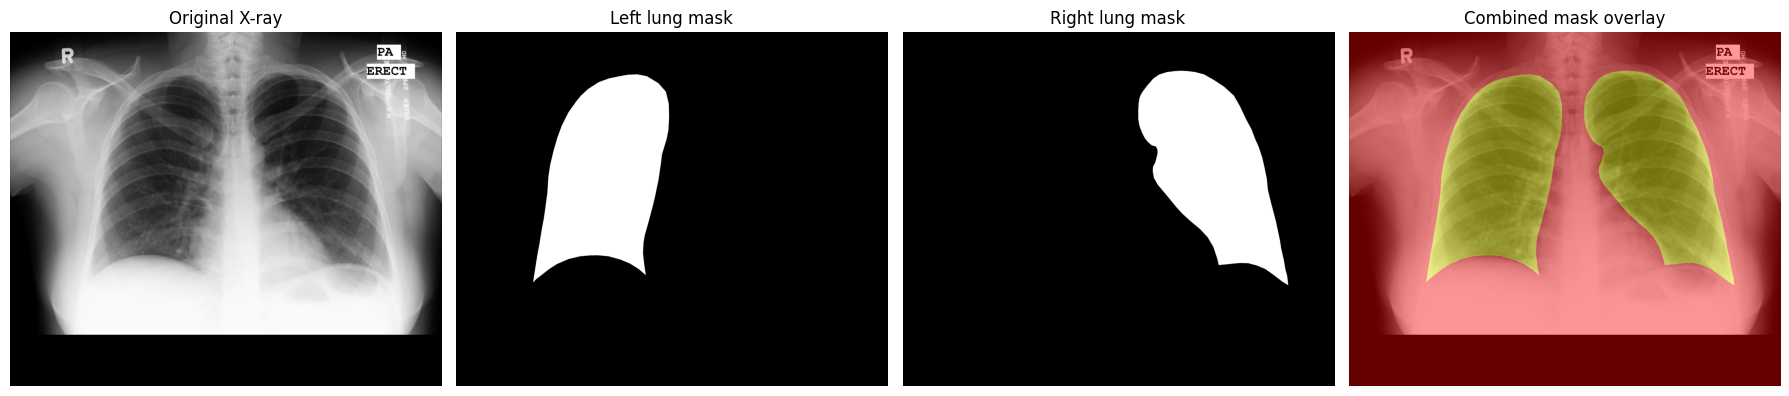

X-ray shape: (4020, 4892)
Combined mask shape: (4020, 4892)
Combined mask unique values: [False  True]
Lung foreground pixel ratio: 0.24171319404612263


In [ ]:

from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

dataset_dir = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research/MontgomerySet"
)

xray_dir = dataset_dir / "CXR_png"
left_dir = dataset_dir / "ManualMask" / "leftMask"
right_dir = dataset_dir / "ManualMask" / "rightMask"

sample_name = "MCUCXR_0001_0.png"

with Image.open(xray_dir / sample_name) as im:
    xray = np.array(im.convert("L"))

with Image.open(left_dir / sample_name) as im:
    left_mask = np.array(im.convert("L"))

with Image.open(right_dir / sample_name) as im:
    right_mask = np.array(im.convert("L"))

# Convert each mask to binary, then combine both lungs.
left_binary = left_mask > 0
right_binary = right_mask > 0
combined_mask = np.logical_or(left_binary, right_binary)

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(xray, cmap="gray")
axes[0].set_title("Original X-ray")

axes[1].imshow(left_mask, cmap="gray")
axes[1].set_title("Left lung mask")

axes[2].imshow(right_mask, cmap="gray")
axes[2].set_title("Right lung mask")

axes[3].imshow(xray, cmap="gray")
axes[3].imshow(combined_mask, cmap="autumn", alpha=0.4)
axes[3].set_title("Combined mask overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("X-ray shape:", xray.shape)
print("Combined mask shape:", combined_mask.shape)
print("Combined mask unique values:", np.unique(combined_mask))
print("Lung foreground pixel ratio:", combined_mask.mean())


Validate dimensions and mask values across all 138 samples

In [ ]:

from pathlib import Path
from PIL import Image
import numpy as np

dataset_dir = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research/MontgomerySet"
)

xray_dir = dataset_dir / "CXR_png"
left_dir = dataset_dir / "ManualMask" / "leftMask"
right_dir = dataset_dir / "ManualMask" / "rightMask"

names = sorted(
    p.name for p in xray_dir.iterdir()
    if p.is_file() and p.suffix.lower() == ".png"
)

issues = []
foreground_ratios = []

for name in names:
    try:
        with Image.open(xray_dir / name) as im:
            xray_size = im.size
            im.verify()

        with Image.open(left_dir / name) as im:
            left = np.array(im.convert("L"))
            left_size = im.size

        with Image.open(right_dir / name) as im:
            right = np.array(im.convert("L"))
            right_size = im.size

        if not (xray_size == left_size == right_size):
            issues.append((name, "dimension mismatch"))
            continue

        combined = (left > 0) | (right > 0)
        ratio = float(combined.mean())
        foreground_ratios.append(ratio)

        if ratio == 0:
            issues.append((name, "empty combined mask"))

    except Exception as exc:
        issues.append((name, str(exc)))

print("Samples checked:", len(names))
print("Issues found:", len(issues))

for issue in issues[:10]:
    print(issue)

if foreground_ratios:
    print(
        "\nForeground ratio min / mean / max:",
        round(min(foreground_ratios), 4),
        round(float(np.mean(foreground_ratios)), 4),
        round(max(foreground_ratios), 4)
    )


Samples checked: 138
Issues found: 0

Foreground ratio min / mean / max: 0.0988 0.2555 0.3977


Create a reproducible train/validation/test split

In [ ]:

import json
import numpy as np
from pathlib import Path

SEED = 42

experiment_dir = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus"
)

# Use the previously verified X-ray filenames.
all_names = sorted(names)

assert len(all_names) == 138
assert len(set(all_names)) == 138

# Deterministic random split.
rng = np.random.default_rng(SEED)
shuffled_names = rng.permutation(all_names).tolist()

train_names = shuffled_names[:110]
val_names = shuffled_names[110:123]
test_names = shuffled_names[123:]

# Verify that splits do not overlap.
assert len(train_names) == 110
assert len(val_names) == 13
assert len(test_names) == 15

assert set(train_names).isdisjoint(val_names)
assert set(train_names).isdisjoint(test_names)
assert set(val_names).isdisjoint(test_names)

assert set(train_names + val_names + test_names) == set(all_names)

split_data = {
    "seed": SEED,
    "method": "numpy default_rng permutation",
    "train": train_names,
    "validation": val_names,
    "test": test_names
}

split_path = experiment_dir / "dataset_split.json"

# Avoid silently overwriting an existing split.
if split_path.exists():
    existing = json.loads(split_path.read_text(encoding="utf-8"))
    assert existing == split_data, (
        "An existing split differs. Stop and inspect before proceeding."
    )
    print("Existing split verified.")
else:
    split_path.write_text(
        json.dumps(split_data, indent=2),
        encoding="utf-8"
    )
    print("New split saved.")

print("\nTraining samples:", len(train_names))
print("Validation samples:", len(val_names))
print("Testing samples:", len(test_names))

print("\nFirst 5 training filenames:")
for name in train_names[:5]:
    print(name)

print("\nSplit saved at:", split_path)


New split saved.

Training samples: 110
Validation samples: 13
Testing samples: 15

First 5 training filenames:
MCUCXR_0144_1.png
MCUCXR_0338_1.png
MCUCXR_0035_0.png
MCUCXR_0038_0.png
MCUCXR_0218_1.png

Split saved at: /content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus/dataset_split.json


inspect the split manifest's structure

In [ ]:
import json
from pathlib import Path

manifest_path = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research/"
    "Attention_UNet/split_manifest.json"
)

with open(manifest_path, "r") as f:
    split = json.load(f)

print("Keys:", list(split.keys()))

for key, value in split.items():
    if isinstance(value, list):
        print(f"{key}: {len(value)} files")
    else:
        print(f"{key}: {type(value).__name__}")

Keys: ['seed', 'split_method', 'dataset', 'train', 'validation', 'test']
seed: int
split_method: str
dataset: str
train: 110 files
validation: 13 files
test: 15 files


verify the UNet++ split format

In [ ]:
import json
from pathlib import Path

project_dir = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research"
)

# Original split — read only
manifest_path = (
    project_dir / "Attention_UNet" / "split_manifest.json"
)

with open(manifest_path, "r", encoding="utf-8") as f:
    original_split = json.load(f)

# Inspect the current UNet++ split without modifying it
current_split_path = (
    project_dir / "UNetPlusPlus" / "dataset_split.json"
)

print("Original split:")
for name in ["train", "validation", "test"]:
    print(f"  {name}: {len(original_split[name])}")

if current_split_path.exists():
    with open(current_split_path, "r", encoding="utf-8") as f:
        current_split = json.load(f)

    print("\nCurrent UNet++ split keys:", list(current_split.keys()))

    for name in ["train", "validation", "test"]:
        if name in current_split:
            print(f"  {name}: {len(current_split[name])}")
else:
    print("\nNo existing dataset_split.json found.")

Original split:
  train: 110
  validation: 13
  test: 15

Current UNet++ split keys: ['seed', 'method', 'train', 'validation', 'test']
  train: 110
  validation: 13
  test: 15


In [1]:
import json
from pathlib import Path

root = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research"
)

with open(root / "Attention_UNet" / "split_manifest.json") as f:
    original = json.load(f)

with open(root / "UNetPlusPlus" / "dataset_split.json") as f:
    current = json.load(f)

for split_name in ["train", "validation", "test"]:
    original_files = original[split_name]
    current_files = current[split_name]

    original_set = set(original_files)
    current_set = set(current_files)

    print(f"\n{split_name.upper()}")
    print("Exact same order:", original_files == current_files)
    print("Same filenames:", original_set == current_set)
    print("Only in original:", len(original_set - current_set))
    print("Only in UNet++:", len(current_set - original_set))

print("\nNo files were modified.")

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Lung_Segmentation_Research/Attention_UNet/split_manifest.json'

In [3]:
from pathlib import Path

root = Path("/content/drive/MyDrive/Lung_Segmentation_Research")

print("Project folder exists:", root.exists())
print("Attention U-Net folder exists:", (root / "Attention_UNet").exists())
print(
    "Original manifest exists:",
    (root / "Attention_UNet" / "split_manifest.json").exists()
)

if root.exists():
    print("\nProject folders:")
    for item in root.iterdir():
        print(item.name)

Project folder exists: True
Attention U-Net folder exists: True
Original manifest exists: True

Project folders:
Attention_UNet
MontgomerySet
__MACOSX
UNetPlusPlus


In [4]:
import json
from pathlib import Path

root = Path("/content/drive/MyDrive/Lung_Segmentation_Research")

with open(root / "Attention_UNet" / "split_manifest.json") as f:
    original = json.load(f)

with open(root / "UNetPlusPlus" / "dataset_split.json") as f:
    current = json.load(f)

for name in ["train", "validation", "test"]:
    a = original[name]
    b = current[name]

    print(f"\n{name.upper()}")
    print("Exact same order:", a == b)
    print("Same filenames:", set(a) == set(b))
    print("Only in original:", sorted(set(a) - set(b))[:5])
    print("Only in UNet++:", sorted(set(b) - set(a))[:5])

print("\nRead-only comparison complete.")


TRAIN
Exact same order: True
Same filenames: True
Only in original: []
Only in UNet++: []

VALIDATION
Exact same order: True
Same filenames: True
Only in original: []
Only in UNet++: []

TEST
Exact same order: True
Same filenames: True
Only in original: []
Only in UNet++: []

Read-only comparison complete.


Inspect the UNet++ data-loading code

In [5]:
from pathlib import Path

model_file = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research/"
    "UNetPlusPlus/unetplusplus_model.py"
)

print("Model file exists:", model_file.exists())

if model_file.exists():
    print("\n--- UNet++ model source ---\n")
    print(model_file.read_text(encoding="utf-8"))
else:
    print("Model source file not found.")

Model file exists: True

--- UNet++ model source ---

import keras
from keras import layers
from keras.regularizers import l2

NB_FILTER = [32, 64, 128, 256, 512]
ACT = "relu"
DROPOUT_RATE = 0.5

def standard_unit(input_tensor, stage, nb_filter, kernel_size=3):
    x = layers.Conv2D(
        nb_filter, (kernel_size, kernel_size),
        activation=ACT,
        name="conv" + stage + "_1",
        kernel_initializer="he_normal",
        padding="same",
        kernel_regularizer=l2(1e-4),
    )(input_tensor)

    x = layers.Dropout(
        DROPOUT_RATE, name="dp" + stage + "_1"
    )(x)

    x = layers.Conv2D(
        nb_filter, (kernel_size, kernel_size),
        activation=ACT,
        name="conv" + stage + "_2",
        kernel_initializer="he_normal",
        padding="same",
        kernel_regularizer=l2(1e-4),
    )(x)

    x = layers.Dropout(
        DROPOUT_RATE, name="dp" + stage + "_2"
    )(x)

    return x


def UNetPlusPlus(img_rows, img_cols, color_type=1,
                 

Find the data-loading code

In [6]:
from pathlib import Path

project_dir = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus"
)

keywords = [
    "dataset_split",
    "split_manifest",
    "ImageDataGenerator",
    "train_files",
    "validation_files",
    "test_files",
    "leftMask",
    "rightMask",
    "CXR_png",
    "cv2.imread",
    "Image.open",
]

for path in sorted(project_dir.glob("*.py")):
    print(f"\n{'=' * 60}")
    print("FILE:", path.name)

    lines = path.read_text(encoding="utf-8").splitlines()
    matches = [
        i for i, line in enumerate(lines)
        if any(keyword.lower() in line.lower() for keyword in keywords)
    ]

    if not matches:
        print("No matching data-loading keywords.")
        continue

    shown = set()
    for i in matches:
        for j in range(max(0, i - 2), min(len(lines), i + 3)):
            if j not in shown:
                print(f"{j + 1:4}: {lines[j]}")
                shown.add(j)
        print("...")


FILE: unetplusplus_model.py
No matching data-loading keywords.


List all UNet++ files

In [7]:
from pathlib import Path

folder = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus"
)

for path in sorted(folder.rglob("*")):
    if path.is_file():
        print(f"{path.relative_to(folder)}  ({path.stat().st_size:,} bytes)")

__pycache__/unetplusplus_model.cpython-313.pyc  (6,222 bytes)
dataset_split.json  (3,566 bytes)
model_config.json  (481 bytes)
unetplusplus_model.py  (5,740 bytes)


Find the data-loading cells in your notebook

In [8]:
import json
from pathlib import Path

# Change this path only if your notebook is saved elsewhere.
notebook_path = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research/"
    "UNetPlusPlus.ipynb"
)

if not notebook_path.exists():
    print("Notebook not found at:", notebook_path)
    print("Tell me where the UNet++ notebook is saved.")
else:
    with open(notebook_path, "r", encoding="utf-8") as f:
        notebook = json.load(f)

    terms = [
        "dataset_split", "CXR_png", "leftMask", "rightMask",
        "cv2.imread", "Image.open", "train_test_split",
        "train_images", "mask", "resize"
    ]

    for i, cell in enumerate(notebook.get("cells", [])):
        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))
        if any(term.lower() in source.lower() for term in terms):
            print(f"\n--- Cell {i} ---")
            print(source[:3500])

Notebook not found at: /content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus.ipynb
Tell me where the UNet++ notebook is saved.


In [9]:
from pathlib import Path

root = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research"
)

print("Searching for notebooks...\n")

for path in root.rglob("*.ipynb"):
    print(path)

Searching for notebooks...



verify Keras data-loading compatibility

In [10]:
import json
from pathlib import Path
import numpy as np
import tensorflow as tf
import keras
from PIL import Image

project_dir = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research"
)
dataset_dir = project_dir / "MontgomerySet"
manifest_path = (
    project_dir / "Attention_UNet" / "split_manifest.json"
)

with open(manifest_path, "r", encoding="utf-8") as f:
    split = json.load(f)

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("NumPy:", np.__version__)

print("\nSplit sizes:")
for name in ("train", "validation", "test"):
    print(f"{name}: {len(split[name])}")

# Inspect one training sample without creating arrays for the whole dataset.
filename = split["train"][0]

with Image.open(dataset_dir / "CXR_png" / filename) as img:
    image = np.asarray(img.convert("RGB").resize(
        (256, 256), Image.Resampling.BILINEAR
    ), dtype=np.float32) / 255.0

with Image.open(dataset_dir / "ManualMask" / "leftMask" / filename) as img:
    left = np.asarray(img.convert("L").resize(
        (256, 256), Image.Resampling.NEAREST
    )) > 0

with Image.open(dataset_dir / "ManualMask" / "rightMask" / filename) as img:
    right = np.asarray(img.convert("L").resize(
        (256, 256), Image.Resampling.NEAREST
    )) > 0

mask = np.logical_or(left, right).astype(np.float32)[..., np.newaxis]
image = image.astype(np.float32)

print("\nSample:", filename)
print("Image shape/dtype:", image.shape, image.dtype)
print("Image range:", float(image.min()), "to", float(image.max()))
print("Mask shape/dtype:", mask.shape, mask.dtype)
print("Mask values:", np.unique(mask).tolist())

TensorFlow: 2.21.0
Keras: 3.13.2
NumPy: 2.1.3

Split sizes:
train: 110
validation: 13
test: 15

Sample: MCUCXR_0144_1.png
Image shape/dtype: (256, 256, 3) float32
Image range: 0.0 to 0.9843137264251709
Mask shape/dtype: (256, 256, 1) float32
Mask values: [0.0, 1.0]


load the complete dataset

In [11]:
import json
from pathlib import Path

import numpy as np
from PIL import Image

project_dir = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research"
)
dataset_dir = project_dir / "MontgomerySet"

with open(
    project_dir / "Attention_UNet" / "split_manifest.json",
    "r",
    encoding="utf-8",
) as f:
    split = json.load(f)

IMG_SIZE = (256, 256)

def load_image(filename):
    path = dataset_dir / "CXR_png" / filename
    with Image.open(path) as img:
        img = img.convert("L").resize(
            IMG_SIZE, Image.Resampling.BILINEAR
        )
        arr = np.asarray(img, dtype=np.float32) / 255.0

    return arr[..., np.newaxis]

def load_mask(filename):
    left_path = dataset_dir / "ManualMask" / "leftMask" / filename
    right_path = dataset_dir / "ManualMask" / "rightMask" / filename

    with Image.open(left_path) as img:
        left = np.asarray(
            img.convert("L").resize(
                IMG_SIZE, Image.Resampling.NEAREST
            )
        ) > 0

    with Image.open(right_path) as img:
        right = np.asarray(
            img.convert("L").resize(
                IMG_SIZE, Image.Resampling.NEAREST
            )
        ) > 0

    combined = np.logical_or(left, right).astype(np.float32)
    return combined[..., np.newaxis]

def load_split(filenames):
    images = np.empty((len(filenames), 256, 256, 1), dtype=np.float32)
    masks = np.empty_like(images)

    for i, filename in enumerate(filenames):
        images[i] = load_image(filename)
        masks[i] = load_mask(filename)

    return images, masks

X_train, Y_train = load_split(split["train"])
X_val, Y_val = load_split(split["validation"])
X_test, Y_test = load_split(split["test"])

print("Train:", X_train.shape, Y_train.shape)
print("Validation:", X_val.shape, Y_val.shape)
print("Test:", X_test.shape, Y_test.shape)

print("\nImage range:", X_train.min(), "to", X_train.max())
print("Mask values:", np.unique(Y_train))
print("All arrays finite:", all(
    np.isfinite(a).all()
    for a in [X_train, Y_train, X_val, Y_val, X_test, Y_test]
))

Train: (110, 256, 256, 1) (110, 256, 256, 1)
Validation: (13, 256, 256, 1) (13, 256, 256, 1)
Test: (15, 256, 256, 1) (15, 256, 256, 1)

Image range: 0.0 to 1.0
Mask values: [0. 1.]
All arrays finite: True


Verify the data visually

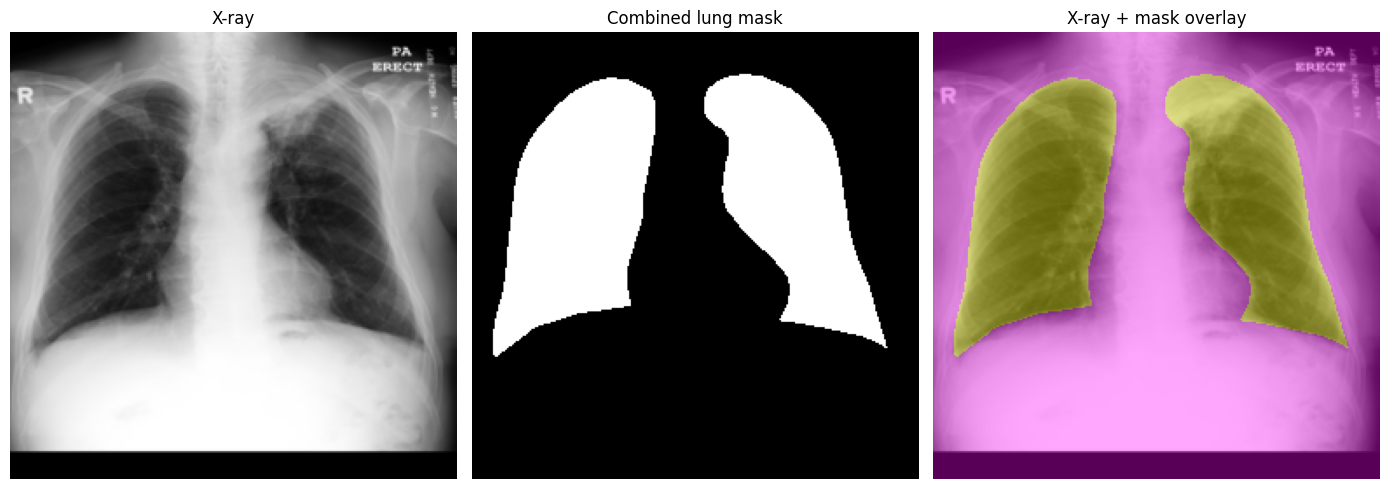

In [12]:
import matplotlib.pyplot as plt
import numpy as np

i = 0

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

axes[0].imshow(X_train[i, ..., 0], cmap="gray")
axes[0].set_title("X-ray")

axes[1].imshow(Y_train[i, ..., 0], cmap="gray")
axes[1].set_title("Combined lung mask")

axes[2].imshow(X_train[i, ..., 0], cmap="gray")
axes[2].imshow(
    Y_train[i, ..., 0],
    cmap="spring",
    alpha=0.35,
    vmin=0,
    vmax=1
)
axes[2].set_title("X-ray + mask overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

Check UNet++ forward-pass compatibility

In [13]:
import keras
import numpy as np
from pathlib import Path
import sys

model_dir = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus"
)

if str(model_dir) not in sys.path:
    sys.path.insert(0, str(model_dir))

from unetplusplus_model import UNetPlusPlus

# Build the existing architecture; no training.
model = UNetPlusPlus(
    img_rows=256,
    img_cols=256,
    color_type=1,
    num_class=1,
    deep_supervision=False
)

# One training image, passed through the model only.
sample = X_train[:1]
prediction = model(sample, training=False)

# With deep supervision disabled, the model returns [output_4].
if isinstance(prediction, (list, tuple)):
    prediction = prediction[-1]

print("Input shape:", sample.shape)
print("Output shape:", prediction.shape)
print("Parameter count:", model.count_params())
print("Output range:", float(np.min(prediction)), "to", float(np.max(prediction)))
print("Output values finite:", bool(np.isfinite(prediction.numpy()).all()))

Input shape: (1, 256, 256, 1)
Output shape: (1, 256, 256, 1)
Parameter count: 9041601
Output range: 0.4487503468990326 to 0.6314957737922668
Output values finite: True


Check the loss and metrics before training

In [14]:
import json
from pathlib import Path

config_path = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research/"
    "UNetPlusPlus/model_config.json"
)

with open(config_path, "r", encoding="utf-8") as f:
    config = json.load(f)

print(json.dumps(config, indent=2))

{
  "model": "UNet++",
  "implementation": "Keras 3 compatibility implementation",
  "input_shape": [
    256,
    256,
    1
  ],
  "filters": [
    32,
    64,
    128,
    256,
    512
  ],
  "activation": "relu",
  "kernel_initializer": "he_normal",
  "dropout_rate": 0.5,
  "l2_regularization": 0.0001,
  "output_activation": "sigmoid",
  "num_classes": 1,
  "deep_supervision": false,
  "total_parameters": 9041601,
  "dataset": "MontgomerySet",
  "training_started": false
}


Inspect the original experiment settings

In [15]:
import json
from pathlib import Path

notebook_path = Path("/content/drive/MyDrive/Lung_Segmentation_Research/2D_Attention_U_Net.ipynb")

if not notebook_path.exists():
    print("Notebook not found at this path.")
    print("No files were changed.")
else:
    with open(notebook_path, "r", encoding="utf-8") as f:
        nb = json.load(f)

    keywords = [
        "learning_rate", "lr =", "batch_size", "epochs",
        "criterion", "BCELoss", "DiceLoss", "optimizer",
        "dice", "iou", "precision", "recall",
        "train_test_split", "split_manifest"
    ]

    for i, cell in enumerate(nb.get("cells", [])):
        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))
        matches = [
            line for line in source.splitlines()
            if any(k.lower() in line.lower() for k in keywords)
        ]

        if matches:
            print(f"\n--- Cell {i} ---")
            print("\n".join(matches[:35]))

Notebook not found at this path.
No files were changed.


Loss and metric sanity check

In [16]:
import tensorflow as tf
import keras

def dice_coefficient(y_true, y_pred, smooth=1e-6):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)

    y_true = tf.reshape(y_true, [-1])
    y_pred = tf.reshape(y_pred, [-1])

    intersection = tf.reduce_sum(y_true * y_pred)
    return (
        2.0 * intersection + smooth
    ) / (
        tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) + smooth
    )

def combined_bce_dice_loss(y_true, y_pred):
    bce = keras.losses.binary_crossentropy(y_true, y_pred)
    dice_loss = 1.0 - dice_coefficient(y_true, y_pred)
    return tf.reduce_mean(bce) + dice_loss

# Use one existing training sample; no optimizer step occurs.
sample_x = tf.convert_to_tensor(X_train[:1], dtype=tf.float32)
sample_y = tf.convert_to_tensor(Y_train[:1], dtype=tf.float32)

prediction = model(sample_x, training=False)

if isinstance(prediction, (list, tuple)):
    prediction = prediction[-1]

loss_value = combined_bce_dice_loss(sample_y, prediction)
dice_value = dice_coefficient(sample_y, prediction)
iou_value = (
    dice_value / (2.0 - dice_value + 1e-7)
)

print("Combined loss:", float(loss_value.numpy()))
print("Dice coefficient:", float(dice_value.numpy()))
print("IoU:", float(iou_value.numpy()))
print("All results finite:", bool(
    tf.reduce_all(tf.math.is_finite([
        loss_value, dice_value, iou_value
    ])).numpy()
))

Combined loss: 1.372882604598999
Dice coefficient: 0.35399577021598816
IoU: 0.2150636911392212
All results finite: True


Prepare the experiment folder

In [17]:
from pathlib import Path

experiment_dir = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus"
)

folders = [
    "checkpoints",
    "logs",
    "plots",
    "predictions",
]

experiment_dir.mkdir(parents=True, exist_ok=True)

for name in folders:
    path = experiment_dir / name
    path.mkdir(exist_ok=True)
    print(f"{name}: {path}")

print("\nExperiment folder prepared.")

checkpoints: /content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus/checkpoints
logs: /content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus/logs
plots: /content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus/plots
predictions: /content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus/predictions

Experiment folder prepared.


Pre-training readiness check

In [18]:
from pathlib import Path
import numpy as np

experiment_dir = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus"
)

required_variables = [
    "model",
    "X_train", "Y_train",
    "X_val", "Y_val",
    "X_test", "Y_test",
]

print("Experiment directory exists:", experiment_dir.exists())

print("\nVariable readiness:")
for name in required_variables:
    print(f"{name}: {'available' if name in globals() else 'MISSING'}")

if all(name in globals() for name in required_variables):
    print("\nArray shapes:")
    for name in ["X_train", "Y_train", "X_val", "Y_val", "X_test", "Y_test"]:
        print(f"{name}: {globals()[name].shape}")

    print("\nModel parameters:", model.count_params())
    print("Model output shape:", model.output_shape)

print("\nCheckpoint files already present:")
for path in sorted((experiment_dir / "checkpoints").glob("*")):
    print(path.name)

Experiment directory exists: True

Variable readiness:
model: available
X_train: available
Y_train: available
X_val: available
Y_val: available
X_test: available
Y_test: available

Array shapes:
X_train: (110, 256, 256, 1)
Y_train: (110, 256, 256, 1)
X_val: (13, 256, 256, 1)
Y_val: (13, 256, 256, 1)
X_test: (15, 256, 256, 1)
Y_test: (15, 256, 256, 1)

Model parameters: 9041601
Model output shape: (None, 256, 256, 1)

Checkpoint files already present:


Compile the model

In [19]:
import keras
import tensorflow as tf

def dice_coefficient(y_true, y_pred, smooth=1e-6):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)

    y_true = tf.reshape(y_true, [-1])
    y_pred = tf.reshape(y_pred, [-1])

    intersection = tf.reduce_sum(y_true * y_pred)

    return (
        2.0 * intersection + smooth
    ) / (
        tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) + smooth
    )

def combined_bce_dice_loss(y_true, y_pred):
    bce = keras.losses.binary_crossentropy(y_true, y_pred)
    dice_loss = 1.0 - dice_coefficient(y_true, y_pred)
    return tf.reduce_mean(bce) + dice_loss

# Deep supervision is disabled, so compile against the final output.
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0002),
    loss=combined_bce_dice_loss,
    metrics=[
        keras.metrics.BinaryAccuracy(name="binary_accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        dice_coefficient,
    ],
)

print("Model compiled successfully.")
print("Optimizer: Adam")
print("Learning rate: 0.0002")
print("Loss: Binary Cross-Entropy + Dice Loss")
print("Training has NOT started.")

Model compiled successfully.
Optimizer: Adam
Learning rate: 0.0002
Loss: Binary Cross-Entropy + Dice Loss
Training has NOT started.


Start training with full checkpointing

In [20]:

import os
import csv
import json
import time
import numpy as np
from pathlib import Path
import keras
import tensorflow as tf

experiment_dir = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus"
)
checkpoint_dir = experiment_dir / "checkpoints"
log_dir = experiment_dir / "logs"
checkpoint_dir.mkdir(parents=True, exist_ok=True)
log_dir.mkdir(parents=True, exist_ok=True)

# Avoid overwriting any existing run artifacts.
run_id = time.strftime("%Y%m%d_%H%M%S")
run_dir = checkpoint_dir / f"run_{run_id}"
run_dir.mkdir(exist_ok=False)

best_path = run_dir / "best_model.keras"
csv_path = log_dir / f"training_history_{run_id}.csv"
json_path = log_dir / f"training_history_{run_id}.json"
config_path = log_dir / f"training_config_{run_id}.json"

config = {
    "model": "UNet++",
    "input_shape": [256, 256, 1],
    "train_samples": len(X_train),
    "validation_samples": len(X_val),
    "test_samples": len(X_test),
    "epochs": 20,
    "batch_size": 2,
    "optimizer": "Adam",
    "learning_rate": 0.0002,
    "loss": "Binary Cross-Entropy + Dice Loss",
    "best_checkpoint_monitor": "val_dice_coefficient",
    "checkpoint_policy": "Save each completed epoch; preserve best validation Dice",
    "run_id": run_id
}

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2)

# Save every epoch and preserve the best validation-Dice model.
class SaveEpochAndBest(keras.callbacks.Callback):
    def __init__(self, run_dir, best_path):
        super().__init__()
        self.run_dir = Path(run_dir)
        self.best_path = Path(best_path)
        self.best_dice = -np.inf
        self.history_rows = []

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        epoch_num = epoch + 1

        # Complete model checkpoint, including optimizer state.
        epoch_path = self.run_dir / f"epoch_{epoch_num:02d}.keras"
        self.model.save(epoch_path)

        row = {"epoch": epoch_num}
        row.update({k: float(v) for k, v in logs.items()})
        self.history_rows.append(row)

        val_dice = logs.get("val_dice_coefficient")
        if val_dice is not None and float(val_dice) > self.best_dice:
            self.best_dice = float(val_dice)
            self.model.save(self.best_path)
            print(f"Saved new best checkpoint: val Dice={self.best_dice:.5f}")

        # Rewrite CSV after each epoch so progress is retained.
        fieldnames = sorted(set().union(*(r.keys() for r in self.history_rows)))
        with open(csv_path, "w", newline="", encoding="utf-8") as f:
            writer = csv.DictWriter(f, fieldnames=fieldnames)
            writer.writeheader()
            writer.writerows(self.history_rows)

        with open(json_path, "w", encoding="utf-8") as f:
            json.dump(self.history_rows, f, indent=2)

        print(f"Saved epoch checkpoint: {epoch_path.name}")

callbacks = [
    SaveEpochAndBest(run_dir, best_path),
    keras.callbacks.TerminateOnNaN(),
]

print("Starting UNet++ training")
print("Run folder:", run_dir)
print("Epoch checkpoints: enabled")
print("Best checkpoint:", best_path)
print("CSV history:", csv_path)
print("JSON history:", json_path)

history = model.fit(
    X_train, Y_train,
    validation_data=(X_val, Y_val),
    epochs=20,
    batch_size=2,
    shuffle=True,
    callbacks=callbacks,
    verbose=1
)

print("\nTraining completed.")
print("Best model:", best_path)
print("History CSV:", csv_path)
print("History JSON:", json_path)


Starting UNet++ training
Run folder: /content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus/checkpoints/run_20261022_090555
Epoch checkpoints: enabled
Best checkpoint: /content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus/checkpoints/run_20261022_090555/best_model.keras
CSV history: /content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus/logs/training_history_20261022_090555.csv
JSON history: /content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus/logs/training_history_20261022_090555.json
Epoch 1/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step - binary_accuracy: 0.5572 - dice_coefficient: 0.3283 - loss: 4.0191 - precision: 0.2524 - recall: 0.3732Saved new best checkpoint: val Dice=0.33791
Saved epoch checkpoint: epoch_01.keras
55/55 ━━━━━━━━━━━━━━━━━━━━ 84s 420ms/step - binary_accuracy: 0.6296 - dice_coefficient: 0.3207 - loss: 2.5686 - precision: 0.2576 - recall: 0.2413 - val_binary_accuracy: 0.7448 - val_dice_coefficient: 0.3379 - val_loss: 2.0158 - val_pr

Inspect the saved training history

In [21]:
import pandas as pd
from pathlib import Path

history_path = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research/"
    "UNetPlusPlus/logs/training_history_20261022_090555.csv"
)

history_df = pd.read_csv(history_path)

print("History shape:", history_df.shape)
print("\nAvailable columns:")
print(history_df.columns.tolist())

print("\nBest validation Dice:")
print(history_df.loc[
    history_df["val_dice_coefficient"].idxmax(),
    ["epoch", "dice_coefficient", "val_dice_coefficient",
     "loss", "val_loss", "val_precision", "val_recall"]
].to_string())

print("\nLast 5 epochs:")
display(history_df.tail())

History shape: (20, 11)

Available columns:
['binary_accuracy', 'dice_coefficient', 'epoch', 'loss', 'precision', 'recall', 'val_binary_accuracy', 'val_dice_coefficient', 'val_loss', 'val_precision', 'val_recall']

Best validation Dice:
epoch                   10.000000
dice_coefficient         0.806274
val_dice_coefficient     0.531700
loss                     0.991203
val_loss                 3.783710
val_precision            0.359749
val_recall               0.997043

Last 5 epochs:


,binary_accuracy,dice_coefficient,epoch,loss,precision,recall,val_binary_accuracy,val_dice_coefficient,val_loss,val_precision,val_recall
15,0.948575,0.855128,16,0.814393,0.936797,0.855873,0.502539,0.518366,3.924099,0.338997,0.999250
16,0.950139,0.860947,17,0.792508,0.940099,0.859001,0.509823,0.520472,4.072494,0.342328,0.999402
17,0.951002,0.862637,18,0.772744,0.937134,0.865731,0.538093,0.530225,3.607343,0.355831,0.999425
18,0.951308,0.868859,19,0.757148,0.936958,0.867207,0.533850,0.527282,3.701530,0.353795,0.999986
19,0.953129,0.868659,20,0.740879,0.940173,0.871460,0.508259,0.515477,4.083101,0.341671,0.999963


Plot the learning curves

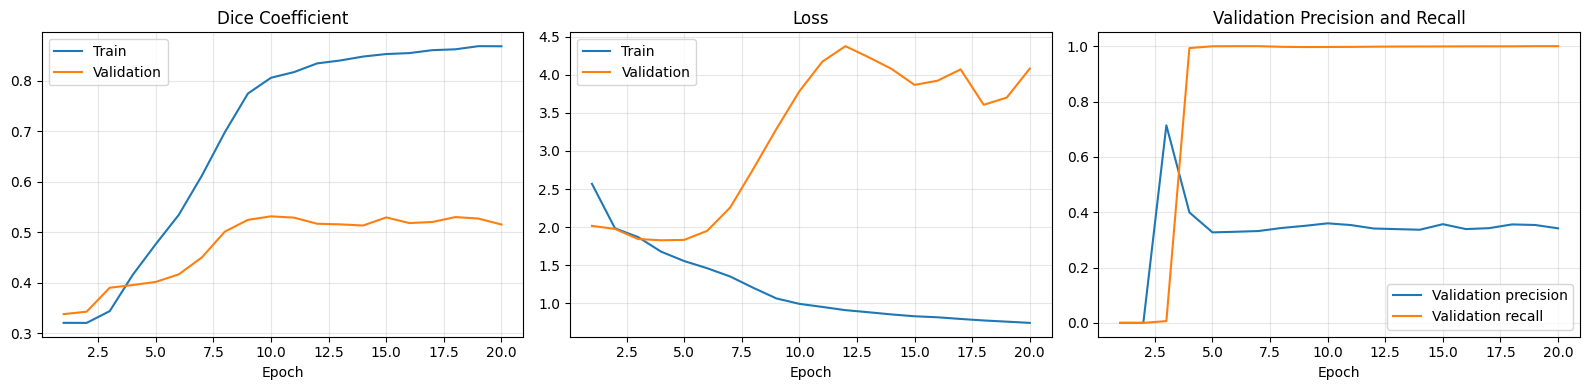

Best validation Dice: 0.5317
Best epoch: 10


In [22]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

history_path = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research/"
    "UNetPlusPlus/logs/training_history_20261022_090555.csv"
)

assert history_path.exists(), (
    f"History file not found: {history_path}\n"
    "Check that Google Drive is mounted."
)

history_df = pd.read_csv(history_path)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot(history_df["epoch"], history_df["dice_coefficient"], label="Train")
axes[0].plot(history_df["epoch"], history_df["val_dice_coefficient"], label="Validation")
axes[0].set_title("Dice Coefficient")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history_df["epoch"], history_df["loss"], label="Train")
axes[1].plot(history_df["epoch"], history_df["val_loss"], label="Validation")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

axes[2].plot(history_df["epoch"], history_df["val_precision"], label="Validation precision")
axes[2].plot(history_df["epoch"], history_df["val_recall"], label="Validation recall")
axes[2].set_title("Validation Precision and Recall")
axes[2].set_xlabel("Epoch")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Best validation Dice:",
      round(history_df["val_dice_coefficient"].max(), 4))
print("Best epoch:",
      int(history_df.loc[history_df["val_dice_coefficient"].idxmax(), "epoch"]))

Inspect predictions from the best checkpoint

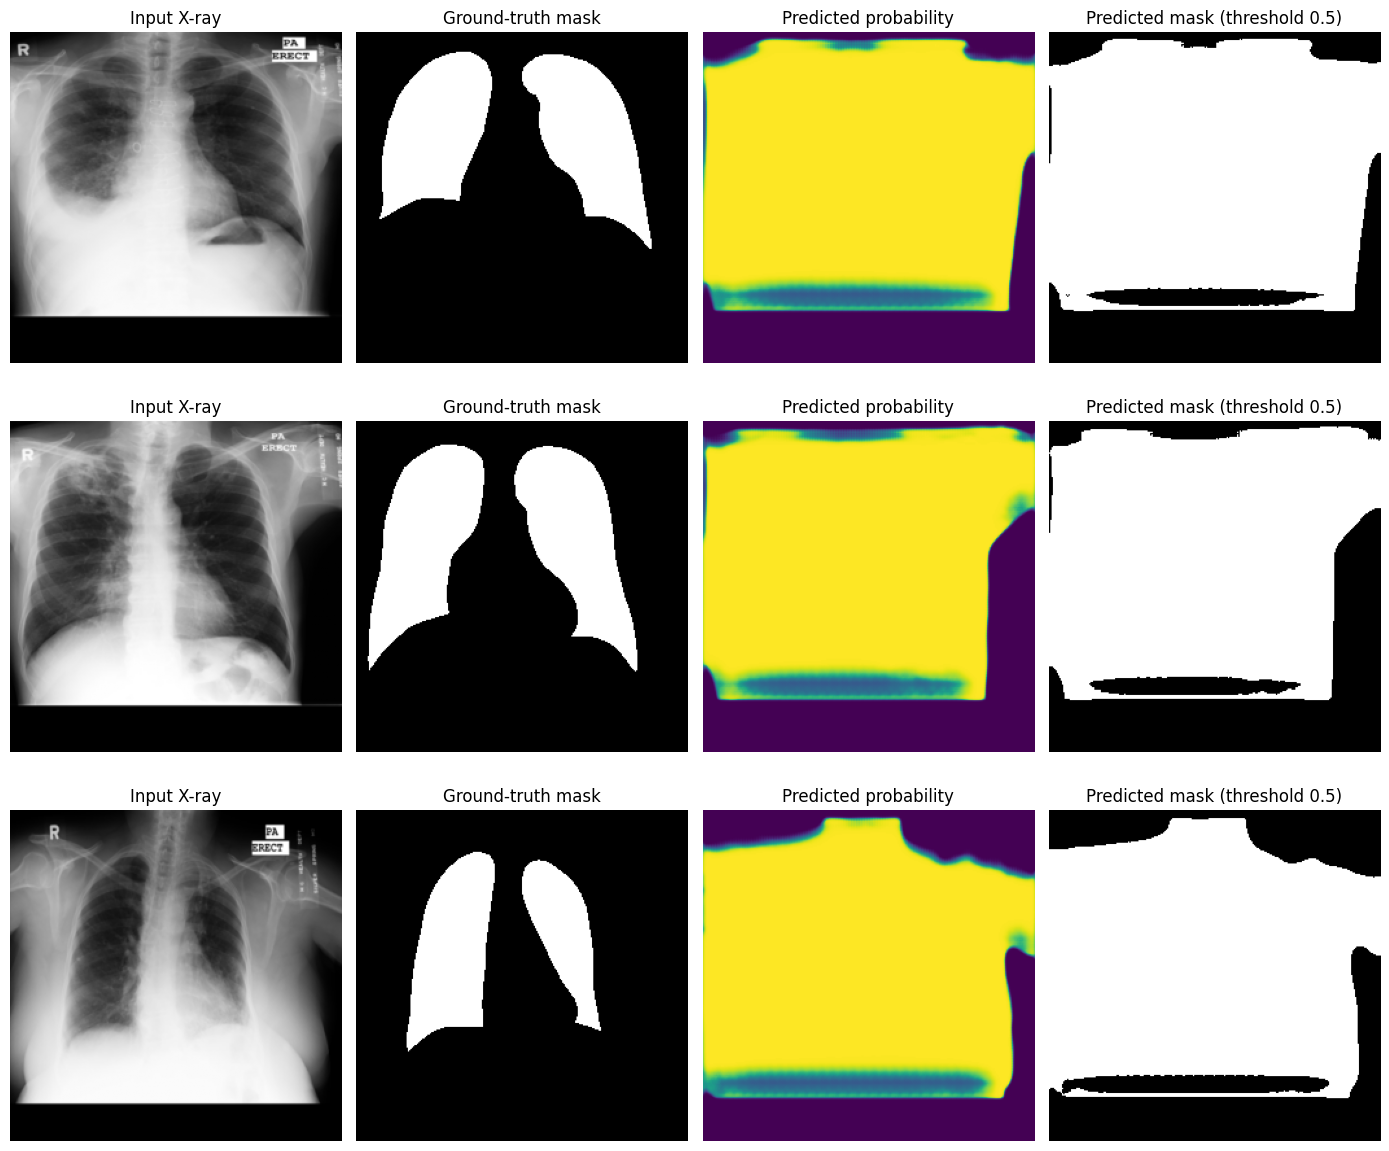

Probability range: 0.0 to 0.9996401071548462
Mean predicted foreground fraction: 0.7011
Mean ground-truth foreground fraction: 0.2552


In [23]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path
from tensorflow import keras

best_path = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research/"
    "UNetPlusPlus/checkpoints/run_20261022_090555/best_model.keras"
)

assert best_path.exists(), f"Checkpoint not found: {best_path}"

# Custom loss/metric functions used when the model was compiled
best_model = keras.models.load_model(
    best_path,
    custom_objects={
        "combined_bce_dice_loss": combined_bce_dice_loss,
        "dice_coefficient": dice_coefficient,
    },
    compile=False,
)

# Predict on three validation images
n = min(3, len(X_val))
raw_predictions = best_model.predict(X_val[:n], verbose=0)

# UNet++ may return its single output inside a list
if isinstance(raw_predictions, (list, tuple)):
    raw_predictions = raw_predictions[-1]

probabilities = np.asarray(raw_predictions)
binary_predictions = (probabilities >= 0.5).astype(np.float32)

fig, axes = plt.subplots(n, 4, figsize=(14, 4 * n))
if n == 1:
    axes = np.expand_dims(axes, axis=0)

for i in range(n):
    axes[i, 0].imshow(X_val[i, :, :, 0], cmap="gray")
    axes[i, 0].set_title("Input X-ray")

    axes[i, 1].imshow(Y_val[i, :, :, 0], cmap="gray", vmin=0, vmax=1)
    axes[i, 1].set_title("Ground-truth mask")

    axes[i, 2].imshow(probabilities[i, :, :, 0], cmap="viridis", vmin=0, vmax=1)
    axes[i, 2].set_title("Predicted probability")

    axes[i, 3].imshow(binary_predictions[i, :, :, 0], cmap="gray", vmin=0, vmax=1)
    axes[i, 3].set_title("Predicted mask (threshold 0.5)")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

print("Probability range:",
      float(probabilities.min()), "to", float(probabilities.max()))
print("Mean predicted foreground fraction:",
      round(float(binary_predictions.mean()), 4))
print("Mean ground-truth foreground fraction:",
      round(float(Y_val.mean()), 4))

Check the masks and probability distributions

In [24]:
import numpy as np

# Ground-truth and probability arrays from the best checkpoint
y_true = Y_val[:len(probabilities), :, :, 0]
y_prob = probabilities[:, :, :, 0]

print("Ground-truth mask values:", np.unique(y_true))
print("Prediction probability range:",
      float(y_prob.min()), "to", float(y_prob.max()))

print("\nProbability distribution by ground-truth region:")
for name, region in [
    ("Background", y_true == 0),
    ("Lung foreground", y_true == 1),
]:
    values = y_prob[region]
    print(
        f"{name}: "
        f"mean={values.mean():.4f}, "
        f"median={np.median(values):.4f}, "
        f"p10={np.percentile(values, 10):.4f}, "
        f"p90={np.percentile(values, 90):.4f}"
    )

print("\nPredicted foreground fraction at different thresholds:")
for threshold in [0.3, 0.5, 0.7, 0.9]:
    predicted = y_prob >= threshold
    print(f"Threshold {threshold:.1f}: {predicted.mean():.4f}")

print("\nGround-truth foreground fraction:", float(y_true.mean()))

Ground-truth mask values: [0. 1.]
Prediction probability range: 0.0 to 0.9996401071548462

Probability distribution by ground-truth region:
Background: mean=0.6179, median=0.9891, p10=0.0000, p90=0.9993
Lung foreground: mean=0.9989, median=0.9989, p10=0.9987, p90=0.9993

Predicted foreground fraction at different thresholds:
Threshold 0.3: 0.7400
Threshold 0.5: 0.7011
Threshold 0.7: 0.6772
Threshold 0.9: 0.6495

Ground-truth foreground fraction: 0.2208709716796875


Verify the mask-loading pipeline

Validation filename: MCUCXR_0362_1.png
Original left mask foreground: 0.1145
Original right mask foreground: 0.1199
Combined expected foreground: 0.2342
Combined loaded foreground: 0.2342
Masks match: True


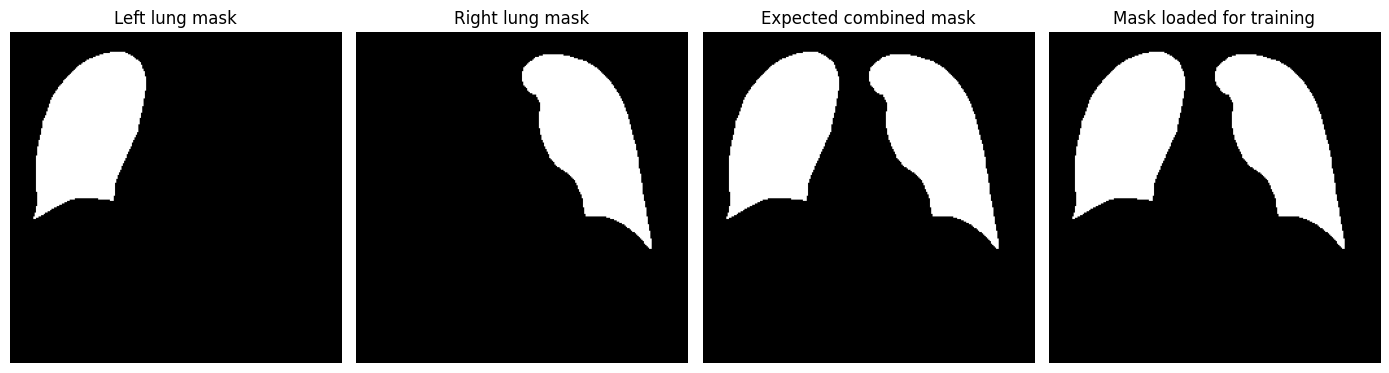

In [25]:
from PIL import Image
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

dataset_dir = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research/MontgomerySet"
)

# Select the first validation example
filename = split["validation"][0]

left_path = dataset_dir / "ManualMask" / "leftMask" / filename
right_path = dataset_dir / "ManualMask" / "rightMask" / filename

with Image.open(left_path) as img:
    left_original = np.asarray(img.convert("L")) > 0

with Image.open(right_path) as img:
    right_original = np.asarray(img.convert("L")) > 0

left_resized = np.asarray(
    Image.fromarray(left_original.astype(np.uint8) * 255).resize(
        (256, 256), Image.Resampling.NEAREST
    )
) > 0

right_resized = np.asarray(
    Image.fromarray(right_original.astype(np.uint8) * 255).resize(
        (256, 256), Image.Resampling.NEAREST
    )
) > 0

combined_expected = np.logical_or(left_resized, right_resized)
combined_loaded = Y_val[0, :, :, 0] > 0.5

print("Validation filename:", filename)
print("Original left mask foreground:", round(left_original.mean(), 4))
print("Original right mask foreground:", round(right_original.mean(), 4))
print("Combined expected foreground:", round(combined_expected.mean(), 4))
print("Combined loaded foreground:", round(combined_loaded.mean(), 4))
print("Masks match:", np.array_equal(combined_expected, combined_loaded))

fig, axes = plt.subplots(1, 4, figsize=(14, 4))

axes[0].imshow(left_resized, cmap="gray")
axes[0].set_title("Left lung mask")

axes[1].imshow(right_resized, cmap="gray")
axes[1].set_title("Right lung mask")

axes[2].imshow(combined_expected, cmap="gray")
axes[2].set_title("Expected combined mask")

axes[3].imshow(combined_loaded, cmap="gray")
axes[3].set_title("Mask loaded for training")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

Inspect the UNet++ output and training configuration

In [26]:
import json
from pathlib import Path

experiment_dir = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus"
)

config_path = experiment_dir / "model_config.json"

with open(config_path, "r") as f:
    model_config = json.load(f)

print("Saved model configuration:")
print(json.dumps(model_config, indent=2))

print("\nModel output names:", best_model.output_names)
print("Model output shape:", best_model.output_shape)
print("Model input shape:", best_model.input_shape)

print("\nFinal layer:")
print("Name:", best_model.layers[-1].name)
print("Class:", type(best_model.layers[-1]).__name__)
print("Activation:",
      getattr(getattr(best_model.layers[-1], "activation", None),
              "__name__", "not directly available"))

print("\nTraining configuration:")
print("Optimizer: Adam")
print("Learning rate: 0.0002")
print("Batch size: 2")
print("Epochs completed: 20")
print("Loss: Binary Cross-Entropy + Dice Loss")
print("Best validation Dice: 0.5317 at epoch 10")

Saved model configuration:
{
  "model": "UNet++",
  "implementation": "Keras 3 compatibility implementation",
  "input_shape": [
    256,
    256,
    1
  ],
  "filters": [
    32,
    64,
    128,
    256,
    512
  ],
  "activation": "relu",
  "kernel_initializer": "he_normal",
  "dropout_rate": 0.5,
  "l2_regularization": 0.0001,
  "output_activation": "sigmoid",
  "num_classes": 1,
  "deep_supervision": false,
  "total_parameters": 9041601,
  "dataset": "MontgomerySet",
  "training_started": false
}

Model output names: ListWrapper(['output_4'])
Model output shape: (None, 256, 256, 1)
Model input shape: (None, 256, 256, 1)

Final layer:
Name: output_4
Class: Conv2D
Activation: sigmoid

Training configuration:
Optimizer: Adam
Learning rate: 0.0002
Batch size: 2
Epochs completed: 20
Loss: Binary Cross-Entropy + Dice Loss
Best validation Dice: 0.5317 at epoch 10


Check whether predictions are saturated across the image

In [27]:
import numpy as np

# Predict on the complete validation set
val_probs = best_model.predict(X_val, batch_size=2, verbose=1)

if isinstance(val_probs, (list, tuple)):
    val_probs = val_probs[-1]

val_probs = np.asarray(val_probs)[..., 0]
val_masks = Y_val[..., 0]

background_probs = val_probs[val_masks == 0]
lung_probs = val_probs[val_masks == 1]

print("\n=== Full validation-set probability diagnostics ===")
print("Validation images:", len(X_val))
print("Background pixels:", len(background_probs))
print("Lung pixels:", len(lung_probs))

print("\nBackground probability percentiles:")
print(np.percentile(background_probs, [0, 10, 25, 50, 75, 90, 99, 100]))

print("\nLung probability percentiles:")
print(np.percentile(lung_probs, [0, 10, 25, 50, 75, 90, 99, 100]))

print("\nMean foreground fraction:")
print("Ground truth:", round(float(val_masks.mean()), 4))
print("Prediction at 0.5:", round(float((val_probs >= 0.5).mean()), 4))

print("\nPer-image foreground fractions:")
for i in range(len(X_val)):
    actual = float(val_masks[i].mean())
    predicted = float((val_probs[i] >= 0.5).mean())
    print(f"{i + 1:02d}. actual={actual:.3f}, predicted={predicted:.3f}")

7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 226ms/step

=== Full validation-set probability diagnostics ===
Validation images: 13
Background pixels: 634531
Lung pixels: 217437

Background probability percentiles:
[0.00000000e+00 0.00000000e+00 1.14898140e-19 9.90464032e-01
 9.99105513e-01 9.99321461e-01 9.99435365e-01 9.99683797e-01]

Lung probability percentiles:
[1.37542522e-09 9.98622775e-01 9.98770416e-01 9.98943508e-01
 9.99132872e-01 9.99304295e-01 9.99471188e-01 9.99619842e-01]

Mean foreground fraction:
Ground truth: 0.2552
Prediction at 0.5: 0.7073

Per-image foreground fractions:
01. actual=0.234, predicted=0.728
02. actual=0.262, predicted=0.691
03. actual=0.167, predicted=0.684
04. actual=0.371, predicted=0.938
05. actual=0.195, predicted=0.549
06. actual=0.270, predicted=0.790
07. actual=0.349, predicted=0.883
08. actual=0.246, predicted=0.640
09. actual=0.233, predicted=0.561
10. actual=0.232, predicted=0.645
11. actual=0.257, predicted=0.710
12. actual=0.227, predicted=0.700
13. actual=

In [28]:
import inspect

print("=== Loss function source ===")
print(inspect.getsource(combined_bce_dice_loss))

print("\n=== Dice metric source ===")
print(inspect.getsource(dice_coefficient))

print("\n=== Current model compile configuration ===")
print("Output names:", best_model.output_names)
print("Output shape:", best_model.output_shape)
print("Target shape:", Y_train.shape)
print("Target values:", np.unique(Y_train))

print("\n=== Saved training configuration ===")
import json
from pathlib import Path

config_path = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research/"
    "UNetPlusPlus/logs/training_config_20261022_090555.json"
)

if config_path.exists():
    print(json.dumps(json.loads(config_path.read_text()), indent=2))
else:
    print("Training config JSON not found at the expected path.")

=== Loss function source ===
def combined_bce_dice_loss(y_true, y_pred):
    bce = keras.losses.binary_crossentropy(y_true, y_pred)
    dice_loss = 1.0 - dice_coefficient(y_true, y_pred)
    return tf.reduce_mean(bce) + dice_loss


=== Dice metric source ===
def dice_coefficient(y_true, y_pred, smooth=1e-6):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)

    y_true = tf.reshape(y_true, [-1])
    y_pred = tf.reshape(y_pred, [-1])

    intersection = tf.reduce_sum(y_true * y_pred)

    return (
        2.0 * intersection + smooth
    ) / (
        tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) + smooth
    )


=== Current model compile configuration ===
Output names: ListWrapper(['output_4'])
Output shape: (None, 256, 256, 1)
Target shape: (110, 256, 256, 1)
Target values: [0. 1.]

=== Saved training configuration ===
{
  "model": "UNet++",
  "input_shape": [
    256,
    256,
    1
  ],
  "train_samples": 110,
  "validation_samples": 13,
  "test_sample

Evaluate BCE and Dice loss separately

In [29]:
import numpy as np
import tensorflow as tf
from tensorflow import keras

# Get predictions from the saved best model
val_pred = best_model.predict(X_val, batch_size=2, verbose=0)

if isinstance(val_pred, (list, tuple)):
    val_pred = val_pred[-1]

y_true_tf = tf.convert_to_tensor(Y_val, dtype=tf.float32)
y_pred_tf = tf.convert_to_tensor(val_pred, dtype=tf.float32)

# Separate loss components
bce_values = keras.losses.binary_crossentropy(y_true_tf, y_pred_tf)
bce_mean = tf.reduce_mean(bce_values).numpy()

dice_value = dice_coefficient(y_true_tf, y_pred_tf).numpy()
dice_loss_value = 1.0 - dice_value

combined_loss = bce_mean + dice_loss_value

# Thresholded Dice, computed across the complete validation set
binary_pred = tf.cast(y_pred_tf >= 0.5, tf.float32)
intersection = tf.reduce_sum(y_true_tf * binary_pred)
thresholded_dice = (
    2.0 * intersection + 1e-6
) / (
    tf.reduce_sum(y_true_tf) + tf.reduce_sum(binary_pred) + 1e-6
)

print("Validation BCE:", round(float(bce_mean), 5))
print("Soft Dice:", round(float(dice_value), 5))
print("Dice loss:", round(float(dice_loss_value), 5))
print("Combined loss:", round(float(combined_loss), 5))
print("Thresholded Dice at 0.5:", round(float(thresholded_dice.numpy()), 5))

Validation BCE: 2.74035
Soft Dice: 0.52734
Dice loss: 0.47266
Combined loss: 3.21302
Thresholded Dice at 0.5: 0.52873


Check the model's final output and decoder implementation

In [30]:
from pathlib import Path

model_file = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research/"
    "UNetPlusPlus/unetplusplus_model.py"
)

source = model_file.read_text()

lines = source.splitlines()

keywords = [
    "def UNetPlusPlus",
    "def standard_unit",
    "output_4",
    "Conv2D",
    "Concatenate",
    "UpSampling2D",
    "Conv2DTranspose",
]

print("Model source:", model_file)
print("Total lines:", len(lines))

for keyword in keywords:
    matches = [
        i for i, line in enumerate(lines)
        if keyword in line
    ]
    print(f"\n--- {keyword}: {len(matches)} match(es) ---")
    for i in matches[:4]:
        start = max(0, i - 3)
        end = min(len(lines), i + 5)
        for j in range(start, end):
            print(f"{j + 1:4}: {lines[j]}")
        print()

Model source: /content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus/unetplusplus_model.py
Total lines: 192

--- def UNetPlusPlus: 1 match(es) ---
  36:     return x
  37: 
  38: 
  39: def UNetPlusPlus(img_rows, img_cols, color_type=1,
  40:                  num_class=1, deep_supervision=False):
  41: 
  42:     bn_axis = 3
  43:     img_input = layers.Input(


--- def standard_unit: 1 match(es) ---
   6: ACT = "relu"
   7: DROPOUT_RATE = 0.5
   8: 
   9: def standard_unit(input_tensor, stage, nb_filter, kernel_size=3):
  10:     x = layers.Conv2D(
  11:         nb_filter, (kernel_size, kernel_size),
  12:         activation=ACT,
  13:         name="conv" + stage + "_1",


--- output_4: 4 match(es) ---
 178:         padding="same", kernel_regularizer=l2(1e-4)
 179:     )(conv1_4)
 180: 
 181:     output_4 = layers.Conv2D(
 182:         num_class, (1, 1), activation="sigmoid",
 183:         name="output_4", kernel_initializer="he_normal",
 184:         padding="same", kernel_re

Check training on a tiny subset

In [31]:
import tensorflow as tf
from tensorflow import keras
from pathlib import Path
import numpy as np

# Create a fresh diagnostic model with the same architecture
diagnostic_model = UNetPlusPlus(
    img_rows=256,
    img_cols=256,
    color_type=1,
    num_class=1,
    deep_supervision=False,
)

diagnostic_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0002),
    loss=combined_bce_dice_loss,
)

# Small fixed subset, used only for diagnosis
X_tiny = X_train[:4]
Y_tiny = Y_train[:4]

print("Diagnostic subset:", X_tiny.shape, Y_tiny.shape)

# Record loss before fitting
before = diagnostic_model.evaluate(
    X_tiny, Y_tiny, batch_size=2, verbose=0
)

# Train only the diagnostic model for 5 epochs
diagnostic_history = diagnostic_model.fit(
    X_tiny,
    Y_tiny,
    batch_size=2,
    epochs=5,
    shuffle=False,
    verbose=1,
)

after = diagnostic_model.evaluate(
    X_tiny, Y_tiny, batch_size=2, verbose=0
)

print("\nInitial tiny-subset loss:", float(before))
print("Final tiny-subset loss:", float(after))
print("Epoch losses:", diagnostic_history.history["loss"])

Diagnostic subset: (4, 256, 256, 1) (4, 256, 256, 1)
Epoch 1/5
2/2 ━━━━━━━━━━━━━━━━━━━━ 33s 213ms/step - loss: 17.1719
Epoch 2/5
2/2 ━━━━━━━━━━━━━━━━━━━━ 19s 207ms/step - loss: 6.1352
Epoch 3/5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 200ms/step - loss: 3.8911
Epoch 4/5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 200ms/step - loss: 3.0280
Epoch 5/5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 197ms/step - loss: 2.6179

Initial tiny-subset loss: 1.9623111486434937
Final tiny-subset loss: 2.0644896030426025
Epoch losses: [17.17194938659668, 6.135194778442383, 3.8911428451538086, 3.0279946327209473, 2.6179440021514893]


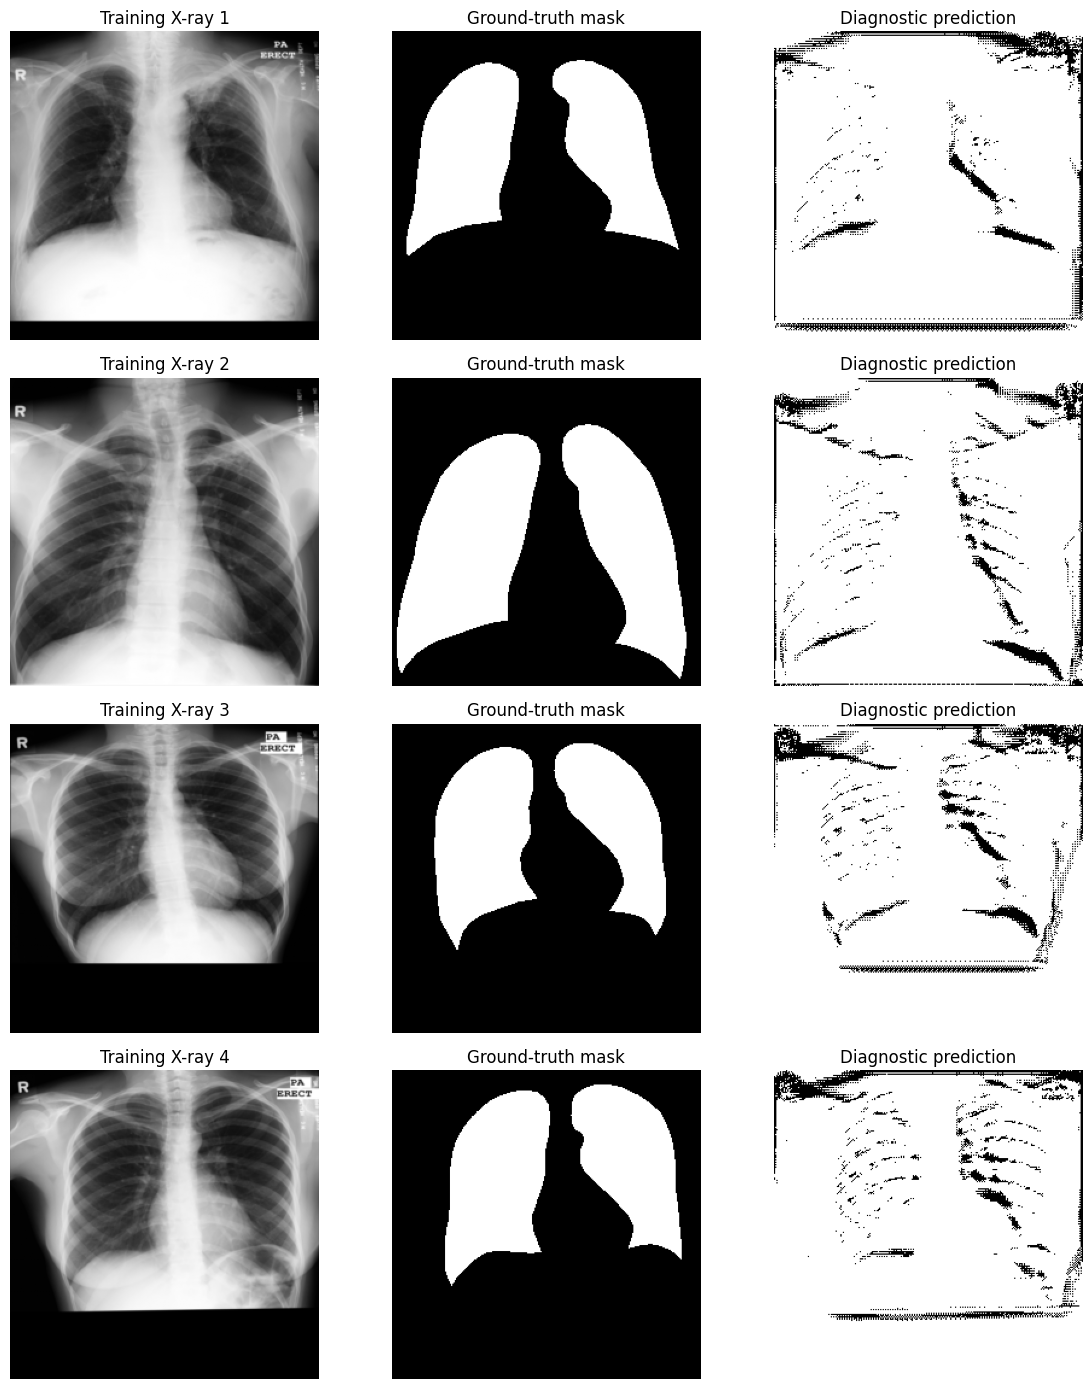

Ground-truth foreground fraction: 0.3006
Predicted foreground fraction: 0.9184


In [32]:
import numpy as np
import matplotlib.pyplot as plt

tiny_probs = diagnostic_model.predict(X_tiny, batch_size=2, verbose=0)

if isinstance(tiny_probs, (list, tuple)):
    tiny_probs = tiny_probs[-1]

tiny_binary = (tiny_probs >= 0.5).astype(np.float32)

fig, axes = plt.subplots(4, 3, figsize=(12, 14))

for i in range(4):
    axes[i, 0].imshow(X_tiny[i, :, :, 0], cmap="gray")
    axes[i, 0].set_title(f"Training X-ray {i+1}")

    axes[i, 1].imshow(Y_tiny[i, :, :, 0], cmap="gray")
    axes[i, 1].set_title("Ground-truth mask")

    axes[i, 2].imshow(tiny_binary[i, :, :, 0], cmap="gray")
    axes[i, 2].set_title("Diagnostic prediction")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

print("Ground-truth foreground fraction:",
      round(float(Y_tiny.mean()), 4))
print("Predicted foreground fraction:",
      round(float(tiny_binary.mean()), 4))

In [33]:
from pathlib import Path

path = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research/"
    "UNetPlusPlus/unetplusplus_model.py"
)

print(path.read_text())

import keras
from keras import layers
from keras.regularizers import l2

NB_FILTER = [32, 64, 128, 256, 512]
ACT = "relu"
DROPOUT_RATE = 0.5

def standard_unit(input_tensor, stage, nb_filter, kernel_size=3):
    x = layers.Conv2D(
        nb_filter, (kernel_size, kernel_size),
        activation=ACT,
        name="conv" + stage + "_1",
        kernel_initializer="he_normal",
        padding="same",
        kernel_regularizer=l2(1e-4),
    )(input_tensor)

    x = layers.Dropout(
        DROPOUT_RATE, name="dp" + stage + "_1"
    )(x)

    x = layers.Conv2D(
        nb_filter, (kernel_size, kernel_size),
        activation=ACT,
        name="conv" + stage + "_2",
        kernel_initializer="he_normal",
        padding="same",
        kernel_regularizer=l2(1e-4),
    )(x)

    x = layers.Dropout(
        DROPOUT_RATE, name="dp" + stage + "_2"
    )(x)

    return x


def UNetPlusPlus(img_rows, img_cols, color_type=1,
                 num_class=1, deep_supervision=False):

    bn_axis = 3

What we'll do next
1. Create a new experiment folder, for example UNetPlusPlus/experiment_02/.
2. Build a fresh model using the existing architecture.
3. Change only the selected experimental setting.
4. Save its checkpoints, configuration, history, and predictions separately.
5. Compare its validation results with the baseline.

In [34]:

from pathlib import Path
import json

project_dir = Path("/content/drive/MyDrive/Lung_Segmentation_Research")
unetpp_dir = project_dir / "UNetPlusPlus"

baseline_dir = unetpp_dir / "checkpoints" / "run_20261022_090555"
best_model_path = baseline_dir / "best_model.keras"
history_path = (
    unetpp_dir / "logs" / "training_history_20261022_090555.csv"
)
split_path = project_dir / "Attention_UNet" / "split_manifest.json"

print("Project directory exists:", project_dir.exists())
print("UNet++ directory exists:", unetpp_dir.exists())
print("Baseline best model exists:", best_model_path.exists())
print("Baseline training history exists:", history_path.exists())
print("Shared split manifest exists:", split_path.exists())

if split_path.exists():
    with open(split_path, "r") as f:
        split = json.load(f)

    print("\nDataset split counts:")
    print("Train:", len(split["train"]))
    print("Validation:", len(split["validation"]))
    print("Test:", len(split["test"]))

print("\nCurrent baseline folder:")
print(baseline_dir)


Project directory exists: True
UNet++ directory exists: True
Baseline best model exists: True
Baseline training history exists: True
Shared split manifest exists: True

Dataset split counts:
Train: 110
Validation: 13
Test: 15

Current baseline folder:
/content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus/checkpoints/run_20261022_090555


Create a separate experiment folder

In [35]:

from pathlib import Path
from datetime import datetime
import json

experiment_root = (
    project_dir / "UNetPlusPlus" / "experiments" / "experiment_02"
)

subfolders = [
    "checkpoints",
    "logs",
    "plots",
    "predictions",
]

for folder in subfolders:
    (experiment_root / folder).mkdir(parents=True, exist_ok=True)

experiment_info = {
    "experiment_name": "UNet++ Experiment 02",
    "purpose": "Controlled follow-up to the baseline experiment",
    "baseline_run": "run_20261022_090555",
    "dataset": "MontgomerySet",
    "split_manifest": str(split_path),
    "train_images": len(split["train"]),
    "validation_images": len(split["validation"]),
    "test_images": len(split["test"]),
    "status": "setup_only"
}

config_path = experiment_root / "logs" / "experiment_info.json"

with open(config_path, "w") as f:
    json.dump(experiment_info, f, indent=4)

print("Experiment folder created:", experiment_root)
print("\nSubfolders:")
for folder in subfolders:
    print("-", folder, ":", (experiment_root / folder).exists())

print("\nExperiment metadata saved:", config_path)


Experiment folder created: /content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus/experiments/experiment_02

Subfolders:
- checkpoints : True
- logs : True
- plots : True
- predictions : True

Experiment metadata saved: /content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus/experiments/experiment_02/logs/experiment_info.json


Inspect the baseline training configuration


In [36]:

import json
from pathlib import Path

baseline_config_path = (
    project_dir
    / "UNetPlusPlus"
    / "logs"
    / "training_config_20261022_090555.json"
)

if baseline_config_path.exists():
    with open(baseline_config_path, "r") as f:
        baseline_config = json.load(f)

    print("BASELINE TRAINING CONFIGURATION\n")
    print(json.dumps(baseline_config, indent=4))
else:
    print("Configuration file not found:", baseline_config_path)
    print("\nAvailable JSON files in the logs folder:")
    for path in (project_dir / "UNetPlusPlus" / "logs").glob("*.json"):
        print(path.name)


BASELINE TRAINING CONFIGURATION

{
    "model": "UNet++",
    "input_shape": [
        256,
        256,
        1
    ],
    "train_samples": 110,
    "validation_samples": 13,
    "test_samples": 15,
    "epochs": 20,
    "batch_size": 2,
    "optimizer": "Adam",
    "learning_rate": 0.0002,
    "loss": "Binary Cross-Entropy + Dice Loss",
    "best_checkpoint_monitor": "val_dice_coefficient",
    "checkpoint_policy": "Save each completed epoch; preserve best validation Dice",
    "run_id": "20261022_090555"
}


Define the Experiment 02 loss

In [37]:

import tensorflow as tf
import keras

def dice_per_image(y_true, y_pred, smooth=1e-6):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)

    axes = (1, 2, 3)

    intersection = tf.reduce_sum(
        y_true * y_pred, axis=axes
    )

    denominator = (
        tf.reduce_sum(y_true, axis=axes)
        + tf.reduce_sum(y_pred, axis=axes)
    )

    dice = (
        2.0 * intersection + smooth
    ) / (
        denominator + smooth
    )

    return tf.reduce_mean(dice)


def bce_dice_per_image_loss(y_true, y_pred):
    bce = keras.losses.binary_crossentropy(
        y_true, y_pred
    )

    bce = tf.reduce_mean(bce)
    dice_loss = 1.0 - dice_per_image(y_true, y_pred)

    return bce + dice_loss


print("Experiment 02 loss functions defined successfully.")
print("Loss = mean Binary Cross-Entropy + per-image Dice Loss")


Experiment 02 loss functions defined successfully.
Loss = mean Binary Cross-Entropy + per-image Dice Loss


Build a fresh UNet++ model

In [38]:

from unetplusplus_model import UNetPlusPlus

experiment_model = UNetPlusPlus(
    img_rows=256,
    img_cols=256,
    color_type=1,
    num_class=1,
    deep_supervision=False
)

print("Fresh UNet++ model created.")
print("Input shape:", experiment_model.input_shape)
print("Output shape:", experiment_model.output_shape)
print(
    "Trainable parameters:",
    sum(
        tf.keras.backend.count_params(w)
        for w in experiment_model.trainable_weights
    )
)


Fresh UNet++ model created.
Input shape: (None, 256, 256, 1)
Output shape: (None, 256, 256, 1)
Trainable parameters: 9041601


Compile Experiment 02

In [39]:

experiment_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.0002
    ),
    loss=bce_dice_per_image_loss,
    metrics=[
        keras.metrics.BinaryAccuracy(name="binary_accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        dice_per_image,
    ]
)

print("Experiment 02 model compiled successfully.")
print("Optimizer: Adam")
print("Learning rate: 0.0002")
print("Loss: BCE + per-image Dice Loss")
print("Batch size planned: 2")
print("Epoch limit planned: 20")


Experiment 02 model compiled successfully.
Optimizer: Adam
Learning rate: 0.0002
Loss: BCE + per-image Dice Loss
Batch size planned: 2
Epoch limit planned: 20


Set up checkpointing and logging

In [40]:

import json
from datetime import datetime
from pathlib import Path

from keras.callbacks import (
    ModelCheckpoint,
    CSVLogger,
    EarlyStopping
)

experiment_id = datetime.now().strftime("%Y%m%d_%H%M%S")

checkpoint_dir = experiment_root / "checkpoints" / experiment_id
log_dir = experiment_root / "logs"

checkpoint_dir.mkdir(parents=True, exist_ok=False)
log_dir.mkdir(parents=True, exist_ok=True)

best_model_path = checkpoint_dir / "best_model.keras"
epoch_checkpoint_path = (
    checkpoint_dir / "epoch_{epoch:02d}.keras"
)
history_csv_path = log_dir / f"history_{experiment_id}.csv"
config_path = log_dir / f"config_{experiment_id}.json"

callbacks = [
    ModelCheckpoint(
        filepath=str(best_model_path),
        monitor="val_dice_per_image",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    ModelCheckpoint(
        filepath=str(epoch_checkpoint_path),
        save_best_only=False,
        save_weights_only=False,
        verbose=0
    ),
    CSVLogger(str(history_csv_path))
]

experiment_config = {
    "experiment_id": experiment_id,
    "model": "UNet++",
    "input_shape": [256, 256, 1],
    "train_samples": len(X_train),
    "validation_samples": len(X_val),
    "test_samples": len(X_test),
    "epochs": 20,
    "batch_size": 2,
    "optimizer": "Adam",
    "learning_rate": 0.0002,
    "loss": "BCE + per-image Dice loss",
    "checkpoint_monitor": "val_dice_per_image",
    "baseline_run": "run_20261022_090555",
    "split_manifest": str(split_path)
}

with open(config_path, "w") as f:
    json.dump(experiment_config, f, indent=4)

print("Experiment ID:", experiment_id)
print("Checkpoint directory:", checkpoint_dir)
print("Best model path:", best_model_path)
print("History CSV:", history_csv_path)
print("Configuration saved:", config_path)
print("Callbacks configured:", len(callbacks))


Experiment ID: 20261022_093907
Checkpoint directory: /content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus/experiments/experiment_02/checkpoints/20261022_093907
Best model path: /content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus/experiments/experiment_02/checkpoints/20261022_093907/best_model.keras
History CSV: /content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus/experiments/experiment_02/logs/history_20261022_093907.csv
Configuration saved: /content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus/experiments/experiment_02/logs/config_20261022_093907.json
Callbacks configured: 3


Train Experiment 02

In [41]:

# Confirm the expected data is available before training.
assert len(X_train) == 110, "Unexpected training-set size"
assert len(X_val) == 13, "Unexpected validation-set size"
assert X_train.shape[1:] == (256, 256, 1)
assert Y_train.shape[1:] == (256, 256, 1)
assert X_val.shape[1:] == (256, 256, 1)
assert Y_val.shape[1:] == (256, 256, 1)

print("Training data:", X_train.shape, Y_train.shape)
print("Validation data:", X_val.shape, Y_val.shape)
print("Starting Experiment 02 training...")

history = experiment_model.fit(
    X_train,
    Y_train,
    validation_data=(X_val, Y_val),
    epochs=20,
    batch_size=2,
    callbacks=callbacks,
    shuffle=True,
    verbose=1
)

print("\nExperiment 02 training finished.")
print("Best model:", best_model_path)
print("Training history:", history_csv_path)


Training data: (110, 256, 256, 1) (110, 256, 256, 1)
Validation data: (13, 256, 256, 1) (13, 256, 256, 1)
Starting Experiment 02 training...
Epoch 1/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 178ms/step - binary_accuracy: 0.6029 - dice_per_image: 0.3102 - loss: 4.1083 - precision: 0.2624 - recall: 0.2898
Epoch 1: val_dice_per_image improved from None to 0.33626, saving model to /content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus/experiments/experiment_02/checkpoints/20261022_093907/best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus/experiments/experiment_02/checkpoints/20261022_093907/best_model.keras
55/55 ━━━━━━━━━━━━━━━━━━━━ 54s 348ms/step - binary_accuracy: 0.6450 - dice_per_image: 0.3105 - loss: 2.6134 - precision: 0.2624 - recall: 0.2173 - val_binary_accuracy: 0.7448 - val_dice_per_image: 0.3363 - val_loss: 2.0615 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/ste

Load the best checkpoint and inspect predictions

7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 311ms/step
Prediction shape: (13, 256, 256, 1)
Probability range: 0.0 to 0.9999921321868896


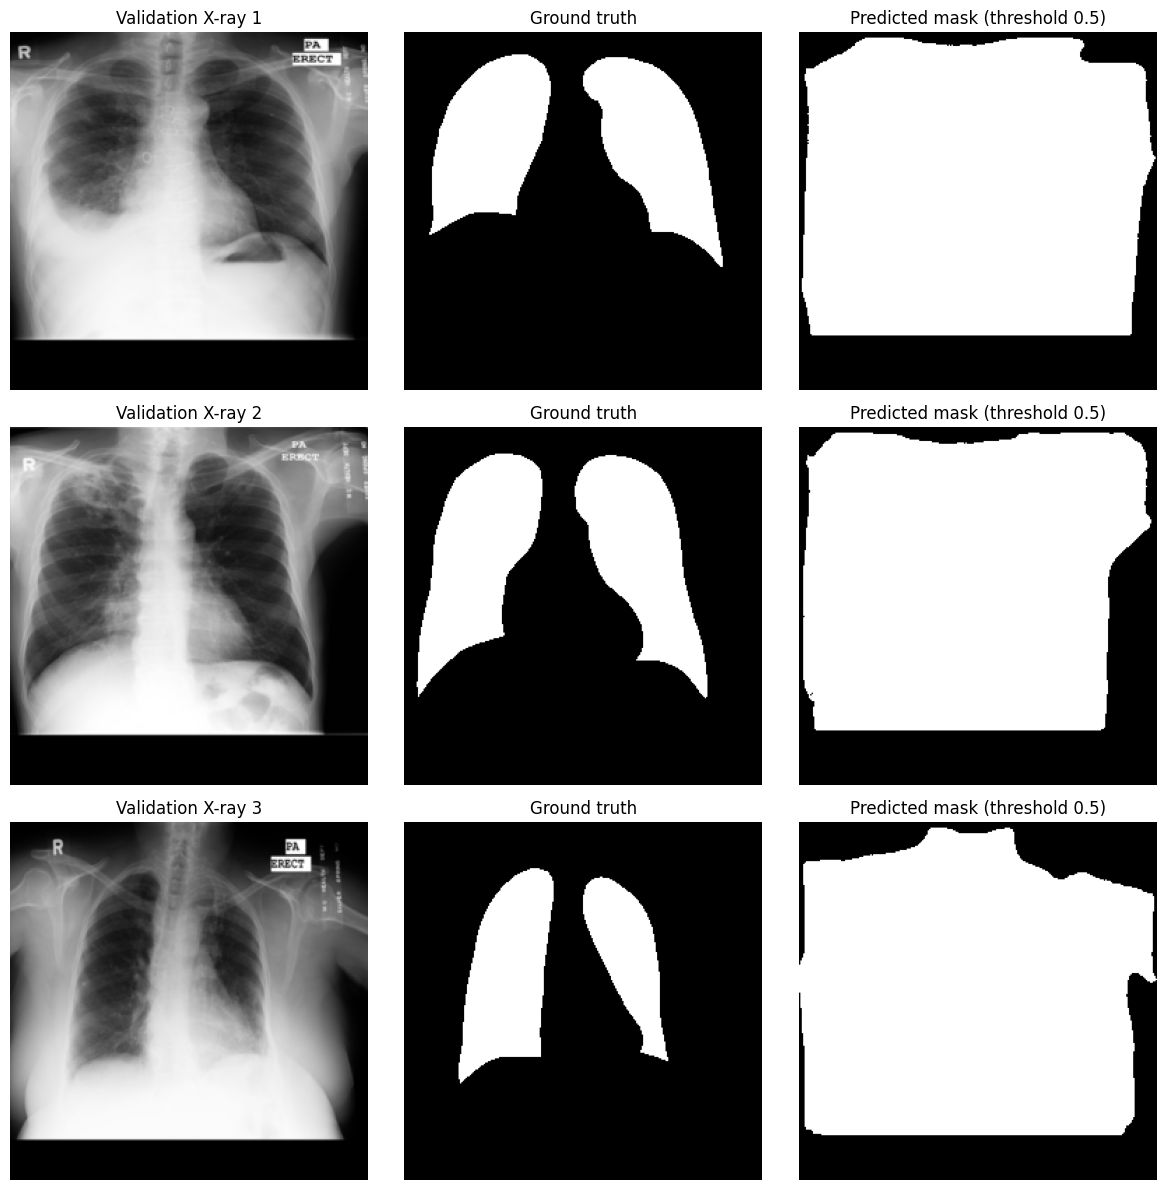

In [42]:

import numpy as np
import matplotlib.pyplot as plt
import keras

best_experiment_model = keras.models.load_model(
    str(best_model_path),
    custom_objects={
        "bce_dice_per_image_loss": bce_dice_per_image_loss,
        "dice_per_image": dice_per_image,
    }
)

# Predict on validation data only
val_probabilities = best_experiment_model.predict(
    X_val, batch_size=2, verbose=1
)

print("Prediction shape:", val_probabilities.shape)
print("Probability range:",
      float(val_probabilities.min()),
      "to",
      float(val_probabilities.max()))

# Inspect the first three validation examples
fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for i in range(min(3, len(X_val))):
    pred_mask = (val_probabilities[i, :, :, 0] >= 0.5).astype(np.uint8)

    axes[i, 0].imshow(X_val[i, :, :, 0], cmap="gray")
    axes[i, 0].set_title(f"Validation X-ray {i + 1}")

    axes[i, 1].imshow(Y_val[i, :, :, 0], cmap="gray")
    axes[i, 1].set_title("Ground truth")

    axes[i, 2].imshow(pred_mask, cmap="gray")
    axes[i, 2].set_title("Predicted mask (threshold 0.5)")

    for j in range(3):
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()


Next step: diagnose before retraining
Cell 10 — Check image, mask, and prediction statistics

In [43]:

import numpy as np

print("=== INPUT AND MASK CHECK ===")
print("X_val range:", float(X_val.min()), "to", float(X_val.max()))
print("Y_val unique values:", np.unique(Y_val))
print("Prediction range:",
      float(val_probabilities.min()),
      "to",
      float(val_probabilities.max()))

print("\n=== PER-IMAGE FOREGROUND CHECK ===")
print("Image | Actual lung % | Predicted % at 0.5 | Predicted % at 0.9")

for i in range(len(X_val)):
    actual_fraction = float(np.mean(Y_val[i] >= 0.5))
    pred_05 = float(np.mean(val_probabilities[i] >= 0.5))
    pred_09 = float(np.mean(val_probabilities[i] >= 0.9))

    print(
        f"{i + 1:5d} | "
        f"{actual_fraction * 100:12.2f}% | "
        f"{pred_05 * 100:18.2f}% | "
        f"{pred_09 * 100:18.2f}%"
    )

print("\n=== PREDICTION PROBABILITY PERCENTILES ===")
print(
    np.percentile(
        val_probabilities,
        [0, 10, 25, 50, 75, 90, 99, 100]
    )
)


=== INPUT AND MASK CHECK ===
X_val range: 0.0 to 1.0
Y_val unique values: [0. 1.]
Prediction range: 0.0 to 0.9999921321868896

=== PER-IMAGE FOREGROUND CHECK ===
Image | Actual lung % | Predicted % at 0.5 | Predicted % at 0.9
    1 |        23.42% |              75.63% |              74.02%
    2 |        26.15% |              72.22% |              70.50%
    3 |        16.69% |              73.14% |              71.34%
    4 |        37.14% |              91.70% |              89.90%
    5 |        19.49% |              58.27% |              56.40%
    6 |        26.97% |              81.57% |              79.94%
    7 |        34.88% |              86.52% |              84.70%
    8 |        24.62% |              65.97% |              64.50%
    9 |        23.33% |              59.26% |              57.98%
   10 |        23.16% |              67.13% |              65.55%
   11 |        25.67% |              74.99% |              73.43%
   12 |        22.73% |              73.14% |   

Check prediction variation across images

In [44]:

# Compare predictions for different validation images.
# If outputs are nearly identical, the model may have learned
# a largely image-independent foreground pattern.

sample_indices = [0, 1, 2, 3, 4]

print("Pairwise prediction differences (mean absolute difference):")

for a in range(len(sample_indices)):
    for b in range(a + 1, len(sample_indices)):
        i = sample_indices[a]
        j = sample_indices[b]

        difference = np.mean(
            np.abs(
                val_probabilities[i] - val_probabilities[j]
            )
        )

        print(f"Image {i + 1} vs Image {j + 1}: {difference:.6f}")

print("\nPer-image prediction standard deviation:")
for i in sample_indices:
    print(
        f"Image {i + 1}: "
        f"{np.std(val_probabilities[i]):.6f}"
    )


Pairwise prediction differences (mean absolute difference):
Image 1 vs Image 2: 0.069511
Image 1 vs Image 3: 0.097711
Image 1 vs Image 4: 0.181881
Image 1 vs Image 5: 0.201922
Image 2 vs Image 3: 0.146419
Image 2 vs Image 4: 0.222104
Image 2 vs Image 5: 0.225386
Image 3 vs Image 4: 0.213514
Image 3 vs Image 5: 0.269514
Image 4 vs Image 5: 0.350737

Per-image prediction standard deviation:
Image 1: 0.417511
Image 2: 0.437612
Image 3: 0.431338
Image 4: 0.253153
Image 5: 0.481238


Verify the data loader and model source

In [45]:

from pathlib import Path
import inspect

print("=== DATA LOADER FUNCTIONS ===")
print(inspect.getsource(load_image))
print(inspect.getsource(load_mask))

print("\n=== MODEL SOURCE LOCATION ===")
print(inspect.getfile(UNetPlusPlus))

print("\n=== MODEL OUTPUT LAYER ===")
experiment_model.layers[-1].get_config()


=== DATA LOADER FUNCTIONS ===
def load_image(filename):
    path = dataset_dir / "CXR_png" / filename
    with Image.open(path) as img:
        img = img.convert("L").resize(
            IMG_SIZE, Image.Resampling.BILINEAR
        )
        arr = np.asarray(img, dtype=np.float32) / 255.0

    return arr[..., np.newaxis]

def load_mask(filename):
    left_path = dataset_dir / "ManualMask" / "leftMask" / filename
    right_path = dataset_dir / "ManualMask" / "rightMask" / filename

    with Image.open(left_path) as img:
        left = np.asarray(
            img.convert("L").resize(
                IMG_SIZE, Image.Resampling.NEAREST
            )
        ) > 0

    with Image.open(right_path) as img:
        right = np.asarray(
            img.convert("L").resize(
                IMG_SIZE, Image.Resampling.NEAREST
            )
        ) > 0

    combined = np.logical_or(left, right).astype(np.float32)
    return combined[..., np.newaxis]


=== MODEL SOURCE LOCATION ===
/content/drive/My

{'name': 'output_4',
 'trainable': True,
 'dtype': {'module': 'keras',
  'class_name': 'DTypePolicy',
  'config': {'name': 'float32'},
  'registered_name': None},
 'filters': 1,
 'kernel_size': (1, 1),
 'strides': (1, 1),
 'padding': 'same',
 'data_format': 'channels_last',
 'dilation_rate': (1, 1),
 'groups': 1,
 'activation': 'sigmoid',
 'use_bias': True,
 'kernel_initializer': {'module': 'keras.initializers',
  'class_name': 'HeNormal',
  'config': {'seed': None},
  'registered_name': None},
 'bias_initializer': {'module': 'keras.initializers',
  'class_name': 'Zeros',
  'config': {},
  'registered_name': None},
 'kernel_regularizer': {'module': 'keras.regularizers',
  'class_name': 'L2',
  'config': {'l2': 0.0001},
  'registered_name': None},
 'bias_regularizer': None,
 'activity_regularizer': None,
 'kernel_constraint': None,
 'bias_constraint': None}

Inspect the UNet++ output connections

In [46]:

from pathlib import Path

model_file = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research/"
    "UNetPlusPlus/unetplusplus_model.py"
)

source = model_file.read_text()

print("=== OUTPUT AND DEEP-SUPERVISION REFERENCES ===")
for line_number, line in enumerate(source.splitlines(), start=1):
    if any(term in line.lower() for term in [
        "output_1", "output_2", "output_3", "output_4",
        "deep_supervision", "model(inputs"
    ]):
        print(f"{line_number}: {line.strip()}")

print("\n=== MODEL SUMMARY ===")
experiment_model.summary()


=== OUTPUT AND DEEP-SUPERVISION REFERENCES ===
40: num_class=1, deep_supervision=False):
163: output_1 = layers.Conv2D(
165: name="output_1", kernel_initializer="he_normal",
169: output_2 = layers.Conv2D(
171: name="output_2", kernel_initializer="he_normal",
175: output_3 = layers.Conv2D(
177: name="output_3", kernel_initializer="he_normal",
181: output_4 = layers.Conv2D(
183: name="output_4", kernel_initializer="he_normal",
187: if deep_supervision:
188: outputs = [output_1, output_2, output_3, output_4]
190: outputs = [output_4]
192: return keras.Model(inputs=img_input, outputs=outputs)

=== MODEL SUMMARY ===


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ main_input          │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv11_1 (Conv2D)   │ (None, 256, 256,  │        320 │ main_input[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dp11_1 (Dropout)    │ (None, 256, 256,  │          0 │ conv11_1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv11_2 (Conv2D)   │ (None, 256, 256,  │      9,248 │ dp11_1[0][0]      │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dp11_2 (Dropout)    │ (None, 256, 256,  │          0 │ conv11_2[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 128, 128,  │          0 │ dp11_2[0][0]      │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv21_1 (Conv2D)   │ (None, 128, 128,  │     18,496 │ pool1[0][0]       │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dp21_1 (Dropout)    │ (None, 128, 128,  │          0 │ conv21_1[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv21_2 (Conv2D)   │ (None, 128, 128,  │     36,928 │ dp21_1[0][0]      │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dp21_2 (Dropout)    │ (None, 128, 128,  │          0 │ conv21_2[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool2               │ (None, 64, 64,    │          0 │ dp21_2[0][0]      │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv31_1 (Conv2D)   │ (None, 64, 64,    │     73,856 │ pool2[0][0]       │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dp31_1 (Dropout)    │ (None, 64, 64,    │          0 │ conv31_1[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv31_2 (Conv2D)   │ (None, 64, 64,    │    147,584 │ dp31_1[0][0]      │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dp31_2 (Dropout)    │ (None, 64, 64,    │          0 │ conv31_2[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool3               │ (None, 32, 32,    │          0 │ dp31_2[0][0]      │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv41_1 (Conv2D)   │ (None, 32, 32,    │    295,168 │ pool3[0][0]     

 Total params: 27,124,805 (103.47 MB)

 Trainable params: 9,041,601 (34.49 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 18,083,204 (68.98 MB)

Tiny-subset overfitting test

In [47]:

# Diagnostic only: fresh model, four training images, five epochs.
# Does not modify saved checkpoints or the existing experiment models.

tiny_model = UNetPlusPlus(
    img_rows=256,
    img_cols=256,
    color_type=1,
    num_class=1,
    deep_supervision=False
)

tiny_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0002),
    loss=bce_dice_per_image_loss,
    metrics=[dice_per_image]
)

X_tiny = X_train[:4]
Y_tiny = Y_train[:4]

print("Training subset:", X_tiny.shape, Y_tiny.shape)

initial_results = tiny_model.evaluate(
    X_tiny, Y_tiny, verbose=0, return_dict=True
)
print("\nInitial evaluation:", initial_results)

tiny_history = tiny_model.fit(
    X_tiny,
    Y_tiny,
    epochs=5,
    batch_size=2,
    shuffle=False,
    verbose=1
)

final_results = tiny_model.evaluate(
    X_tiny, Y_tiny, verbose=0, return_dict=True
)
print("\nFinal evaluation:", final_results)

tiny_probs = tiny_model.predict(X_tiny, verbose=0)

print("\nGround-truth foreground fraction:",
      float(np.mean(Y_tiny >= 0.5)))
print("Predicted foreground fraction at threshold 0.5:",
      float(np.mean(tiny_probs >= 0.5)))


Training subset: (4, 256, 256, 1) (4, 256, 256, 1)

Initial evaluation: {'dice_per_image': 0.3740428686141968, 'loss': 2.0561044216156006}
Epoch 1/5
2/2 ━━━━━━━━━━━━━━━━━━━━ 35s 222ms/step - dice_per_image: 0.2782 - loss: 7.5285
Epoch 2/5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 205ms/step - dice_per_image: 0.2983 - loss: 3.4286
Epoch 3/5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 207ms/step - dice_per_image: 0.3145 - loss: 2.6266
Epoch 4/5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 209ms/step - dice_per_image: 0.3282 - loss: 2.3350
Epoch 5/5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 207ms/step - dice_per_image: 0.3392 - loss: 2.1888

Final evaluation: {'dice_per_image': 0.3731808662414551, 'loss': 2.0238916873931885}



Ground-truth foreground fraction: 0.30059814453125
Predicted foreground fraction at threshold 0.5: 0.1507568359375


Visualize tiny-subset predictions

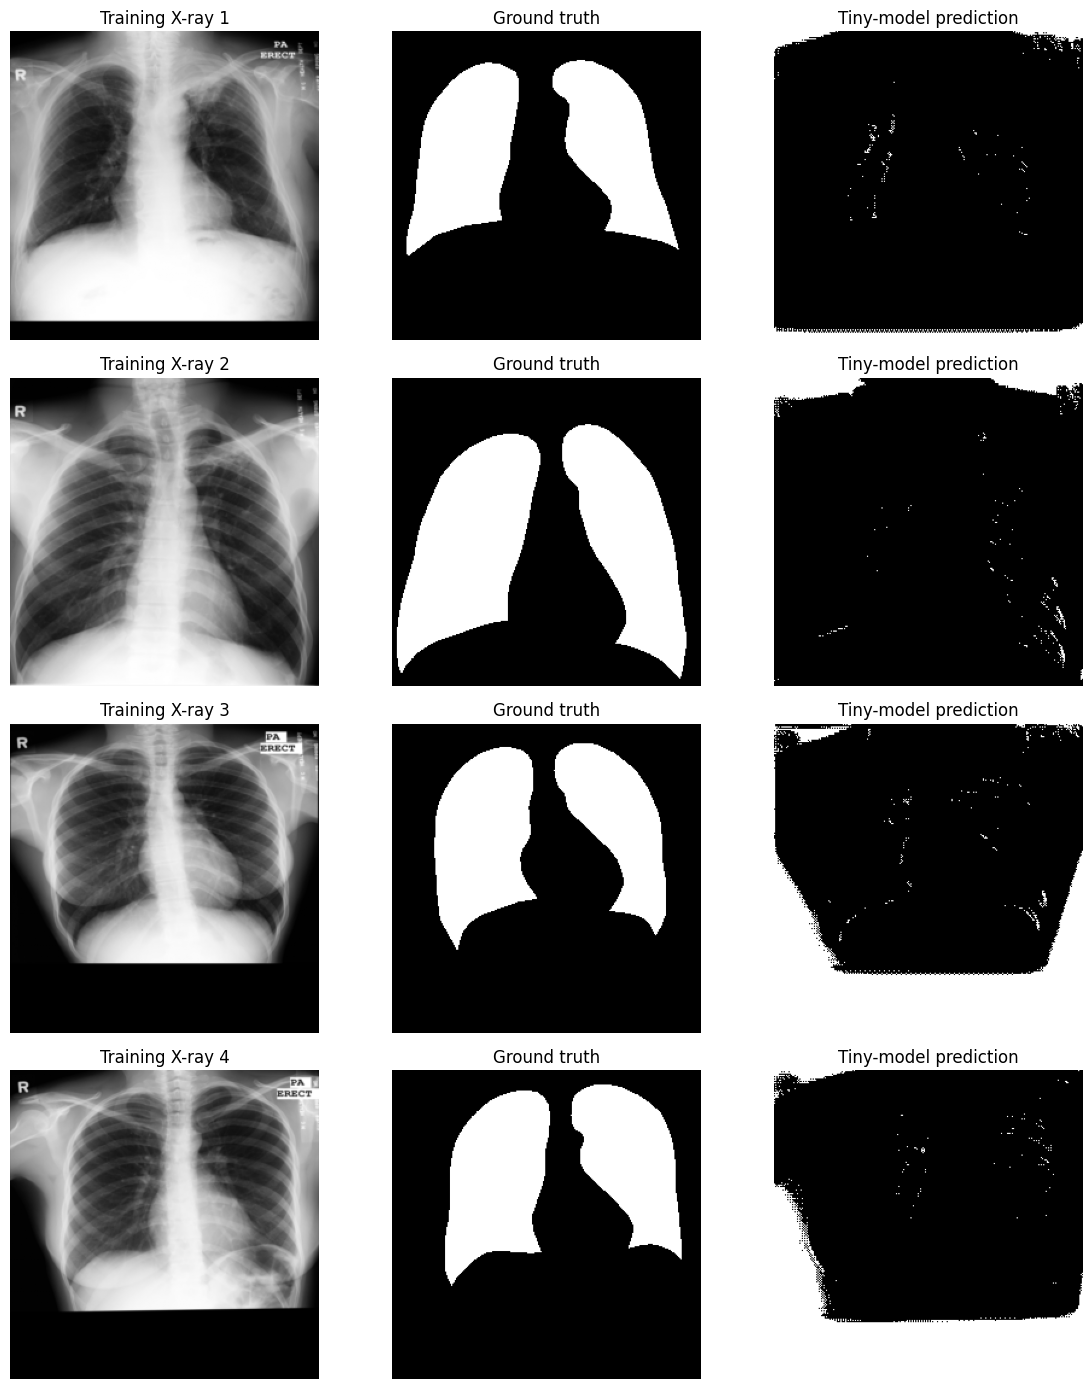

In [48]:

import matplotlib.pyplot as plt
import numpy as np

tiny_probs = tiny_model.predict(X_tiny, batch_size=2, verbose=0)

fig, axes = plt.subplots(4, 3, figsize=(12, 14))

for i in range(4):
    pred_mask = (tiny_probs[i, :, :, 0] >= 0.5).astype(np.uint8)

    axes[i, 0].imshow(X_tiny[i, :, :, 0], cmap="gray")
    axes[i, 0].set_title(f"Training X-ray {i + 1}")

    axes[i, 1].imshow(Y_tiny[i, :, :, 0], cmap="gray")
    axes[i, 1].set_title("Ground truth")

    axes[i, 2].imshow(pred_mask, cmap="gray")
    axes[i, 2].set_title("Tiny-model prediction")

    for j in range(3):
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()


Inspect probabilities and loss components

In [49]:

# Inspect raw probabilities before thresholding.
print("=== RAW PREDICTION STATISTICS ===")

for i in range(4):
    p = tiny_probs[i, :, :, 0]
    y = Y_tiny[i, :, :, 0]

    print(f"\nImage {i + 1}")
    print("Ground-truth foreground fraction:", float(np.mean(y)))
    print("Mean predicted probability:", float(np.mean(p)))
    print("Probability percentiles:",
          np.percentile(p, [0, 10, 25, 50, 75, 90, 99, 100]))
    print("Predicted foreground fraction at 0.5:",
          float(np.mean(p >= 0.5)))

print("\n=== LOSS COMPONENTS ON THE SAME FOUR IMAGES ===")

tiny_eval_probs = tiny_model.predict(X_tiny, batch_size=2, verbose=0)

bce_values = keras.losses.binary_crossentropy(
    Y_tiny, tiny_eval_probs
)

print("Mean BCE:", float(tf.reduce_mean(bce_values).numpy()))
print("Per-image Dice:", float(dice_per_image(Y_tiny, tiny_eval_probs).numpy()))
print("Combined loss:", float(
    bce_dice_per_image_loss(Y_tiny, tiny_eval_probs).numpy()
))


=== RAW PREDICTION STATISTICS ===

Image 1
Ground-truth foreground fraction: 0.2746734619140625
Mean predicted probability: 0.4749002158641815
Probability percentiles: [0.43324119 0.45541275 0.46183208 0.47322306 0.48914735 0.49622329
 0.50041324 0.51111293]
Predicted foreground fraction at 0.5: 0.0428924560546875

Image 2
Ground-truth foreground fraction: 0.3844757080078125
Mean predicted probability: 0.47727322578430176
Probability percentiles: [0.4131943  0.45818461 0.46492591 0.47831756 0.48970445 0.49526151
 0.50041977 0.5121631 ]
Predicted foreground fraction at 0.5: 0.032928466796875

Image 3
Ground-truth foreground fraction: 0.2687835693359375
Mean predicted probability: 0.48413699865341187
Probability percentiles: [0.40864387 0.46059209 0.4702647  0.48850691 0.50037739 0.50039792
 0.50075653 0.54118133]
Predicted foreground fraction at 0.5: 0.275238037109375

Image 4
Ground-truth foreground fraction: 0.2744598388671875
Mean predicted probability: 0.48222675919532776
Probabilit

Check whether gradients are flowing

In [50]:

# Diagnostic: check loss and gradient values without applying an optimizer step.
with tf.GradientTape() as tape:
    tiny_batch = tf.convert_to_tensor(X_tiny[:2], dtype=tf.float32)
    tiny_targets = tf.convert_to_tensor(Y_tiny[:2], dtype=tf.float32)

    tiny_batch_predictions = tiny_model(tiny_batch, training=True)
    diagnostic_loss = bce_dice_per_image_loss(
        tiny_targets, tiny_batch_predictions
    )

gradients = tape.gradient(
    diagnostic_loss, tiny_model.trainable_variables
)

gradient_stats = []
for grad in gradients:
    if grad is not None:
        grad_values = tf.convert_to_tensor(grad)
        gradient_stats.append({
            "finite": bool(tf.reduce_all(tf.math.is_finite(grad_values)).numpy()),
            "mean_abs": float(tf.reduce_mean(tf.abs(grad_values)).numpy()),
            "max_abs": float(tf.reduce_max(tf.abs(grad_values)).numpy())
        })

print("Diagnostic loss:", float(diagnostic_loss.numpy()))
print("Trainable variables:", len(tiny_model.trainable_variables))
print("Variables with gradients:", sum(g is not None for g in gradients))
print("Variables with missing gradients:", sum(g is None for g in gradients))
print("All gradients finite:", all(s["finite"] for s in gradient_stats))
print("Mean absolute gradient across variables:",
      float(np.mean([s["mean_abs"] for s in gradient_stats])))
print("Largest absolute gradient:",
      max(s["max_abs"] for s in gradient_stats))



Diagnostic loss: 1.3742389678955078
Trainable variables: 82
Variables with gradients: 82
Variables with missing gradients: 0
All gradients finite: True
Mean absolute gradient across variables: 0.002708117987751626
Largest absolute gradient: 0.17529158294200897


Verify the tiny model can make an optimizer update

In [51]:

# One diagnostic optimizer step on two training images.
# This changes only the temporary tiny_model in memory.

weights_before = [
    w.numpy().copy() for w in tiny_model.trainable_variables
]

tiny_model.train_on_batch(X_tiny[:2], Y_tiny[:2])

weights_after = [
    w.numpy().copy() for w in tiny_model.trainable_variables
]

changed_variables = sum(
    not np.array_equal(before, after)
    for before, after in zip(weights_before, weights_after)
)

total_weight_change = sum(
    float(np.sum(np.abs(after - before)))
    for before, after in zip(weights_before, weights_after)
)

print("Variables whose weights changed:", changed_variables, "/", len(weights_before))
print("Total absolute weight change:", total_weight_change)

print("\nEvaluation after the optimizer step:")
print(tiny_model.evaluate(X_tiny, Y_tiny, verbose=0, return_dict=True))


Variables whose weights changed: 82 / 82
Total absolute weight change: 397.16687604796607

Evaluation after the optimizer step:
{'dice_per_image': 0.37338554859161377, 'loss': 2.0206515789031982}


Test dropout's effect on the saved baseline

In [52]:

import numpy as np
import keras

baseline_best_path = (
    project_dir / "UNetPlusPlus" / "checkpoints"
    / "run_20261022_090555" / "best_model.keras"
)
baseline_last_path = (
    project_dir / "UNetPlusPlus" / "checkpoints"
    / "run_20261022_090555" / "epoch_20.keras"
)

def predict_in_mode(model, X, training=False, batch_size=2):
    outputs = []

    for start in range(0, len(X), batch_size):
        batch = X[start:start + batch_size]
        pred = model(batch, training=training)

        if isinstance(pred, (list, tuple)):
            pred = pred[-1]

        outputs.append(pred.numpy())

    return np.concatenate(outputs, axis=0)


def report_metrics(name, probabilities, targets):
    pred = probabilities >= 0.5
    true = targets >= 0.5

    axes = (1, 2, 3)
    intersection = np.sum(pred & true, axis=axes)
    pred_area = np.sum(pred, axis=axes)
    true_area = np.sum(true, axis=axes)

    dice_per_image = (
        2 * intersection
        / np.maximum(pred_area + true_area, 1)
    )

    tp = np.sum(pred & true)
    fp = np.sum(pred & ~true)
    fn = np.sum(~pred & true)

    print(
        f"{name}: "
        f"Dice/image={dice_per_image.mean():.4f}, "
        f"Pooled Dice={2*tp/max(2*tp+fp+fn, 1):.4f}, "
        f"Precision={tp/max(tp+fp, 1):.4f}, "
        f"Recall={tp/max(tp+fn, 1):.4f}, "
        f"Pred FG={pred.mean():.3f}, "
        f"GT FG={true.mean():.3f}"
    )


for tag, path in [
    ("BEST", baseline_best_path),
    ("LAST", baseline_last_path)
]:
    print(f"\n===== {tag} CHECKPOINT =====")

    if not path.exists():
        print("Checkpoint not found:", path)
        continue

    model_check = keras.models.load_model(
        str(path), compile=False
    )

    for dataset_name, X, Y in [
        ("TRAIN", X_train, Y_train),
        ("VAL", X_val, Y_val)
    ]:
        pred_eval = predict_in_mode(
            model_check, X, training=False
        )
        pred_dropout = predict_in_mode(
            model_check, X, training=True
        )

        report_metrics(
            f"{dataset_name} inference mode",
            pred_eval, Y
        )
        report_metrics(
            f"{dataset_name} dropout active",
            pred_dropout, Y
        )

        print(
            f"{dataset_name} mean absolute prediction difference:",
            float(np.mean(np.abs(pred_eval - pred_dropout)))
        )



===== BEST CHECKPOINT =====
TRAIN inference mode: Dice/image=0.5308, Pooled Dice=0.5312, Precision=0.3618, Recall=0.9993, Pred FG=0.704, GT FG=0.255
TRAIN dropout active: Dice/image=0.8514, Pooled Dice=0.8586, Precision=0.9349, Recall=0.7938, Pred FG=0.216, GT FG=0.255
TRAIN mean absolute prediction difference: 0.47226566076278687
VAL inference mode: Dice/image=0.5270, Pooled Dice=0.5287, Precision=0.3597, Recall=0.9970, Pred FG=0.707, GT FG=0.255
VAL dropout active: Dice/image=0.8451, Pooled Dice=0.8479, Precision=0.9368, Recall=0.7745, Pred FG=0.211, GT FG=0.255
VAL mean absolute prediction difference: 0.4824073910713196

===== LAST CHECKPOINT =====
TRAIN inference mode: Dice/image=0.5080, Pooled Dice=0.5103, Precision=0.3426, Recall=0.9999, Pred FG=0.744, GT FG=0.255
TRAIN dropout active: Dice/image=0.9063, Pooled Dice=0.9108, Precision=0.9263, Recall=0.8958, Pred FG=0.246, GT FG=0.255
TRAIN mean absolute prediction difference: 0.47655588388442993
VAL inference mode: Dice/image=0.5

Average 20 dropout-active predictions

In [53]:

# Diagnostic only: no weights are updated.
# Uses the saved best baseline checkpoint and validation set.

mc_predictions = []

for run in range(20):
    probabilities = predict_in_mode(
        model_check, X_val, training=True, batch_size=2
    )
    mc_predictions.append(probabilities)

mc_mean_probabilities = np.mean(mc_predictions, axis=0)

print("MC-dropout passes:", len(mc_predictions))
print("Mean probability range:",
      float(mc_mean_probabilities.min()),
      "to",
      float(mc_mean_probabilities.max()))

report_metrics(
    "VAL MC-dropout average (20 passes)",
    mc_mean_probabilities,
    Y_val
)

# Compare variability across stochastic passes.
mc_std = np.std(np.stack(mc_predictions, axis=0), axis=0)
print("Mean prediction standard deviation:",
      float(mc_std.mean()))


MC-dropout passes: 20
Mean probability range: 5.004562138818284e-33 to 0.9999998807907104
VAL MC-dropout average (20 passes): Dice/image=0.9086, Pooled Dice=0.9111, Precision=0.9333, Recall=0.8899, Pred FG=0.243, GT FG=0.255
Mean prediction standard deviation: 0.03900021314620972


In [54]:
from pathlib import Path
import numpy as np
import tensorflow as tf
from tensorflow import keras

# Explicitly load the baseline best checkpoint
best_checkpoint = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research/"
    "UNetPlusPlus/checkpoints/run_20261022_090555/best_model.keras"
)

assert best_checkpoint.exists(), f"Checkpoint not found: {best_checkpoint}"

model_verify = keras.models.load_model(
    best_checkpoint,
    compile=False
)

print("Checkpoint:", best_checkpoint)
print("Parameters:", model_verify.count_params())

# Standard inference: dropout disabled
standard_probs = predict_in_mode(
    model_verify, X_val, training=False, batch_size=2
)

# MC dropout: dropout active; average 20 passes
mc_runs = 20
mc_predictions = []

for i in range(mc_runs):
    probs = predict_in_mode(
        model_verify, X_val, training=True, batch_size=2
    )
    mc_predictions.append(probs)

mc_stack = np.stack(mc_predictions, axis=0)
mc_mean = np.mean(mc_stack, axis=0)

print("\n--- Standard inference ---")
report_metrics("VAL standard inference", standard_probs, Y_val)

print("\n--- MC-dropout average ---")
report_metrics("VAL MC-dropout average", mc_mean, Y_val)

print("\n--- Consistency checks ---")
print("Standard probability range:",
      float(standard_probs.min()), "to", float(standard_probs.max()))
print("MC mean probability range:",
      float(mc_mean.min()), "to", float(mc_mean.max()))
print("Mean MC prediction std:",
      float(np.std(mc_stack, axis=0).mean()))

Checkpoint: /content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus/checkpoints/run_20261022_090555/best_model.keras
Parameters: 9041601

--- Standard inference ---
VAL standard inference: Dice/image=0.5270, Pooled Dice=0.5287, Precision=0.3597, Recall=0.9970, Pred FG=0.707, GT FG=0.255

--- MC-dropout average ---
VAL MC-dropout average: Dice/image=0.8566, Pooled Dice=0.8593, Precision=0.9453, Recall=0.7876, Pred FG=0.213, GT FG=0.255

--- Consistency checks ---
Standard probability range: 0.0 to 0.9996838569641113
MC mean probability range: 0.0 to 0.9990625381469727
Mean MC prediction std: 0.05499724671244621


check reproducibility

In [55]:
# Reproducibility check: same checkpoint, same validation set
# No training and no file modifications.

mc_run_scores = []

for trial in range(3):
    trial_predictions = []

    for pass_id in range(20):
        probs = predict_in_mode(
            model_verify,
            X_val,
            training=True,
            batch_size=2
        )
        trial_predictions.append(probs)

    trial_mean = np.mean(
        np.stack(trial_predictions, axis=0),
        axis=0
    )

    print(f"\n===== MC-DROPOUT TRIAL {trial + 1} =====")
    report_metrics(
        f"VAL MC-dropout trial {trial + 1}",
        trial_mean,
        Y_val
    )

    mc_run_scores.append(trial_mean)

print("\n===== SUMMARY =====")
for i, preds in enumerate(mc_run_scores, start=1):
    print(
        f"Trial {i}: mean probability={preds.mean():.5f}, "
        f"foreground at 0.5={np.mean(preds >= 0.5):.4f}"
    )


===== MC-DROPOUT TRIAL 1 =====
VAL MC-dropout trial 1: Dice/image=0.8572, Pooled Dice=0.8598, Precision=0.9461, Recall=0.7879, Pred FG=0.213, GT FG=0.255

===== MC-DROPOUT TRIAL 2 =====
VAL MC-dropout trial 2: Dice/image=0.8562, Pooled Dice=0.8588, Precision=0.9450, Recall=0.7870, Pred FG=0.213, GT FG=0.255

===== MC-DROPOUT TRIAL 3 =====
VAL MC-dropout trial 3: Dice/image=0.8563, Pooled Dice=0.8589, Precision=0.9458, Recall=0.7867, Pred FG=0.212, GT FG=0.255

===== SUMMARY =====
Trial 1: mean probability=0.22668, foreground at 0.5=0.2125
Trial 2: mean probability=0.22648, foreground at 0.5=0.2125
Trial 3: mean probability=0.22639, foreground at 0.5=0.2123


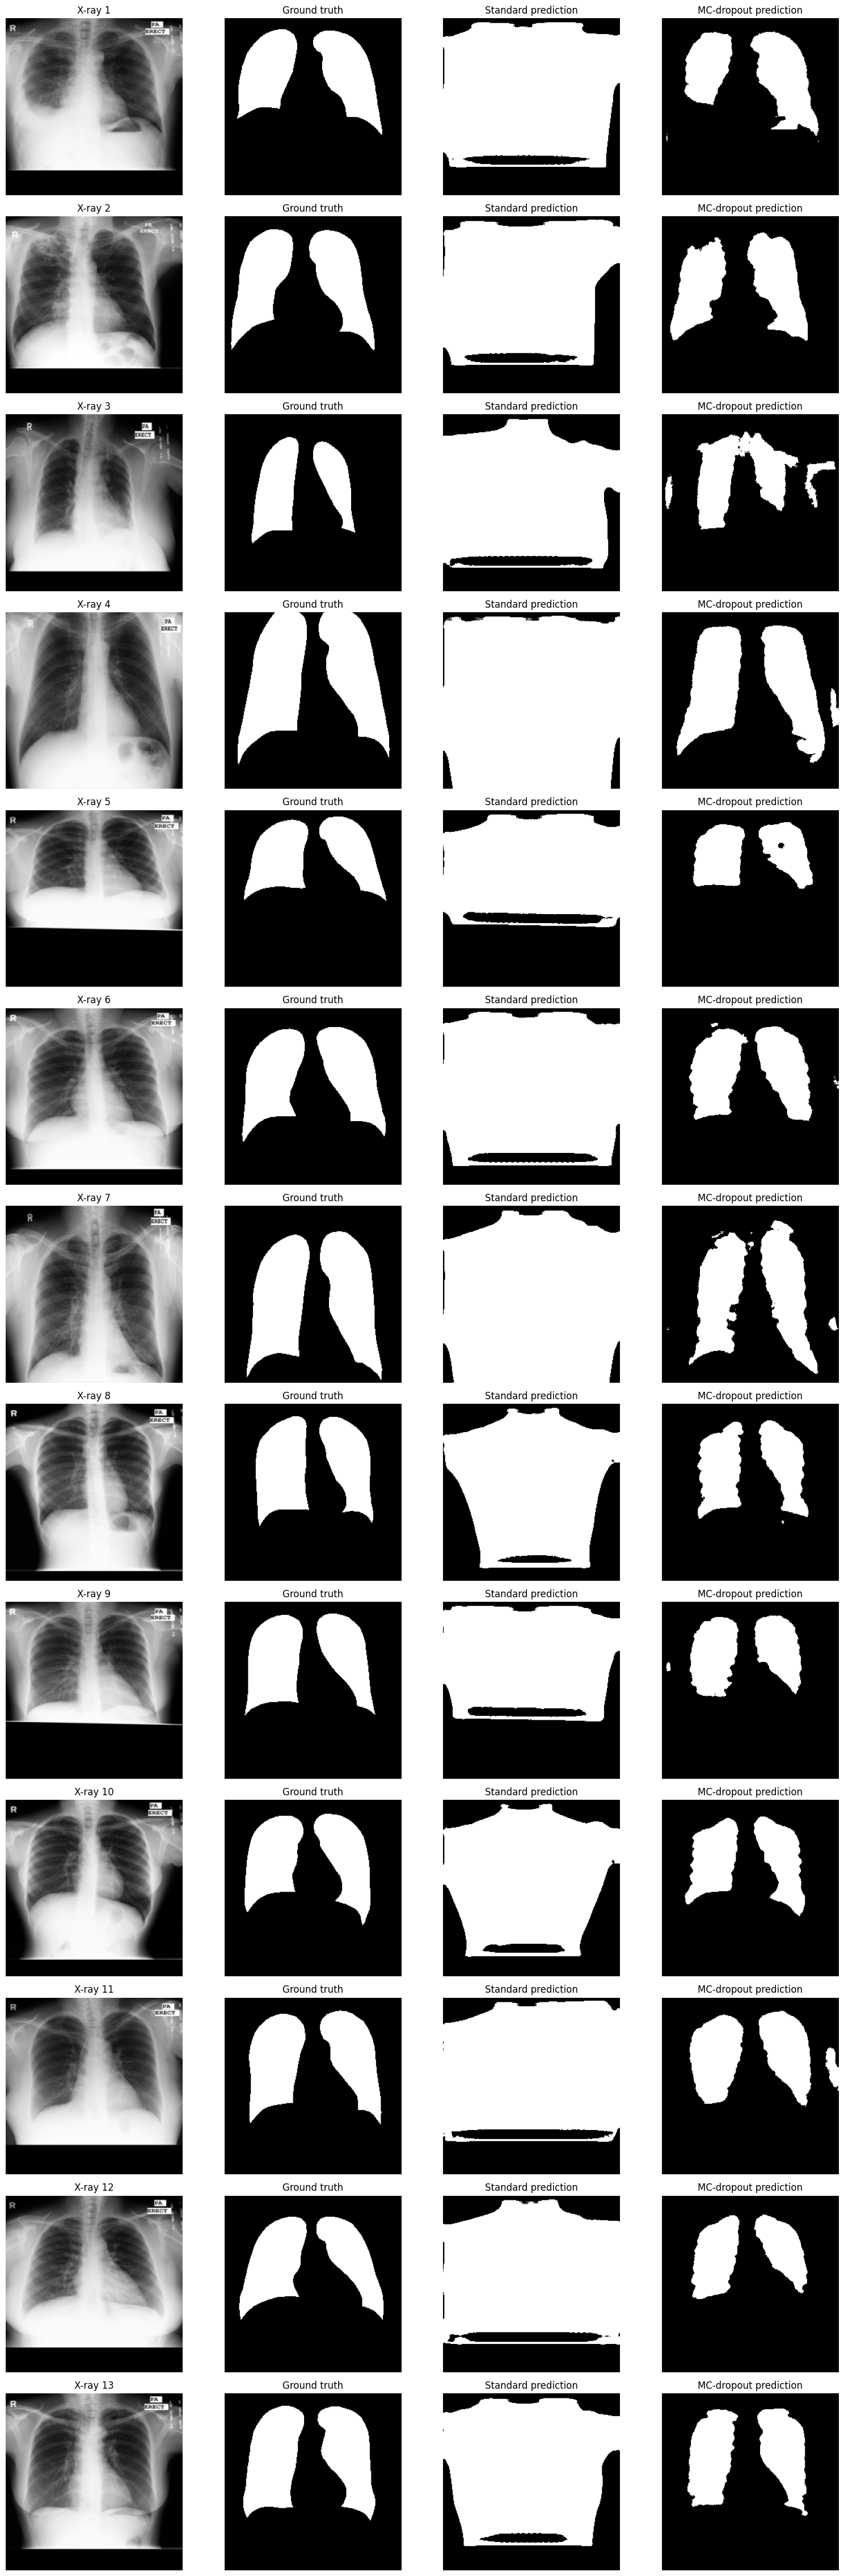

In [56]:
import matplotlib.pyplot as plt
import numpy as np

# Generate 20 dropout-active predictions and average them
viz_passes = []

for _ in range(20):
    probs = predict_in_mode(
        model_verify,
        X_val,
        training=True,
        batch_size=2
    )
    viz_passes.append(probs)

viz_mc_probs = np.mean(np.stack(viz_passes, axis=0), axis=0)

# Display all validation cases
n = len(X_val)
fig, axes = plt.subplots(n, 4, figsize=(16, 3.5 * n))

for i in range(n):
    axes[i, 0].imshow(X_val[i].squeeze(), cmap="gray")
    axes[i, 0].set_title(f"X-ray {i + 1}")

    axes[i, 1].imshow(Y_val[i].squeeze(), cmap="gray")
    axes[i, 1].set_title("Ground truth")

    axes[i, 2].imshow(
        standard_probs[i].squeeze() >= 0.5,
        cmap="gray"
    )
    axes[i, 2].set_title("Standard prediction")

    axes[i, 3].imshow(
        viz_mc_probs[i].squeeze() >= 0.5,
        cmap="gray"
    )
    axes[i, 3].set_title("MC-dropout prediction")

    for j in range(4):
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

In [57]:
# Diagnostic only: no training and no model changes.

train_standard_probs = predict_in_mode(
    model_verify,
    X_train[:8],
    training=False,
    batch_size=2
)

print("Training subset — standard inference")
report_metrics(
    "TRAIN subset standard inference",
    train_standard_probs,
    Y_train[:8]
)

print("\nForeground fraction per image:")
for i in range(len(train_standard_probs)):
    pred_fraction = np.mean(train_standard_probs[i] >= 0.5)
    true_fraction = np.mean(Y_train[i] >= 0.5)

    print(
        f"Image {i + 1}: "
        f"predicted={pred_fraction:.3f}, "
        f"actual={true_fraction:.3f}"
    )

Training subset — standard inference
TRAIN subset standard inference: Dice/image=0.5521, Pooled Dice=0.5505, Precision=0.3798, Recall=1.0000, Pred FG=0.735, GT FG=0.279

Foreground fraction per image:
Image 1: predicted=0.816, actual=0.275
Image 2: predicted=0.902, actual=0.384
Image 3: predicted=0.586, actual=0.269
Image 4: predicted=0.632, actual=0.274
Image 5: predicted=0.892, actual=0.303
Image 6: predicted=0.462, actual=0.166
Image 7: predicted=0.755, actual=0.308
Image 8: predicted=0.836, actual=0.254


In [58]:
# Diagnostic only — no training or architecture changes.

train_dropout_probs = predict_in_mode(
    model_verify,
    X_train[:8],
    training=True,
    batch_size=2
)

print("Training subset — dropout active")
report_metrics(
    "TRAIN subset dropout active",
    train_dropout_probs,
    Y_train[:8]
)

print("\nForeground fraction comparison:")
for i in range(8):
    standard_fg = np.mean(
        train_standard_probs[i] >= 0.5
    )
    dropout_fg = np.mean(
        train_dropout_probs[i] >= 0.5
    )
    actual_fg = np.mean(
        Y_train[i] >= 0.5
    )

    print(
        f"Image {i + 1}: "
        f"standard={standard_fg:.3f}, "
        f"dropout-active={dropout_fg:.3f}, "
        f"actual={actual_fg:.3f}"
    )

Training subset — dropout active
TRAIN subset dropout active: Dice/image=0.8461, Pooled Dice=0.8541, Precision=0.9369, Recall=0.7847, Pred FG=0.234, GT FG=0.279

Foreground fraction comparison:
Image 1: standard=0.816, dropout-active=0.251, actual=0.275
Image 2: standard=0.902, dropout-active=0.337, actual=0.384
Image 3: standard=0.586, dropout-active=0.220, actual=0.269
Image 4: standard=0.632, dropout-active=0.216, actual=0.274
Image 5: standard=0.892, dropout-active=0.241, actual=0.303
Image 6: standard=0.462, dropout-active=0.112, actual=0.166
Image 7: standard=0.755, dropout-active=0.290, actual=0.308
Image 8: standard=0.836, dropout-active=0.202, actual=0.254


In [59]:
import pandas as pd
from pathlib import Path

files = [
    Path("/content/drive/MyDrive/Lung_Segmentation_Research/"
         "UNetPlusPlus/logs/training_history_20261022_090555.csv"),
    Path("/content/drive/MyDrive/Lung_Segmentation_Research/"
         "UNetPlusPlus/experiments/experiment_02/logs/"
         "history_20261022_093907.csv")
]

for path in files:
    print(f"\n{'=' * 60}\n{path.name}")
    if not path.exists():
        print("File not found:", path)
        continue

    df = pd.read_csv(path)
    print("Columns:", df.columns.tolist())

    dice_cols = [
        c for c in df.columns
        if "val" in c.lower() and "dice" in c.lower()
    ]

    for col in dice_cols:
        idx = df[col].astype(float).idxmax()
        print(
            f"Best {col}: {df.loc[idx, col]:.5f} "
            f"at epoch {idx + 1}"
        )

    print("\nLast 3 epochs:")
    print(df.tail(3).to_string(index=False))


training_history_20261022_090555.csv
Columns: ['binary_accuracy', 'dice_coefficient', 'epoch', 'loss', 'precision', 'recall', 'val_binary_accuracy', 'val_dice_coefficient', 'val_loss', 'val_precision', 'val_recall']
Best val_dice_coefficient: 0.53170 at epoch 10

Last 3 epochs:
 binary_accuracy  dice_coefficient  epoch     loss  precision   recall  val_binary_accuracy  val_dice_coefficient  val_loss  val_precision  val_recall
        0.951002          0.862637     18 0.772744   0.937134 0.865731             0.538093              0.530225  3.607343       0.355831    0.999425
        0.951308          0.868859     19 0.757148   0.936958 0.867207             0.533850              0.527282  3.701530       0.353795    0.999986
        0.953129          0.868659     20 0.740879   0.940173 0.871460             0.508259              0.515477  4.083101       0.341671    0.999963

history_20261022_093907.csv
Columns: ['epoch', 'binary_accuracy', 'dice_per_image', 'loss', 'precision', 'recall', 

In [60]:
import json
from pathlib import Path

config_path = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research/"
    "UNetPlusPlus/logs/training_config_20261022_090555.json"
)

with open(config_path, "r") as f:
    config = json.load(f)

print(json.dumps(config, indent=2))

{
  "model": "UNet++",
  "input_shape": [
    256,
    256,
    1
  ],
  "train_samples": 110,
  "validation_samples": 13,
  "test_samples": 15,
  "epochs": 20,
  "batch_size": 2,
  "optimizer": "Adam",
  "learning_rate": 0.0002,
  "loss": "Binary Cross-Entropy + Dice Loss",
  "best_checkpoint_monitor": "val_dice_coefficient",
  "checkpoint_policy": "Save each completed epoch; preserve best validation Dice",
  "run_id": "20261022_090555"
}


verify the model-building function

In [61]:
from pathlib import Path

model_file = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research/"
    "UNetPlusPlus/unetplusplus_model.py"
)

print("Model file exists:", model_file.exists())

if model_file.exists():
    for line_no, line in enumerate(
        model_file.read_text().splitlines(), start=1
    ):
        if line.lstrip().startswith("def "):
            print(f"Line {line_no}: {line.strip()}")

Model file exists: True
Line 9: def standard_unit(input_tensor, stage, nb_filter, kernel_size=3):
Line 39: def UNetPlusPlus(img_rows, img_cols, color_type=1,


In [62]:
from pathlib import Path

model_file = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research/"
    "UNetPlusPlus/unetplusplus_model.py"
)

lines = model_file.read_text().splitlines()

# Print the UNetPlusPlus function and its return statement
start = next(
    i for i, line in enumerate(lines)
    if line.lstrip().startswith("def UNetPlusPlus(")
)

end = next(
    (i for i in range(start + 1, len(lines))
     if lines[i].lstrip().startswith("def ")),
    len(lines)
)

print("\n".join(
    f"{i + 1}: {lines[i]}"
    for i in range(start, end)
))

39: def UNetPlusPlus(img_rows, img_cols, color_type=1,
40:                  num_class=1, deep_supervision=False):
41: 
42:     bn_axis = 3
43:     img_input = layers.Input(
44:         shape=(img_rows, img_cols, color_type),
45:         name="main_input"
46:     )
47: 
48:     conv1_1 = standard_unit(img_input, "11", NB_FILTER[0])
49:     pool1 = layers.MaxPooling2D(
50:         (2, 2), strides=(2, 2), name="pool1"
51:     )(conv1_1)
52: 
53:     conv2_1 = standard_unit(pool1, "21", NB_FILTER[1])
54:     pool2 = layers.MaxPooling2D(
55:         (2, 2), strides=(2, 2), name="pool2"
56:     )(conv2_1)
57: 
58:     up1_2 = layers.Conv2DTranspose(
59:         NB_FILTER[0], (2, 2), strides=(2, 2),
60:         name="up12", padding="same"
61:     )(conv2_1)
62:     conv1_2 = layers.concatenate(
63:         [up1_2, conv1_1], name="merge12", axis=bn_axis
64:     )
65:     conv1_2 = standard_unit(conv1_2, "12", NB_FILTER[0])
66: 
67:     conv3_1 = standard_unit(pool2, "31", NB_FILTER[2])
68:    

In [63]:
import sys
import json
from pathlib import Path
import tensorflow as tf
from tensorflow import keras

project_dir = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research"
)
model_dir = project_dir / "UNetPlusPlus"
experiment_dir = model_dir / "experiments" / "experiment_03"

experiment_dir.mkdir(parents=True, exist_ok=True)

# Import the original architecture implementation
sys.path.insert(0, str(model_dir))

from unetplusplus_model import UNetPlusPlus

# Rebuild original UNet++ architecture
model_exp03 = UNetPlusPlus(
    img_rows=256,
    img_cols=256,
    color_type=1,
    num_class=1,
    deep_supervision=False
)

print("Architecture:", model_exp03.name)
print("Parameters:", model_exp03.count_params())
print("Output shape:", model_exp03.output_shape)
print("Experiment directory:", experiment_dir)

Architecture: functional_4
Parameters: 9041601
Output shape: (None, 256, 256, 1)
Experiment directory: /content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus/experiments/experiment_03


Compile Experiment 03

In [64]:
import tensorflow as tf
from tensorflow import keras
import json

# Existing BCE + Dice loss approach
def dice_coefficient(y_true, y_pred, smooth=1e-6):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)

    intersection = tf.reduce_sum(y_true * y_pred)
    denominator = tf.reduce_sum(y_true) + tf.reduce_sum(y_pred)

    return (2.0 * intersection + smooth) / (denominator + smooth)


def bce_dice_loss(y_true, y_pred):
    bce = tf.reduce_mean(
        keras.losses.binary_crossentropy(y_true, y_pred)
    )
    dice_loss = 1.0 - dice_coefficient(y_true, y_pred)
    return bce + dice_loss


# Compile original UNet++ architecture
model_exp03.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.00005),
    loss=bce_dice_loss,
    metrics=[
        dice_coefficient,
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall")
    ]
)

print("Experiment 03 compiled successfully.")
print("Learning rate:", 0.00005)
print("Loss: BCE + Dice")
print("Architecture parameters:", model_exp03.count_params())

Experiment 03 compiled successfully.
Learning rate: 5e-05
Loss: BCE + Dice
Architecture parameters: 9041601


Callbacks setup

In [65]:
from pathlib import Path
from tensorflow import keras
import json

exp03_checkpoints = experiment_dir / "checkpoints"
exp03_logs = experiment_dir / "logs"

exp03_checkpoints.mkdir(parents=True, exist_ok=True)
exp03_logs.mkdir(parents=True, exist_ok=True)

callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=str(exp03_checkpoints / "best_model.keras"),
        monitor="val_dice_coefficient",
        mode="max",
        save_best_only=True,
        verbose=1
    ),

    keras.callbacks.CSVLogger(
        str(exp03_logs / "training_history.csv")
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_dice_coefficient",
        mode="max",
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]

config = {
    "experiment": "UNet++ Experiment 03",
    "architecture": "Original UNet++",
    "parameters": int(model_exp03.count_params()),
    "input_shape": [256, 256, 1],
    "train_samples": int(len(X_train)),
    "validation_samples": int(len(X_val)),
    "test_samples": int(len(X_test)),
    "max_epochs": 30,
    "batch_size": 2,
    "optimizer": "Adam",
    "initial_learning_rate": 0.00005,
    "loss": "Binary Cross-Entropy + batch-global Dice Loss",
    "checkpoint_monitor": "val_dice_coefficient",
    "early_stopping_patience": 7,
    "note": "Architecture and existing dataset split unchanged"
}

with open(exp03_logs / "training_config.json", "w") as f:
    json.dump(config, f, indent=2)

print("Callbacks ready.")
print("Checkpoint:", exp03_checkpoints / "best_model.keras")
print("History:", exp03_logs / "training_history.csv")
print("Config saved:", exp03_logs / "training_config.json")

Callbacks ready.
Checkpoint: /content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus/experiments/experiment_03/checkpoints/best_model.keras
History: /content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus/experiments/experiment_03/logs/training_history.csv
Config saved: /content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus/experiments/experiment_03/logs/training_config.json


Train UNet++

In [66]:
history_exp03 = model_exp03.fit(
    X_train,
    Y_train,
    validation_data=(X_val, Y_val),
    epochs=30,
    batch_size=2,
    callbacks=callbacks,
    shuffle=True,
    verbose=1
)

Epoch 1/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step - dice_coefficient: 0.2694 - loss: 5.6974 - precision: 0.2514 - recall: 0.2815
Epoch 1: val_dice_coefficient improved from None to 0.33462, saving model to /content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus/experiments/experiment_03/checkpoints/best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus/experiments/experiment_03/checkpoints/best_model.keras
55/55 ━━━━━━━━━━━━━━━━━━━━ 53s 314ms/step - dice_coefficient: 0.2737 - loss: 3.7020 - precision: 0.2518 - recall: 0.2668 - val_dice_coefficient: 0.3346 - val_loss: 1.9798 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 5.0000e-05
Epoch 2/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 185ms/step - dice_coefficient: 0.2981 - loss: 2.2195 - precision: 0.2527 - recall: 0.2453
Epoch 2: val_dice_coefficient improved from 0.33462 to 0.33632, saving model to /content/drive/MyDrive/Lung_Segmentation_Research/UNetPlus

In [67]:
import numpy as np
from tensorflow import keras

best_path = (
    "/content/drive/MyDrive/Lung_Segmentation_Research/"
    "UNetPlusPlus/experiments/experiment_03/"
    "checkpoints/best_model.keras"
)

model_exp03_best = keras.models.load_model(
    best_path,
    custom_objects={
        "bce_dice_loss": bce_dice_loss,
        "dice_coefficient": dice_coefficient
    },
    compile=False
)

val_probs = model_exp03_best.predict(
    X_val, batch_size=2, verbose=0
)

print("Probability min:", float(val_probs.min()))
print("Probability max:", float(val_probs.max()))
print("Probability mean:", float(val_probs.mean()))
print("Probability median:", float(np.median(val_probs)))
print("Predicted foreground at 0.5:",
      float(np.mean(val_probs >= 0.5)))
print("Ground-truth foreground:",
      float(np.mean(Y_val)))

for threshold in [0.1, 0.2, 0.3, 0.4, 0.5]:
    print(
        f"Threshold {threshold:.1f}: "
        f"foreground fraction = "
        f"{np.mean(val_probs >= threshold):.4f}"
    )

Probability min: 0.37901201844215393
Probability max: 0.4998458921909332
Probability mean: 0.4542984366416931
Probability median: 0.460055947303772
Predicted foreground at 0.5: 0.0
Ground-truth foreground: 0.2552173435688019
Threshold 0.1: foreground fraction = 1.0000
Threshold 0.2: foreground fraction = 1.0000
Threshold 0.3: foreground fraction = 1.0000
Threshold 0.4: foreground fraction = 0.9092
Threshold 0.5: foreground fraction = 0.0000


diagnostic

In [68]:
import numpy as np
from tensorflow import keras

best_path = (
    "/content/drive/MyDrive/Lung_Segmentation_Research/"
    "UNetPlusPlus/experiments/experiment_03/"
    "checkpoints/best_model.keras"
)

model_exp03_best = keras.models.load_model(
    best_path,
    custom_objects={
        "bce_dice_loss": bce_dice_loss,
        "dice_coefficient": dice_coefficient
    },
    compile=False
)

val_probs = model_exp03_best.predict(
    X_val, batch_size=2, verbose=0
)

print("Probability min:", float(val_probs.min()))
print("Probability max:", float(val_probs.max()))
print("Probability mean:", float(val_probs.mean()))
print("Probability median:", float(np.median(val_probs)))
print("Predicted foreground at 0.5:",
      float(np.mean(val_probs >= 0.5)))
print("Ground-truth foreground:",
      float(np.mean(Y_val)))

for threshold in [0.1, 0.2, 0.3, 0.4, 0.5]:
    print(
        f"Threshold {threshold:.1f}: "
        f"foreground fraction = "
        f"{np.mean(val_probs >= threshold):.4f}"
    )

Probability min: 0.37901201844215393
Probability max: 0.4998458921909332
Probability mean: 0.4542984366416931
Probability median: 0.460055947303772
Predicted foreground at 0.5: 0.0
Ground-truth foreground: 0.2552173435688019
Threshold 0.1: foreground fraction = 1.0000
Threshold 0.2: foreground fraction = 1.0000
Threshold 0.3: foreground fraction = 1.0000
Threshold 0.4: foreground fraction = 0.9092
Threshold 0.5: foreground fraction = 0.0000


In [69]:
import numpy as np

def threshold_metrics(probs, targets, threshold):
    pred = (probs >= threshold).astype(np.float32)
    true = (targets >= 0.5).astype(np.float32)

    axes = (1, 2, 3)
    intersection = np.sum(pred * true, axis=axes)
    pred_sum = np.sum(pred, axis=axes)
    true_sum = np.sum(true, axis=axes)

    dice = (2 * intersection + 1e-7) / (
        pred_sum + true_sum + 1e-7
    )
    return float(np.mean(dice)), float(np.mean(pred))

print("Threshold | Mean Dice | Predicted foreground")
for threshold in np.arange(0.38, 0.501, 0.01):
    dice, fg = threshold_metrics(val_probs, Y_val, threshold)
    print(f"{threshold:.2f}      | {dice:.4f}    | {fg:.4f}")

Threshold | Mean Dice | Predicted foreground
0.38      | 0.4039    | 1.0000
0.39      | 0.4039    | 0.9998
0.40      | 0.4348    | 0.9092
0.41      | 0.4617    | 0.8376
0.42      | 0.4897    | 0.7647
0.43      | 0.5186    | 0.6900
0.44      | 0.5420    | 0.6214
0.45      | 0.5560    | 0.5564
0.46      | 0.5499    | 0.5003
0.47      | 0.5124    | 0.4423
0.48      | 0.4274    | 0.3739
0.49      | 0.3572    | 0.1906
0.50      | 0.0000    | 0.0000


Baseline vs Experiment 03

In [70]:
import numpy as np
from tensorflow import keras

baseline_path = (
    "/content/drive/MyDrive/Lung_Segmentation_Research/"
    "UNetPlusPlus/checkpoints/run_20261022_090555/"
    "best_model.keras"
)

exp03_path = (
    "/content/drive/MyDrive/Lung_Segmentation_Research/"
    "UNetPlusPlus/experiments/experiment_03/"
    "checkpoints/best_model.keras"
)

baseline_model = keras.models.load_model(
    baseline_path, compile=False
)

exp03_model = keras.models.load_model(
    exp03_path, compile=False
)

def evaluate_threshold(probs, targets, threshold=0.5):
    pred = (probs >= threshold).astype(np.float32)
    true = (targets >= 0.5).astype(np.float32)

    axes = (1, 2, 3)
    intersection = np.sum(pred * true, axis=axes)
    pred_sum = np.sum(pred, axis=axes)
    true_sum = np.sum(true, axis=axes)

    dice = (2 * intersection + 1e-7) / (
        pred_sum + true_sum + 1e-7
    )

    tp = np.sum(pred * true)
    fp = np.sum(pred * (1 - true))
    fn = np.sum((1 - pred) * true)

    precision = tp / (tp + fp + 1e-7)
    recall = tp / (tp + fn + 1e-7)

    return {
        "dice_image": float(np.mean(dice)),
        "pooled_dice": float(
            (2 * tp + 1e-7) /
            (2 * tp + fp + fn + 1e-7)
        ),
        "precision": float(precision),
        "recall": float(recall),
        "predicted_foreground": float(np.mean(pred))
    }

baseline_probs = baseline_model.predict(
    X_val, batch_size=2, verbose=0
)
exp03_probs = exp03_model.predict(
    X_val, batch_size=2, verbose=0
)

for name, probs in [
    ("Baseline", baseline_probs),
    ("Experiment 03", exp03_probs)
]:
    print(f"\n===== {name}: threshold 0.50 =====")
    print(evaluate_threshold(probs, Y_val, 0.5))


===== Baseline: threshold 0.50 =====
{'dice_image': 0.5270200967788696, 'pooled_dice': 0.5287252068519592, 'precision': 0.35974884033203125, 'recall': 0.9970428347587585, 'predicted_foreground': 0.7073341012001038}

===== Experiment 03: threshold 0.50 =====
{'dice_image': 6.23002777838666e-12, 'pooled_dice': 4.599033285278276e-13, 'precision': 0.0, 'recall': 0.0, 'predicted_foreground': 0.0}


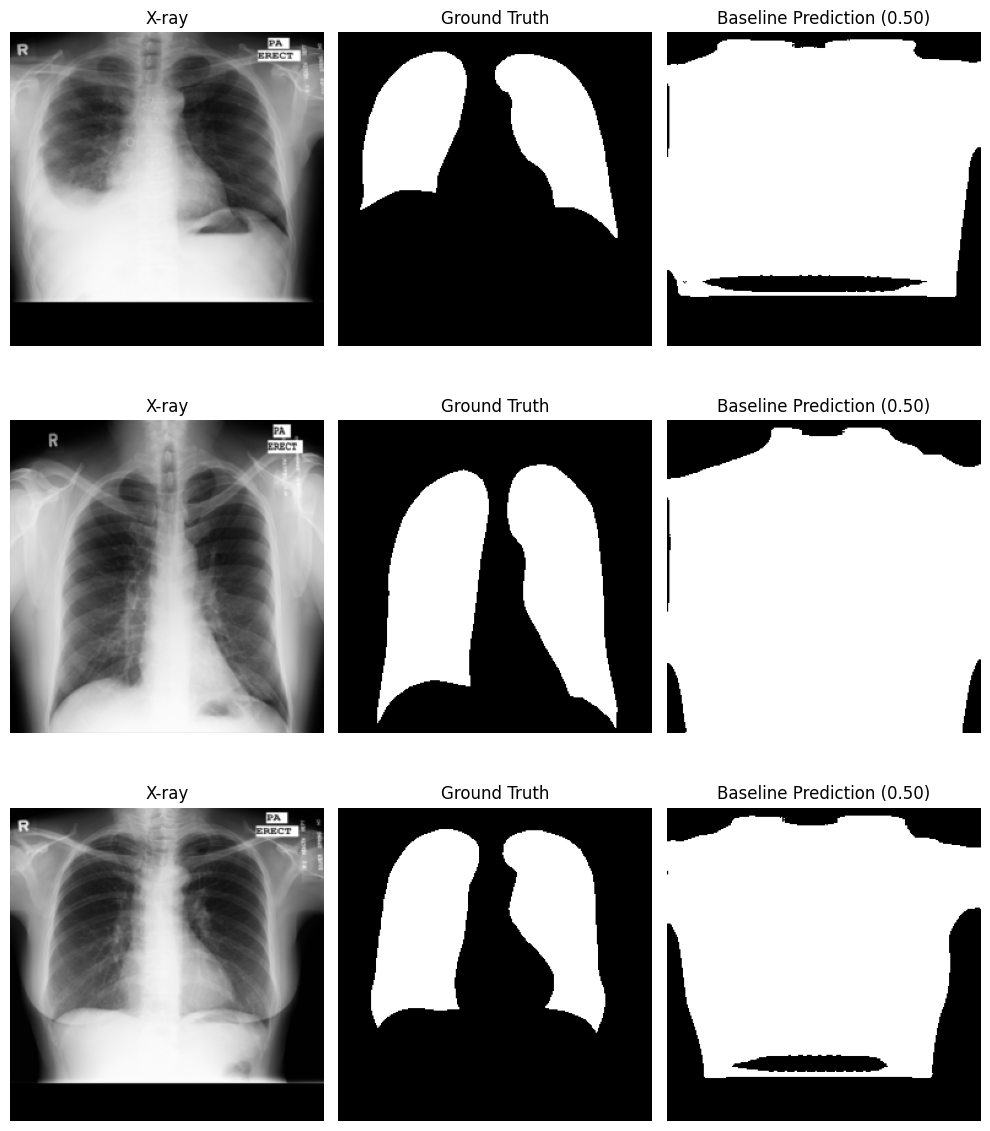

In [71]:
import matplotlib.pyplot as plt
import numpy as np

# Use the baseline predictions already calculated above.
indices = [0, len(X_val)//2, len(X_val)-1]

fig, axes = plt.subplots(len(indices), 3, figsize=(10, 4 * len(indices)))

for row, idx in enumerate(indices):
    axes[row, 0].imshow(X_val[idx].squeeze(), cmap="gray")
    axes[row, 0].set_title("X-ray")

    axes[row, 1].imshow(Y_val[idx].squeeze(), cmap="gray")
    axes[row, 1].set_title("Ground Truth")

    axes[row, 2].imshow(
        (baseline_probs[idx].squeeze() >= 0.5),
        cmap="gray"
    )
    axes[row, 2].set_title("Baseline Prediction (0.50)")

    for col in range(3):
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

inspect probability distributions

In [72]:
import numpy as np

indices = [0, len(X_val)//2, len(X_val)-1]

for idx in indices:
    prob = baseline_probs[idx].squeeze()
    gt = Y_val[idx].squeeze() >= 0.5

    print(f"\nValidation image {idx}")
    print(f"Ground-truth lung pixels: {gt.mean():.3f}")
    print(f"Mean probability inside lungs: {prob[gt].mean():.4f}")
    print(f"Mean probability outside lungs: {prob[~gt].mean():.4f}")
    print(f"Probability range: {prob.min():.4f} to {prob.max():.4f}")
    print(f"Pixels predicted as lung at 0.50: {(prob >= 0.5).mean():.3f}")


Validation image 0
Ground-truth lung pixels: 0.234
Mean probability inside lungs: 0.9989
Mean probability outside lungs: 0.6444
Probability range: 0.0000 to 0.9996
Pixels predicted as lung at 0.50: 0.728

Validation image 6
Ground-truth lung pixels: 0.349
Mean probability inside lungs: 0.9990
Mean probability outside lungs: 0.8210
Probability range: 0.0000 to 0.9996
Pixels predicted as lung at 0.50: 0.883

Validation image 12
Ground-truth lung pixels: 0.275
Mean probability inside lungs: 0.9990
Mean probability outside lungs: 0.5498
Probability range: 0.0000 to 0.9996
Pixels predicted as lung at 0.50: 0.676


Inspect the training setup

In [73]:
import pandas as pd

history_path = (
    "/content/drive/MyDrive/Lung_Segmentation_Research/"
    "UNetPlusPlus/logs/training_history_20261022_090555.csv"
)

history = pd.read_csv(history_path)

print("Available columns:")
print(history.columns.tolist())

print("\nFirst 5 epochs:")
display(history.head())

print("\nBest validation Dice epoch:")
display(history.loc[history["val_dice_coefficient"].idxmax()])

print("\nLast 5 epochs:")
display(history.tail())

Available columns:
['binary_accuracy', 'dice_coefficient', 'epoch', 'loss', 'precision', 'recall', 'val_binary_accuracy', 'val_dice_coefficient', 'val_loss', 'val_precision', 'val_recall']

First 5 epochs:


,binary_accuracy,dice_coefficient,epoch,loss,precision,recall,val_binary_accuracy,val_dice_coefficient,val_loss,val_precision,val_recall
0,0.629585,0.320650,1,2.568571,0.257606,0.241288,0.744783,0.337907,2.015791,0.000000,0.000000
1,0.704290,0.320569,2,1.983429,0.266318,0.091639,0.744783,0.342811,1.975760,0.000000,0.000000
2,0.724279,0.343847,3,1.869003,0.275621,0.050579,0.745767,0.390170,1.843221,0.713921,0.006439
3,0.753995,0.415741,4,1.677191,0.584962,0.118073,0.616776,0.395539,1.826549,0.399192,0.993078
4,0.830164,0.476700,5,1.553702,0.766880,0.478872,0.475154,0.401778,1.831615,0.327131,0.999609



Best validation Dice epoch:


,9
binary_accuracy,0.931935
dice_coefficient,0.806274
epoch,10.000000
loss,0.991203
precision,0.895184
recall,0.829989
val_binary_accuracy,0.546374
val_dice_coefficient,0.531700
val_loss,3.783710
val_precision,0.359749



Last 5 epochs:


,binary_accuracy,dice_coefficient,epoch,loss,precision,recall,val_binary_accuracy,val_dice_coefficient,val_loss,val_precision,val_recall
15,0.948575,0.855128,16,0.814393,0.936797,0.855873,0.502539,0.518366,3.924099,0.338997,0.999250
16,0.950139,0.860947,17,0.792508,0.940099,0.859001,0.509823,0.520472,4.072494,0.342328,0.999402
17,0.951002,0.862637,18,0.772744,0.937134,0.865731,0.538093,0.530225,3.607343,0.355831,0.999425
18,0.951308,0.868859,19,0.757148,0.936958,0.867207,0.533850,0.527282,3.701530,0.353795,0.999986
19,0.953129,0.868659,20,0.740879,0.940173,0.871460,0.508259,0.515477,4.083101,0.341671,0.999963


In [74]:
import numpy as np

print("===== DATA SHAPES =====")
print("X_train:", X_train.shape)
print("Y_train:", Y_train.shape)
print("X_val:  ", X_val.shape)
print("Y_val:  ", Y_val.shape)

print("\n===== IMAGE VALUES =====")
print("X_train range:", X_train.min(), X_train.max())
print("X_val range:  ", X_val.min(), X_val.max())
print("X_train mean:", X_train.mean())
print("X_val mean:  ", X_val.mean())

print("\n===== MASK VALUES =====")
print("Y_train unique sample:", np.unique(Y_train)[:20])
print("Y_val unique sample:  ", np.unique(Y_val)[:20])

print("\n===== FOREGROUND RATIOS =====")
print("Train foreground:", np.mean(Y_train >= 0.5))
print("Val foreground:  ", np.mean(Y_val >= 0.5))

print("\n===== FIRST SAMPLE =====")
print("Image shape:", X_train[0].shape)
print("Mask shape: ", Y_train[0].shape)

===== DATA SHAPES =====
X_train: (110, 256, 256, 1)
Y_train: (110, 256, 256, 1)
X_val:   (13, 256, 256, 1)
Y_val:   (13, 256, 256, 1)

===== IMAGE VALUES =====
X_train range: 0.0 1.0
X_val range:   0.0 1.0
X_train mean: 0.44204983
X_val mean:   0.46345726

===== MASK VALUES =====
Y_train unique sample: [0. 1.]
Y_val unique sample:   [0. 1.]

===== FOREGROUND RATIOS =====
Train foreground: 0.254742431640625
Val foreground:   0.2552173321063702

===== FIRST SAMPLE =====
Image shape: (256, 256, 1)
Mask shape:  (256, 256, 1)


inspect the original loss and metrics

In [75]:
from pathlib import Path

source_path = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research/"
    "UNetPlusPlus/unetplusplus_model.py"
)

source = source_path.read_text(encoding="utf-8")
lines = source.splitlines()

keywords = [
    "def dice_coefficient",
    "def bce_dice_loss",
    "def iou",
    "def precision",
    "def recall",
    "def UNetPlusPlus",
    "Dropout",
    "regularizers.l2",
]

for keyword in keywords:
    matches = [
        i for i, line in enumerate(lines)
        if keyword.lower() in line.lower()
    ]

    for i in matches:
        start = max(0, i - 3)
        end = min(len(lines), i + 12)

        print(f"\n{'=' * 20} Line {i + 1}: {keyword} {'=' * 20}")
        print("\n".join(
            f"{j + 1}: {lines[j]}"
            for j in range(start, end)
        ))


==================== Line 39: def UNetPlusPlus ====================
36:     return x
37: 
38: 
39: def UNetPlusPlus(img_rows, img_cols, color_type=1,
40:                  num_class=1, deep_supervision=False):
41: 
42:     bn_axis = 3
43:     img_input = layers.Input(
44:         shape=(img_rows, img_cols, color_type),
45:         name="main_input"
46:     )
47: 
48:     conv1_1 = standard_unit(img_input, "11", NB_FILTER[0])
49:     pool1 = layers.MaxPooling2D(
50:         (2, 2), strides=(2, 2), name="pool1"

==================== Line 7: Dropout ====================
4: 
5: NB_FILTER = [32, 64, 128, 256, 512]
6: ACT = "relu"
7: DROPOUT_RATE = 0.5
8: 
9: def standard_unit(input_tensor, stage, nb_filter, kernel_size=3):
10:     x = layers.Conv2D(
11:         nb_filter, (kernel_size, kernel_size),
12:         activation=ACT,
13:         name="conv" + stage + "_1",
14:         kernel_initializer="he_normal",
15:         padding="same",
16:         kernel_regularizer=l2(1e-4),
17:     )(inp

inspect the baseline training configuration

In [76]:
import json
from pathlib import Path

root = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus"
)

config_path = (
    root / "logs" / "training_config_20261022_090555.json"
)

print("===== SAVED TRAINING CONFIG =====")
if config_path.exists():
    config = json.loads(config_path.read_text())
    print(json.dumps(config, indent=2))
else:
    print("Config file not found:", config_path)

print("\n===== TRAINING NOTEBOOKS =====")
for p in root.rglob("*.ipynb"):
    if "checkpoint" not in str(p).lower():
        print(p)

===== SAVED TRAINING CONFIG =====
{
  "model": "UNet++",
  "input_shape": [
    256,
    256,
    1
  ],
  "train_samples": 110,
  "validation_samples": 13,
  "test_samples": 15,
  "epochs": 20,
  "batch_size": 2,
  "optimizer": "Adam",
  "learning_rate": 0.0002,
  "loss": "Binary Cross-Entropy + Dice Loss",
  "best_checkpoint_monitor": "val_dice_coefficient",
  "checkpoint_policy": "Save each completed epoch; preserve best validation Dice",
  "run_id": "20261022_090555"
}

===== TRAINING NOTEBOOKS =====


inspect the compiled model

In [77]:
print("===== MODEL COMPILE CONFIG =====")

try:
    print(baseline_model.get_compile_config())
except Exception as e:
    print("Compile config unavailable:", e)

print("\n===== OUTPUT ACTIVATION =====")
print("Output shape:", baseline_model.output_shape)
print("Final layer:", baseline_model.layers[-1].name)
print("Final activation:", getattr(
    baseline_model.layers[-1], "activation", None
))

print("\n===== LOSS FUNCTIONS IN CURRENT SESSION =====")
for name in ["dice_coefficient", "bce_dice_loss"]:
    fn = globals().get(name)
    print(f"\n{name}:")
    if fn is None:
        print("Not defined in current session")
    else:
        import inspect
        try:
            print(inspect.getsource(fn))
        except Exception:
            print(fn)

===== MODEL COMPILE CONFIG =====
{}

===== OUTPUT ACTIVATION =====
Output shape: (None, 256, 256, 1)
Final layer: output_4
Final activation: <function sigmoid at 0x7819a919fb00>

===== LOSS FUNCTIONS IN CURRENT SESSION =====

dice_coefficient:
def dice_coefficient(y_true, y_pred, smooth=1e-6):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)

    intersection = tf.reduce_sum(y_true * y_pred)
    denominator = tf.reduce_sum(y_true) + tf.reduce_sum(y_pred)

    return (2.0 * intersection + smooth) / (denominator + smooth)


bce_dice_loss:
def bce_dice_loss(y_true, y_pred):
    bce = tf.reduce_mean(
        keras.losses.binary_crossentropy(y_true, y_pred)
    )
    dice_loss = 1.0 - dice_coefficient(y_true, y_pred)
    return bce + dice_loss



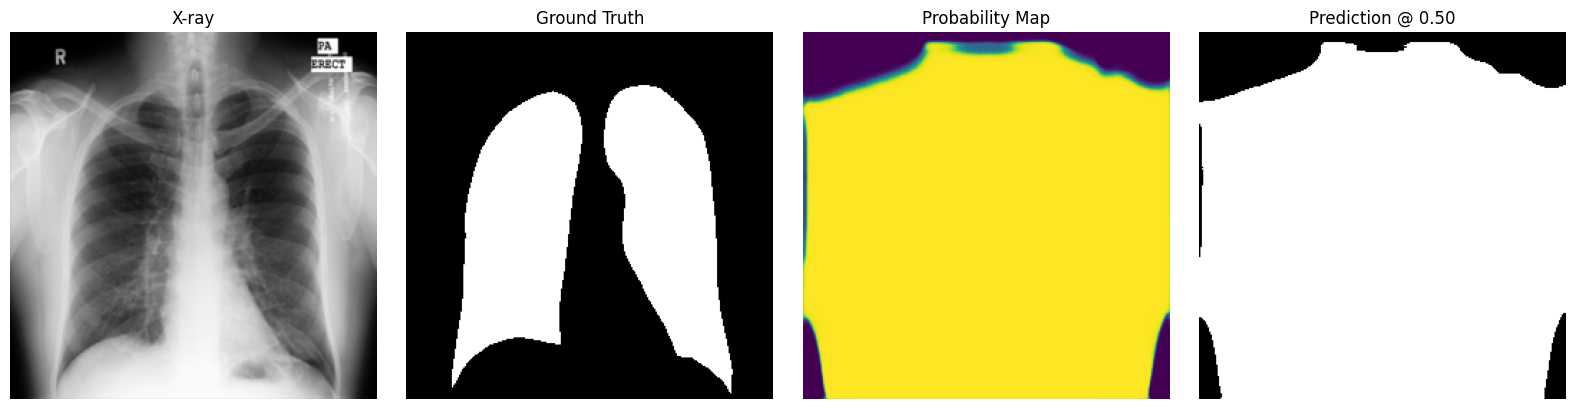

In [78]:
import matplotlib.pyplot as plt
import numpy as np

idx = 6  # Same validation image inspected earlier

image = X_val[idx].squeeze()
mask = Y_val[idx].squeeze()
prob = baseline_probs[idx].squeeze()
pred = (prob >= 0.5).astype(np.float32)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("X-ray")

axes[1].imshow(mask, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Ground Truth")

axes[2].imshow(prob, cmap="viridis", vmin=0, vmax=1)
axes[2].set_title("Probability Map")

axes[3].imshow(pred, cmap="gray", vmin=0, vmax=1)
axes[3].set_title("Prediction @ 0.50")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

verify mask alignment and preprocessing

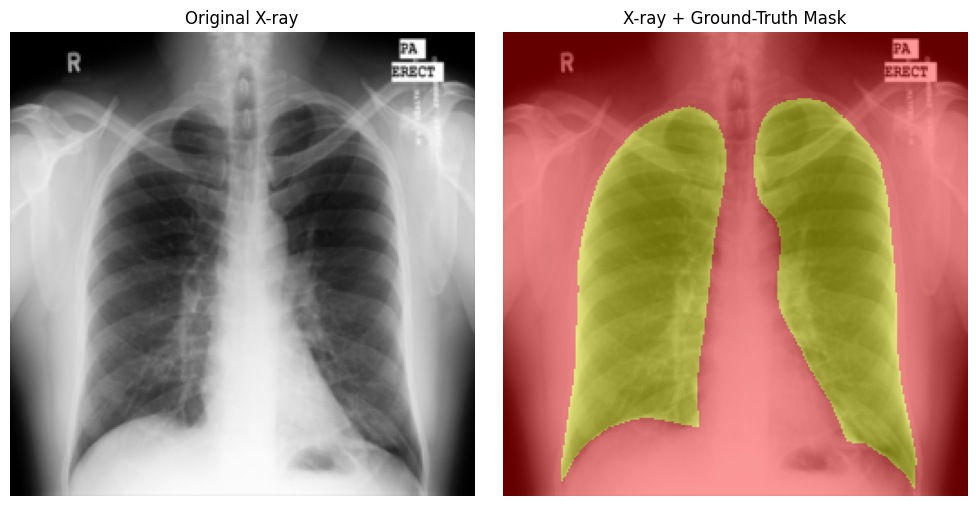

In [79]:
import matplotlib.pyplot as plt
import numpy as np

idx = 6

image = X_val[idx].squeeze()
mask = Y_val[idx].squeeze()

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("Original X-ray")
axes[0].axis("off")

axes[1].imshow(image, cmap="gray")
axes[1].imshow(mask, cmap="autumn", alpha=0.4)
axes[1].set_title("X-ray + Ground-Truth Mask")
axes[1].axis("off")

plt.tight_layout()
plt.show()

DIAGNOSIS


In [80]:
import numpy as np
import tensorflow as tf

# Diagnostic only: no training, no weight updates, no checkpoint changes.
N = min(20, len(X_train))
BATCH_SIZE = 2

def get_predictions(model, images, training_mode=False, repeats=1):
    all_runs = []

    for _ in range(repeats):
        batches = []
        for start in range(0, len(images), BATCH_SIZE):
            xb = tf.convert_to_tensor(
                images[start:start + BATCH_SIZE],
                dtype=tf.float32
            )
            probs = model(xb, training=training_mode).numpy()
            batches.append(probs)

        all_runs.append(np.concatenate(batches, axis=0))

    return np.mean(all_runs, axis=0) if repeats > 1 else all_runs[0]


def report_metrics(name, probs, targets, threshold=0.5):
    pred = (probs >= threshold).astype(np.float32)
    true = (targets >= 0.5).astype(np.float32)

    axes = (1, 2, 3)
    intersection = np.sum(pred * true, axis=axes)
    pred_sum = np.sum(pred, axis=axes)
    true_sum = np.sum(true, axis=axes)

    dice = (2 * intersection + 1e-7) / (
        pred_sum + true_sum + 1e-7
    )

    tp = np.sum(pred * true)
    fp = np.sum(pred * (1 - true))
    fn = np.sum((1 - pred) * true)

    print(f"\n{name}")
    print(f"Mean image Dice:       {np.mean(dice):.4f}")
    print(f"Pooled Dice:           {(2*tp+1e-7)/(2*tp+fp+fn+1e-7):.4f}")
    print(f"Precision:             {tp/(tp+fp+1e-7):.4f}")
    print(f"Recall:                {tp/(tp+fn+1e-7):.4f}")
    print(f"Predicted foreground:  {np.mean(pred):.4f}")
    print(f"Ground-truth foreground: {np.mean(true):.4f}")


X_diag = X_train[:N]
Y_diag = Y_train[:N]

eval_probs = get_predictions(
    baseline_model, X_diag, training_mode=False
)

dropout_probs = get_predictions(
    baseline_model, X_diag, training_mode=True, repeats=3
)

print(f"Fixed training subset: {N} images")
report_metrics("NORMAL INFERENCE (dropout OFF)", eval_probs, Y_diag)
report_metrics("DROPOUT-ON DIAGNOSTIC (3-pass average)", dropout_probs, Y_diag)

print("\nProbability means:")
print("Normal inference:", float(np.mean(eval_probs)))
print("Dropout-on average:", float(np.mean(dropout_probs)))

Fixed training subset: 20 images

NORMAL INFERENCE (dropout OFF)
Mean image Dice:       0.5500
Pooled Dice:           0.5500
Precision:             0.3794
Recall:                0.9994
Predicted foreground:  0.6587
Ground-truth foreground: 0.2501

DROPOUT-ON DIAGNOSTIC (3-pass average)
Mean image Dice:       0.8680
Pooled Dice:           0.8744
Precision:             0.9557
Recall:                0.8059
Predicted foreground:  0.2109
Ground-truth foreground: 0.2501

Probability means:
Normal inference: 0.6583693623542786
Dropout-on average: 0.22246801853179932


NameError: name 'y_val' is not defined

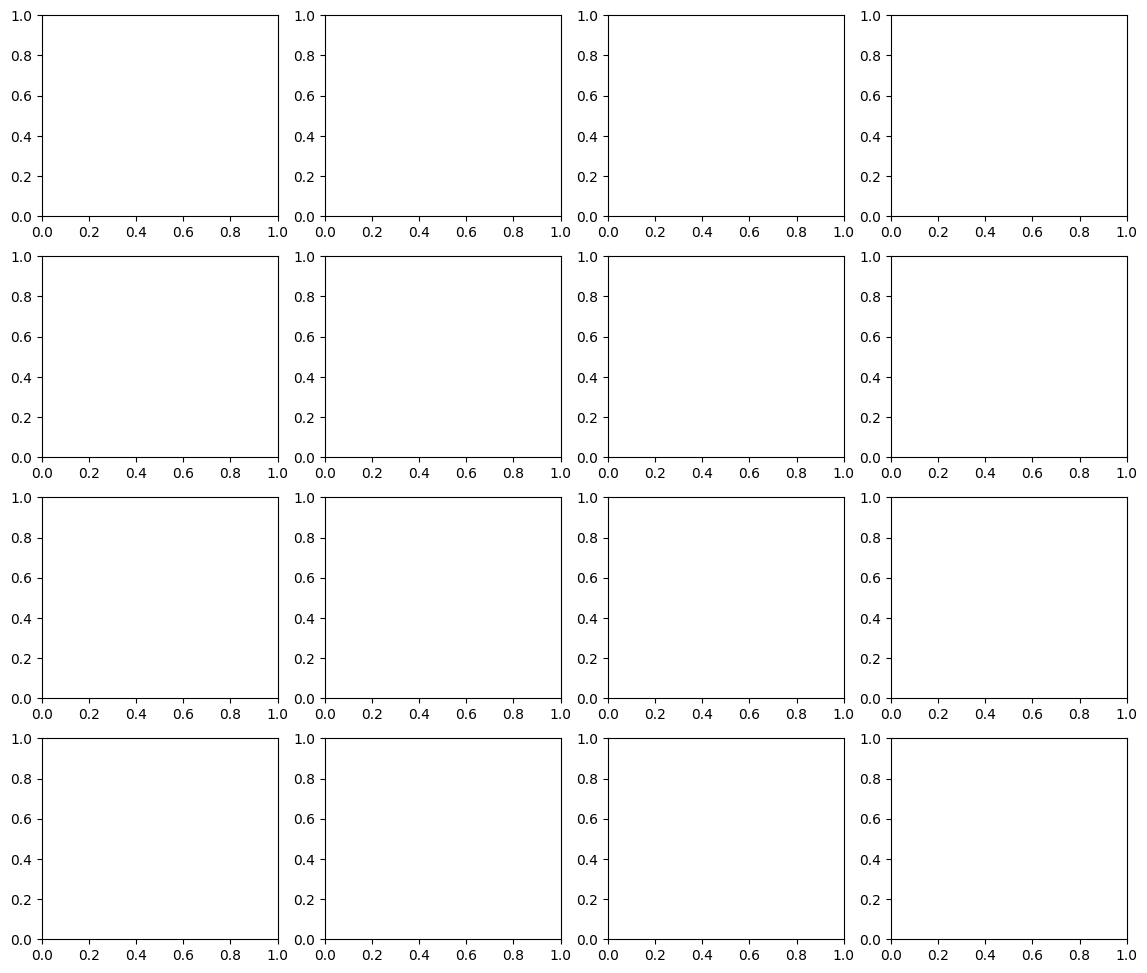

In [81]:
import matplotlib.pyplot as plt
import numpy as np

# Uses the already-loaded baseline_model and validation arrays.
# If your array names differ, replace X_val and y_val accordingly.
sample_indices = [0, 1, 2, 3]

fig, axes = plt.subplots(len(sample_indices), 4, figsize=(14, 12))

for row, idx in enumerate(sample_indices):
    image = X_val[idx]
    ground_truth = y_val[idx]

    if image.ndim == 3:
        image_batch = image[None, ...]
    else:
        image_batch = image[None, ..., None]

    # Normal inference
    normal_pred = baseline_model(
        image_batch, training=False
    ).numpy()[0, ..., 0]

    # MC dropout: average 20 stochastic predictions
    stochastic_preds = [
        baseline_model(image_batch, training=True).numpy()[0, ..., 0]
        for _ in range(20)
    ]
    dropout_pred = np.mean(stochastic_preds, axis=0)

    axes[row, 0].imshow(image.squeeze(), cmap="gray")
    axes[row, 0].set_title("X-ray")

    axes[row, 1].imshow(ground_truth.squeeze(), cmap="gray")
    axes[row, 1].set_title("Ground truth")

    axes[row, 2].imshow(normal_pred >= 0.5, cmap="gray")
    axes[row, 2].set_title("Normal inference")

    axes[row, 3].imshow(dropout_pred >= 0.5, cmap="gray")
    axes[row, 3].set_title("Dropout-on average")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [82]:
# Find existing image/mask arrays without changing anything
for name, obj in list(globals().items()):
    if not name.startswith("_") and hasattr(obj, "shape"):
        try:
            shape = obj.shape
            if len(shape) >= 3:
                print(f"{name}: shape={shape}, dtype={getattr(obj, 'dtype', 'unknown')}")
        except Exception:
            pass

image: shape=(256, 256, 1), dtype=float32
X_train: shape=(110, 256, 256, 1), dtype=float32
Y_train: shape=(110, 256, 256, 1), dtype=float32
X_val: shape=(13, 256, 256, 1), dtype=float32
Y_val: shape=(13, 256, 256, 1), dtype=float32
X_test: shape=(15, 256, 256, 1), dtype=float32
Y_test: shape=(15, 256, 256, 1), dtype=float32
sample: shape=(1, 256, 256, 1), dtype=float32
prediction: shape=(1, 256, 256, 1), dtype=<dtype: 'float32'>
sample_x: shape=(1, 256, 256, 1), dtype=<dtype: 'float32'>
sample_y: shape=(1, 256, 256, 1), dtype=<dtype: 'float32'>
raw_predictions: shape=(3, 256, 256, 1), dtype=float32
probabilities: shape=(13, 256, 256, 1), dtype=float32
binary_predictions: shape=(3, 256, 256, 1), dtype=float32
y_true: shape=(3, 256, 256), dtype=float32
y_prob: shape=(3, 256, 256), dtype=float32
region: shape=(3, 256, 256), dtype=bool
val_probs: shape=(13, 256, 256, 1), dtype=float32
val_masks: shape=(13, 256, 256), dtype=float32
val_pred: shape=(13, 256, 256, 1), dtype=float32
y_true_tf:

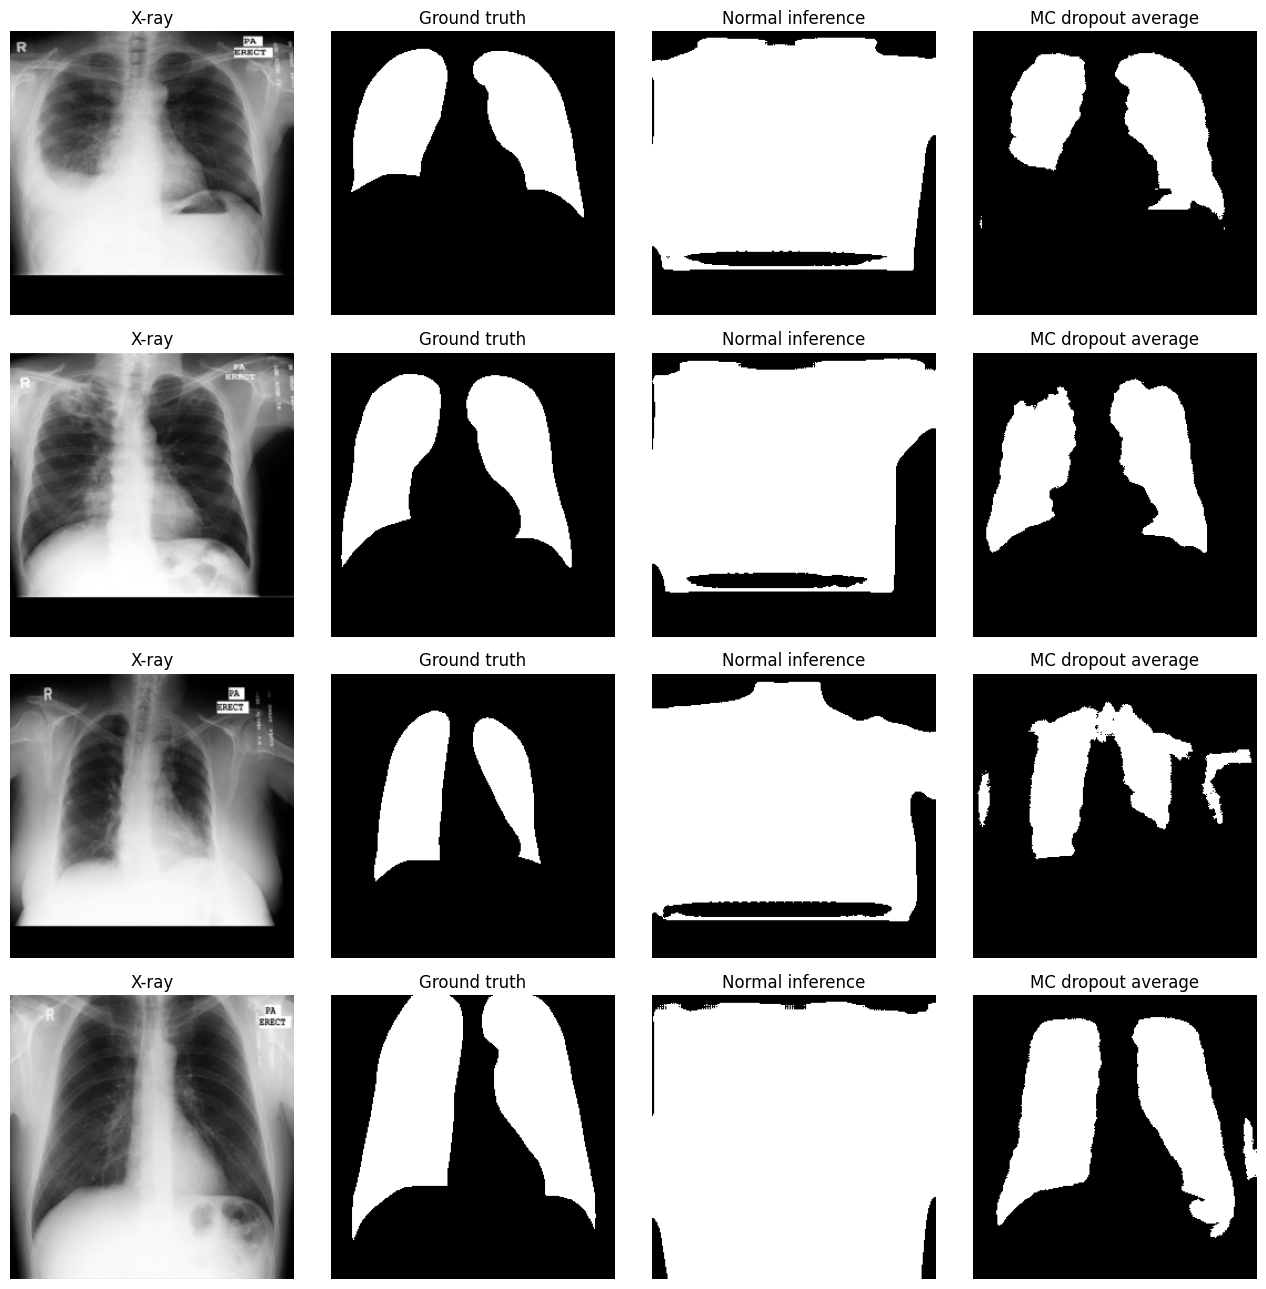

In [83]:
import matplotlib.pyplot as plt
import numpy as np

sample_indices = [0, 1, 2, 3]

fig, axes = plt.subplots(4, 4, figsize=(13, 13))

for row, idx in enumerate(sample_indices):
    xray = X_val[idx].squeeze()
    gt = Y_val[idx].squeeze()

    normal = standard_probs[idx].squeeze()
    mc = viz_mc_probs[idx].squeeze()

    axes[row, 0].imshow(xray, cmap="gray")
    axes[row, 0].set_title("X-ray")

    axes[row, 1].imshow(gt, cmap="gray")
    axes[row, 1].set_title("Ground truth")

    axes[row, 2].imshow(normal >= 0.5, cmap="gray")
    axes[row, 2].set_title("Normal inference")

    axes[row, 3].imshow(mc >= 0.5, cmap="gray")
    axes[row, 3].set_title("MC dropout average")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

Inspect the model's dropout and other layers

In [84]:
import tensorflow as tf
from collections import Counter

print("Model:", baseline_model.name)
print("Total parameters:", baseline_model.count_params())
print("Output shape:", baseline_model.output_shape)

layer_counts = Counter(type(layer).__name__ for layer in baseline_model.layers)

print("\n=== Layer type counts ===")
for layer_type, count in sorted(layer_counts.items()):
    print(f"{layer_type}: {count}")

print("\n=== Dropout layers ===")
for layer in baseline_model.layers:
    if isinstance(layer, tf.keras.layers.Dropout):
        print(
            f"{layer.name}: "
            f"rate={layer.rate}, "
            f"trainable={layer.trainable}"
        )

print("\n=== Normalization layers ===")
for layer in baseline_model.layers:
    if isinstance(
        layer,
        (
            tf.keras.layers.BatchNormalization,
            tf.keras.layers.LayerNormalization,
        ),
    ):
        print(f"{layer.name}: {type(layer).__name__}")

Model: functional
Total parameters: 9041601
Output shape: (None, 256, 256, 1)

=== Layer type counts ===
Concatenate: 10
Conv2D: 31
Conv2DTranspose: 10
Dropout: 30
InputLayer: 1
MaxPooling2D: 4

=== Dropout layers ===
dp11_1: rate=0.5, trainable=True
dp11_2: rate=0.5, trainable=True
dp21_1: rate=0.5, trainable=True
dp21_2: rate=0.5, trainable=True
dp31_1: rate=0.5, trainable=True
dp31_2: rate=0.5, trainable=True
dp41_1: rate=0.5, trainable=True
dp41_2: rate=0.5, trainable=True
dp51_1: rate=0.5, trainable=True
dp51_2: rate=0.5, trainable=True
dp42_1: rate=0.5, trainable=True
dp32_1: rate=0.5, trainable=True
dp42_2: rate=0.5, trainable=True
dp22_1: rate=0.5, trainable=True
dp32_2: rate=0.5, trainable=True
dp12_1: rate=0.5, trainable=True
dp22_2: rate=0.5, trainable=True
dp12_2: rate=0.5, trainable=True
dp33_1: rate=0.5, trainable=True
dp23_1: rate=0.5, trainable=True
dp33_2: rate=0.5, trainable=True
dp13_1: rate=0.5, trainable=True
dp23_2: rate=0.5, trainable=True
dp13_2: rate=0.5, train

Compare standard inference vs MC dropout on validation

In [85]:
import numpy as np

def calculate_metrics(y_true, y_prob, threshold=0.5):
    y_true = (y_true > 0.5).astype(np.float32).ravel()
    y_pred = (y_prob >= threshold).astype(np.float32).ravel()

    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))

    dice = (2 * tp) / max(2 * tp + fp + fn, 1)
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)

    return dice, precision, recall, y_pred.mean(), y_true.mean()


# Standard inference: dropout OFF
standard_probs = baseline_model.predict(X_val, verbose=0)

# MC dropout: dropout ON, average 20 passes
mc_predictions = np.stack([
    baseline_model(X_val, training=True).numpy()
    for _ in range(20)
], axis=0)

mc_probs = mc_predictions.mean(axis=0)

for name, probs in [
    ("Standard inference", standard_probs),
    ("MC dropout (20 passes)", mc_probs),
]:
    dice, precision, recall, pred_fg, true_fg = calculate_metrics(
        Y_val, probs
    )

    print(f"\n{name}")
    print(f"Pooled Dice:          {dice:.4f}")
    print(f"Precision:            {precision:.4f}")
    print(f"Recall:               {recall:.4f}")
    print(f"Predicted foreground: {pred_fg:.4f}")
    print(f"Ground-truth foreground: {true_fg:.4f}")


Standard inference
Pooled Dice:          0.5287
Precision:            0.3597
Recall:               0.9970
Predicted foreground: 0.7073
Ground-truth foreground: 0.2552

MC dropout (20 passes)
Pooled Dice:          0.8585
Precision:            0.9439
Recall:               0.7872
Predicted foreground: 0.2129
Ground-truth foreground: 0.2552


In [86]:
import numpy as np

y_true = (Y_val.squeeze(-1) >= 0.5)
y_pred = (mc_probs.squeeze(-1) >= 0.5)

print("Image | Dice   | IoU")
print("-" * 26)

dice_scores = []
iou_scores = []

for i in range(len(y_true)):
    gt = y_true[i]
    pred = y_pred[i]

    intersection = np.logical_and(gt, pred).sum()
    union = np.logical_or(gt, pred).sum()

    dice = (2 * intersection) / max(gt.sum() + pred.sum(), 1)
    iou = intersection / max(union, 1)

    dice_scores.append(dice)
    iou_scores.append(iou)

    print(f"{i+1:5d} | {dice:.4f} | {iou:.4f}")

print("-" * 26)
print(f"Mean Dice: {np.mean(dice_scores):.4f}")
print(f"Mean IoU:  {np.mean(iou_scores):.4f}")
print(f"Min Dice:  {np.min(dice_scores):.4f}")
print(f"Max Dice:  {np.max(dice_scores):.4f}")

Image | Dice   | IoU
--------------------------
    1 | 0.8684 | 0.7675
    2 | 0.8818 | 0.7886
    3 | 0.7696 | 0.6255
    4 | 0.8613 | 0.7565
    5 | 0.8614 | 0.7565
    6 | 0.8675 | 0.7660
    7 | 0.8637 | 0.7601
    8 | 0.8556 | 0.7477
    9 | 0.8438 | 0.7298
   10 | 0.8611 | 0.7561
   11 | 0.8712 | 0.7718
   12 | 0.8325 | 0.7131
   13 | 0.8874 | 0.7976
--------------------------
Mean Dice: 0.8558
Mean IoU:  0.7490
Min Dice:  0.7696
Max Dice:  0.8874


MC dropout's reproducibility check

In [87]:
import numpy as np

def pooled_dice_score(y_true, y_prob, threshold=0.5):
    gt = (y_true >= 0.5).astype(bool)
    pred = (y_prob >= threshold)

    tp = np.logical_and(gt, pred).sum()
    fp = np.logical_and(~gt, pred).sum()
    fn = np.logical_and(gt, ~pred).sum()

    return (2 * tp) / max(2 * tp + fp + fn, 1)


# Three independent MC-dropout trials, 20 passes per trial
trial_results = []

for trial in range(3):
    pass_predictions = np.stack([
        baseline_model(X_val, training=True).numpy()
        for _ in range(20)
    ], axis=0)

    mean_prob = pass_predictions.mean(axis=0)
    dice = pooled_dice_score(Y_val, mean_prob)

    trial_results.append(dice)
    print(f"Trial {trial + 1}: Pooled Dice = {dice:.4f}")

print("\n=== Reproducibility Summary ===")
print(f"Mean Dice: {np.mean(trial_results):.4f}")
print(f"Std. deviation: {np.std(trial_results):.4f}")
print(f"Range: {min(trial_results):.4f} - {max(trial_results):.4f}")

Trial 1: Pooled Dice = 0.8589
Trial 2: Pooled Dice = 0.8595
Trial 3: Pooled Dice = 0.8596

=== Reproducibility Summary ===
Mean Dice: 0.8593
Std. deviation: 0.0003
Range: 0.8589 - 0.8596


Save the results properly

In [88]:
import os
import json
import numpy as np
import pandas as pd
from datetime import datetime

# Save under the existing UNet++ experiment directory
save_dir = (
    "/content/drive/MyDrive/Lung_Segmentation_Research/"
    "UNetPlusPlus/experiments/experiment_04_mc_dropout"
)
os.makedirs(save_dir, exist_ok=True)

# Final validation MC-dropout predictions: 20 passes
mc_stack_final = np.stack([
    baseline_model(X_val, training=True).numpy()
    for _ in range(20)
], axis=0)

mc_mean_final = mc_stack_final.mean(axis=0)
mc_std_final = mc_stack_final.std(axis=0)

# Calculate per-image metrics
rows = []

for i in range(len(Y_val)):
    gt = Y_val[i].squeeze() >= 0.5
    pred = mc_mean_final[i].squeeze() >= 0.5

    tp = np.logical_and(gt, pred).sum()
    fp = np.logical_and(~gt, pred).sum()
    fn = np.logical_and(gt, ~pred).sum()

    dice = 2 * tp / max(2 * tp + fp + fn, 1)
    iou = tp / max(tp + fp + fn, 1)
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)

    rows.append({
        "image_index": i + 1,
        "dice": dice,
        "iou": iou,
        "precision": precision,
        "recall": recall
    })

df = pd.DataFrame(rows)
df.to_csv(os.path.join(save_dir, "validation_per_image.csv"), index=False)

# Save predictions and uncertainty for future visualization
np.save(os.path.join(save_dir, "mc_mean_probabilities.npy"), mc_mean_final)
np.save(os.path.join(save_dir, "mc_std_probabilities.npy"), mc_std_final)

summary = {
    "model": "UNet++",
    "inference_method": "Monte Carlo dropout",
    "mc_passes": 20,
    "threshold": 0.5,
    "validation_images": int(len(Y_val)),
    "mean_per_image_dice": float(df["dice"].mean()),
    "mean_per_image_iou": float(df["iou"].mean()),
    "mean_per_image_precision": float(df["precision"].mean()),
    "mean_per_image_recall": float(df["recall"].mean()),
    "pooled_dice": float(
        2 * np.logical_and(
            Y_val.squeeze() >= 0.5,
            mc_mean_final.squeeze() >= 0.5
        ).sum()
        / max(
            (Y_val.squeeze() >= 0.5).sum()
            + (mc_mean_final.squeeze() >= 0.5).sum(),
            1
        )
    ),
    "note": "Validation results only; not final test-set results."
}

with open(os.path.join(save_dir, "validation_summary.json"), "w") as f:
    json.dump(summary, f, indent=2)

print("Saved validation artifacts to:")
print(save_dir)
print("\nSummary:")
for key, value in summary.items():
    print(f"{key}: {value}")

Saved validation artifacts to:
/content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus/experiments/experiment_04_mc_dropout

Summary:
model: UNet++
inference_method: Monte Carlo dropout
mc_passes: 20
threshold: 0.5
validation_images: 13
mean_per_image_dice: 0.8571135766033355
mean_per_image_iou: 0.7508925716773779
mean_per_image_precision: 0.9468044803339505
mean_per_image_recall: 0.7859766730770039
pooled_dice: 0.8597261896992304
note: Validation results only; not final test-set results.


In [89]:
import os

checkpoint_path = (
    "/content/drive/MyDrive/Lung_Segmentation_Research/"
    "UNetPlusPlus/checkpoints/run_20261022_090555/best_model.keras"
)

print("Expected checkpoint exists:", os.path.isfile(checkpoint_path))
print("Checkpoint size (MB):", round(
    os.path.getsize(checkpoint_path) / (1024 ** 2), 2
) if os.path.isfile(checkpoint_path) else "Not found")

print("\nLoaded model parameters:", baseline_model.count_params())
print("Loaded model output shape:", baseline_model.output_shape)

Expected checkpoint exists: True
Checkpoint size (MB): 103.8

Loaded model parameters: 9041601
Loaded model output shape: (None, 256, 256, 1)


In [90]:
import tensorflow as tf
import numpy as np

checkpoint_path = (
    "/content/drive/MyDrive/Lung_Segmentation_Research/"
    "UNetPlusPlus/checkpoints/run_20261022_090555/best_model.keras"
)

saved_model = tf.keras.models.load_model(
    checkpoint_path,
    compile=False
)

loaded_weights = baseline_model.get_weights()
saved_weights = saved_model.get_weights()

print("Same number of weight arrays:",
      len(loaded_weights) == len(saved_weights))

if len(loaded_weights) == len(saved_weights):
    exact_match = all(
        np.array_equal(a, b)
        for a, b in zip(loaded_weights, saved_weights)
    )

    max_difference = max(
        (float(np.max(np.abs(a - b))) if a.size else 0.0)
        for a, b in zip(loaded_weights, saved_weights)
    )

    print("Exact weight match:", exact_match)
    print("Maximum absolute weight difference:", max_difference)
else:
    print("Weight-array counts differ; investigate before proceeding.")

Same number of weight arrays: True
Exact weight match: True
Maximum absolute weight difference: 0.0


In [91]:
import os
import json
import numpy as np
import pandas as pd

save_dir = (
    "/content/drive/MyDrive/Lung_Segmentation_Research/"
    "UNetPlusPlus/experiments/experiment_04_mc_dropout"
)
os.makedirs(save_dir, exist_ok=True)

def evaluate_predictions(y_true, y_prob, threshold=0.5):
    gt = y_true.squeeze() >= 0.5
    pred = y_prob.squeeze() >= threshold

    tp = np.logical_and(gt, pred).sum()
    fp = np.logical_and(~gt, pred).sum()
    fn = np.logical_and(gt, ~pred).sum()
    tn = np.logical_and(~gt, ~pred).sum()

    return {
        "pooled_dice": float(2 * tp / max(2 * tp + fp + fn, 1)),
        "mean_image_dice": float(np.mean([
            2 * np.logical_and(g, p).sum()
            / max(g.sum() + p.sum(), 1)
            for g, p in zip(gt, pred)
        ])),
        "mean_image_iou": float(np.mean([
            np.logical_and(g, p).sum()
            / max(np.logical_or(g, p).sum(), 1)
            for g, p in zip(gt, pred)
        ])),
        "pooled_precision": float(tp / max(tp + fp, 1)),
        "pooled_recall": float(tp / max(tp + fn, 1)),
        "predicted_foreground_fraction": float(pred.mean()),
        "ground_truth_foreground_fraction": float(gt.mean()),
        "true_positive_pixels": int(tp),
        "false_positive_pixels": int(fp),
        "false_negative_pixels": int(fn),
        "true_negative_pixels": int(tn),
    }

# Use the saved final MC mean for consistency with Experiment 04.
results = {
    "Standard inference": evaluate_predictions(Y_val, standard_probs),
    "MC dropout (20 passes)": evaluate_predictions(Y_val, mc_mean_final),
}

comparison = pd.DataFrame(results).T
comparison.to_csv(
    os.path.join(save_dir, "inference_protocol_comparison.csv")
)

with open(os.path.join(save_dir, "inference_protocol_comparison.json"), "w") as f:
    json.dump(results, f, indent=2)

print(comparison.round(4).to_string())
print("\nSaved comparison to:", save_dir)

                        pooled_dice  mean_image_dice  mean_image_iou  pooled_precision  pooled_recall  predicted_foreground_fraction  ground_truth_foreground_fraction  true_positive_pixels  false_positive_pixels  false_negative_pixels  true_negative_pixels
Standard inference           0.5287           0.5270          0.3592            0.3597         0.9970                         0.7073                            0.2552              216794.0               385832.0                  643.0              248699.0
MC dropout (20 passes)       0.8597           0.8571          0.7509            0.9464         0.7876                         0.2124                            0.2552              171248.0                 9693.0                46189.0              624838.0

Saved comparison to: /content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus/experiments/experiment_04_mc_dropout


In [92]:
import time
import numpy as np
import pandas as pd
import os

def pooled_dice(y_true, y_prob, threshold=0.5):
    gt = y_true >= 0.5
    pred = y_prob >= threshold

    tp = np.logical_and(gt, pred).sum()
    fp = np.logical_and(~gt, pred).sum()
    fn = np.logical_and(gt, ~pred).sum()

    return 2 * tp / max(2 * tp + fp + fn, 1)

# Generate 50 stochastic passes once, then compare cumulative averages.
start = time.time()
mc_passes = np.stack([
    baseline_model(X_val, training=True).numpy()
    for _ in range(50)
], axis=0)
elapsed = time.time() - start

results = []

for n in [20, 30, 50]:
    mean_prob = mc_passes[:n].mean(axis=0)

    results.append({
        "MC passes": n,
        "Pooled Dice": pooled_dice(Y_val, mean_prob),
        "Mean probability": float(mean_prob.mean()),
        "Predicted foreground": float((mean_prob >= 0.5).mean())
    })

comparison = pd.DataFrame(results)
print(comparison.round(4).to_string(index=False))
print(f"\nTotal time for 50 passes: {elapsed:.2f} seconds")

save_dir = (
    "/content/drive/MyDrive/Lung_Segmentation_Research/"
    "UNetPlusPlus/experiments/experiment_04_mc_dropout"
)
comparison.to_csv(
    os.path.join(save_dir, "mc_pass_count_comparison.csv"),
    index=False
)
print("Comparison CSV saved.")

 MC passes  Pooled Dice  Mean probability  Predicted foreground
        20       0.8590            0.2265                0.2124
        30       0.8592            0.2265                0.2124
        50       0.8589            0.2266                0.2125

Total time for 50 passes: 23.75 seconds
Comparison CSV saved.


Visualize predictions and uncertainty

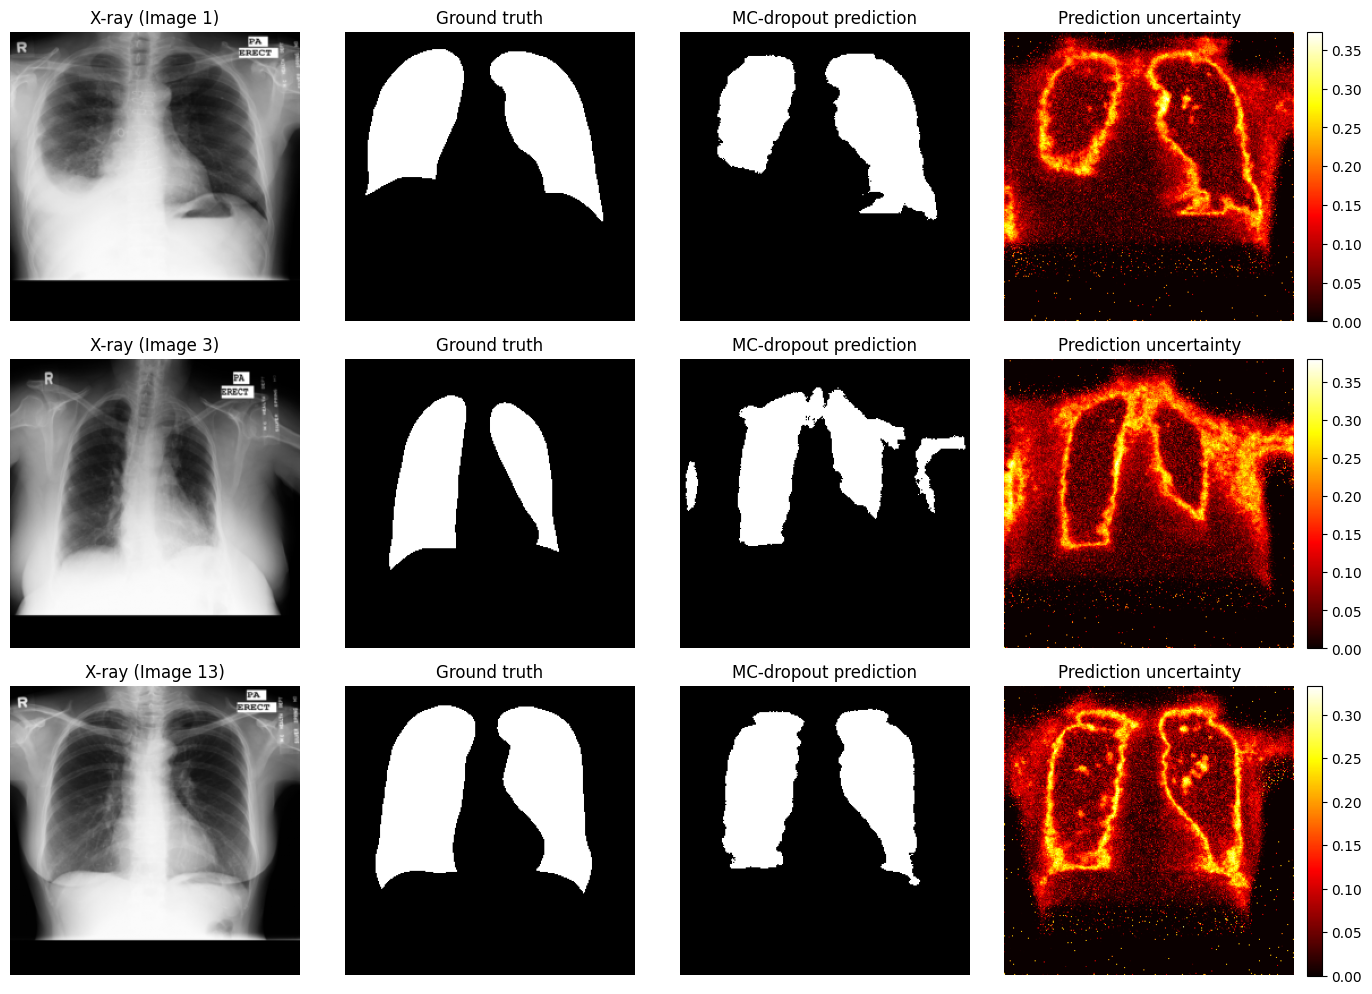

Mean pixel uncertainty: 0.05493009462952614
Maximum pixel uncertainty: 0.4469924867153168


In [93]:
import os
import numpy as np
import matplotlib.pyplot as plt

save_dir = (
    "/content/drive/MyDrive/Lung_Segmentation_Research/"
    "UNetPlusPlus/experiments/experiment_04_mc_dropout"
)

mc_mean = np.load(
    os.path.join(save_dir, "mc_mean_probabilities.npy")
)
mc_std = np.load(
    os.path.join(save_dir, "mc_std_probabilities.npy")
)

indices = [0, 2, 12]  # Validation images 1, 3, and 13

fig, axes = plt.subplots(len(indices), 4, figsize=(14, 10))

for row, idx in enumerate(indices):
    xray = X_val[idx].squeeze()
    gt = Y_val[idx].squeeze() >= 0.5
    pred = mc_mean[idx].squeeze() >= 0.5
    uncertainty = mc_std[idx].squeeze()

    axes[row, 0].imshow(xray, cmap="gray")
    axes[row, 0].set_title(f"X-ray (Image {idx+1})")

    axes[row, 1].imshow(gt, cmap="gray")
    axes[row, 1].set_title("Ground truth")

    axes[row, 2].imshow(pred, cmap="gray")
    axes[row, 2].set_title("MC-dropout prediction")

    im = axes[row, 3].imshow(uncertainty, cmap="hot")
    axes[row, 3].set_title("Prediction uncertainty")
    fig.colorbar(im, ax=axes[row, 3], fraction=0.046, pad=0.04)

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

print("Mean pixel uncertainty:", float(mc_std.mean()))
print("Maximum pixel uncertainty:", float(mc_std.max()))

final evaluation se pehle protocol save

In [94]:
import os
import json
from datetime import datetime

base_dir = (
    "/content/drive/MyDrive/Lung_Segmentation_Research/"
    "UNetPlusPlus"
)

experiment_dir = os.path.join(
    base_dir, "experiments", "experiment_04_mc_dropout"
)
os.makedirs(experiment_dir, exist_ok=True)

protocol = {
    "model": "UNet++",
    "architecture_changed": False,
    "checkpoint": os.path.join(
        base_dir,
        "checkpoints",
        "run_20261022_090555",
        "best_model.keras"
    ),
    "inference_method": "Monte Carlo dropout",
    "mc_passes": 20,
    "threshold": 0.5,
    "validation_images": int(len(X_val)),
    "test_images": int(len(X_test)),
    "test_set_used_for_tuning": False,
    "status": "Protocol candidate; test evaluation pending",
    "created_at": datetime.now().isoformat(timespec="seconds")
}

protocol_path = os.path.join(
    experiment_dir, "final_evaluation_protocol.json"
)

with open(protocol_path, "w") as f:
    json.dump(protocol, f, indent=2)

print("Protocol saved:", protocol_path)
print(json.dumps(protocol, indent=2))

Protocol saved: /content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus/experiments/experiment_04_mc_dropout/final_evaluation_protocol.json
{
  "model": "UNet++",
  "architecture_changed": false,
  "checkpoint": "/content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus/checkpoints/run_20261022_090555/best_model.keras",
  "inference_method": "Monte Carlo dropout",
  "mc_passes": 20,
  "threshold": 0.5,
  "validation_images": 13,
  "test_images": 15,
  "test_set_used_for_tuning": false,
  "status": "Protocol candidate; test evaluation pending",
  "created_at": "2026-10-22T11:57:25"
}


Final test evaluation

In [95]:
import os
import json
import time
import numpy as np
import pandas as pd
import tensorflow as tf

base_dir = (
    "/content/drive/MyDrive/Lung_Segmentation_Research/"
    "UNetPlusPlus"
)
checkpoint_path = os.path.join(
    base_dir, "checkpoints", "run_20261022_090555",
    "best_model.keras"
)
save_dir = os.path.join(
    base_dir, "experiments", "experiment_04_mc_dropout"
)

# Load the exact saved checkpoint
test_model = tf.keras.models.load_model(
    checkpoint_path, compile=False
)

assert test_model.count_params() == 9041601
assert test_model.output_shape == (None, 256, 256, 1)
assert len(X_test) == len(Y_test) == 15

# Run 20 stochastic forward passes on the held-out test set
start = time.time()
test_passes = np.stack([
    test_model(X_test, training=True).numpy()
    for _ in range(20)
], axis=0)
test_probs = test_passes.mean(axis=0)
elapsed = time.time() - start

# Compute per-image metrics
rows = []
for i in range(len(Y_test)):
    gt = Y_test[i].squeeze() >= 0.5
    pred = test_probs[i].squeeze() >= 0.5

    tp = np.logical_and(gt, pred).sum()
    fp = np.logical_and(~gt, pred).sum()
    fn = np.logical_and(gt, ~pred).sum()
    tn = np.logical_and(~gt, ~pred).sum()

    rows.append({
        "image_index": i + 1,
        "dice": 2 * tp / max(2 * tp + fp + fn, 1),
        "iou": tp / max(tp + fp + fn, 1),
        "precision": tp / max(tp + fp, 1),
        "recall": tp / max(tp + fn, 1),
        "tp": int(tp),
        "fp": int(fp),
        "fn": int(fn),
        "tn": int(tn)
    })

df = pd.DataFrame(rows)
df.to_csv(os.path.join(save_dir, "test_per_image.csv"), index=False)

# Pooled metrics from all test pixels
totals = {k: int(df[k].sum()) for k in ["tp", "fp", "fn", "tn"]}
tp, fp, fn = totals["tp"], totals["fp"], totals["fn"]

summary = {
    "model": "UNet++",
    "checkpoint": checkpoint_path,
    "inference_method": "MC dropout",
    "mc_passes": 20,
    "threshold": 0.5,
    "test_images": int(len(Y_test)),
    "pooled_dice": float(2 * tp / max(2 * tp + fp + fn, 1)),
    "mean_image_dice": float(df["dice"].mean()),
    "mean_image_iou": float(df["iou"].mean()),
    "pooled_precision": float(tp / max(tp + fp, 1)),
    "pooled_recall": float(tp / max(tp + fn, 1)),
    "predicted_foreground_fraction": float(
        (test_probs >= 0.5).mean()
    ),
    "ground_truth_foreground_fraction": float(
        (Y_test >= 0.5).mean()
    ),
    "true_positive_pixels": tp,
    "false_positive_pixels": fp,
    "false_negative_pixels": fn,
    "true_negative_pixels": totals["tn"],
    "inference_time_seconds": round(elapsed, 2),
    "note": "Held-out test results; protocol fixed before evaluation."
}

with open(os.path.join(save_dir, "test_summary.json"), "w") as f:
    json.dump(summary, f, indent=2)

np.save(os.path.join(save_dir, "test_mc_mean_probabilities.npy"), test_probs)

print("=== FINAL UNET++ TEST RESULTS ===")
for key, value in summary.items():
    print(f"{key}: {value}")

print("\nSaved test artifacts to:", save_dir)

=== FINAL UNET++ TEST RESULTS ===
model: UNet++
checkpoint: /content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus/checkpoints/run_20261022_090555/best_model.keras
inference_method: MC dropout
mc_passes: 20
threshold: 0.5
test_images: 15
pooled_dice: 0.8734771150432958
mean_image_dice: 0.8700989531274901
mean_image_iou: 0.7713736152422598
pooled_precision: 0.9748328915523798
pooled_recall: 0.7912127743328513
predicted_foreground_fraction: 0.2118408203125
ground_truth_foreground_fraction: 0.26100362141927086
true_positive_pixels: 203007
false_positive_pixels: 5241
false_negative_pixels: 53570
true_negative_pixels: 721222
inference_time_seconds: 12.13
note: Held-out test results; protocol fixed before evaluation.

Saved test artifacts to: /content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus/experiments/experiment_04_mc_dropout


In [96]:
import os
import json
import numpy as np
import pandas as pd

BASE = (
    "/content/drive/MyDrive/Lung_Segmentation_Research/"
    "UNetPlusPlus"
)
EXP = os.path.join(BASE, "experiments", "experiment_04_mc_dropout")

# Load saved predictions and masks
test_probs = np.load(
    os.path.join(EXP, "test_mc_mean_probabilities.npy")
)
val_probs = np.load(
    os.path.join(EXP, "mc_mean_probabilities.npy")
)

def segmentation_metrics(y_true, y_prob, threshold=0.5):
    gt = y_true.squeeze() >= 0.5
    pred = y_prob.squeeze() >= threshold

    tp = np.logical_and(gt, pred).sum()
    fp = np.logical_and(~gt, pred).sum()
    fn = np.logical_and(gt, ~pred).sum()
    tn = np.logical_and(~gt, ~pred).sum()

    dice = 2 * tp / max(2 * tp + fp + fn, 1)
    iou = tp / max(tp + fp + fn, 1)
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)

    return {
        "Pooled Dice": dice,
        "Mean image Dice": np.mean([
            2 * np.logical_and(g, p).sum()
            / max(g.sum() + p.sum(), 1)
            for g, p in zip(gt, pred)
        ]),
        "Mean image IoU": np.mean([
            np.logical_and(g, p).sum()
            / max(np.logical_or(g, p).sum(), 1)
            for g, p in zip(gt, pred)
        ]),
        "Pooled IoU": tp / max(tp + fp + fn, 1),
        "Precision": precision,
        "Recall": recall,
        "F1 Score": dice,
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn),
        "Predicted foreground (%)": 100 * pred.mean(),
        "Ground-truth foreground (%)": 100 * gt.mean()
    }

# Use existing notebook masks; no test-set tuning
results = {
    "Validation": segmentation_metrics(Y_val, val_probs),
    "Test": segmentation_metrics(Y_test, test_probs)
}

table = pd.DataFrame(results).T
display(table.round(4))

# Save combined metrics
table.to_csv(os.path.join(EXP, "combined_metrics.csv"))

with open(os.path.join(EXP, "combined_metrics.json"), "w") as f:
    json.dump(results, f, indent=2)

print("\nSaved:", os.path.join(EXP, "combined_metrics.csv"))
print("Saved:", os.path.join(EXP, "combined_metrics.json"))

# Training history: load if available
history_path = os.path.join(
    BASE, "logs", "training_history_20261022_090555.csv"
)

if os.path.exists(history_path):
    history = pd.read_csv(history_path)
    print("\nTraining history columns:")
    print(history.columns.tolist())
    display(history.tail())
else:
    print("\nTraining history CSV not found at:", history_path)

,Pooled Dice,Mean image Dice,Mean image IoU,Pooled IoU,Precision,Recall,F1 Score,TP,FP,FN,TN,Predicted foreground (%),Ground-truth foreground (%)
Validation,0.8597,0.8571,0.7509,0.7540,0.9464,0.7876,0.8597,171248.0,9693.0,46189.0,624838.0,21.2380,25.5217
Test,0.8735,0.8701,0.7714,0.7754,0.9748,0.7912,0.8735,203007.0,5241.0,53570.0,721222.0,21.1841,26.1004



Saved: /content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus/experiments/experiment_04_mc_dropout/combined_metrics.csv
Saved: /content/drive/MyDrive/Lung_Segmentation_Research/UNetPlusPlus/experiments/experiment_04_mc_dropout/combined_metrics.json

Training history columns:
['binary_accuracy', 'dice_coefficient', 'epoch', 'loss', 'precision', 'recall', 'val_binary_accuracy', 'val_dice_coefficient', 'val_loss', 'val_precision', 'val_recall']


,binary_accuracy,dice_coefficient,epoch,loss,precision,recall,val_binary_accuracy,val_dice_coefficient,val_loss,val_precision,val_recall
15,0.948575,0.855128,16,0.814393,0.936797,0.855873,0.502539,0.518366,3.924099,0.338997,0.999250
16,0.950139,0.860947,17,0.792508,0.940099,0.859001,0.509823,0.520472,4.072494,0.342328,0.999402
17,0.951002,0.862637,18,0.772744,0.937134,0.865731,0.538093,0.530225,3.607343,0.355831,0.999425
18,0.951308,0.868859,19,0.757148,0.936958,0.867207,0.533850,0.527282,3.701530,0.353795,0.999986
19,0.953129,0.868659,20,0.740879,0.940173,0.871460,0.508259,0.515477,4.083101,0.341671,0.999963
